# 06 — Model Interpretation, Scoring & Deployment

This notebook contains the model-selection evidence, feature importance, permutation importance, error analysis, threshold analysis, current-customer scoring, neural-network comparison and deployment/API validation extracted from the validated Phase 7–9 final notebook. It is a documentation/analysis continuation of the modeling workflow and preserves the executed outputs.

In [ ]:
 # ============================================================
# PHASE 7: EXPLORATORY DATA ANALYSIS, RFM & CHURN ANALYSIS
# Meridian Retail Group Customer Churn Capstone
# ============================================================
#
# BUSINESS OBJECTIVE
# ------------------------------------------------------------
# Understand customer behaviour, purchasing patterns,
# customer segments, and support experience in order to
# investigate customer churn at Meridian Retail Group.
#
# PHASE 7 MANDATORY REQUIREMENTS
# ------------------------------------------------------------
# 1. Compute and interpret overall churn rate.
# 2. Compute and interpret churn by:
#       - Membership tier
#       - Preferred channel
#       - State
#       - Referral source
#       - Signup cohort
# 3. Engineer customer-level RFM features:
#       - Recency
#       - Frequency
#       - Monetary
# 4. Investigate support-ticket activity and its relationship
#    with churn:
#       - Ticket count
#       - Satisfaction score
#       - Resolution time
# 5. Perform univariate analysis.
# 6. Perform multivariate analysis.
# 7. Identify at least five concrete, non-obvious findings.
#
# LOCKED CHURN DEFINITION
# ------------------------------------------------------------
# Snapshot date: 2026-07-01
#
# A customer is CHURNED if they have NO order with
# status = 'Completed' during the preceding 180 days.
#
# This includes customers who have never ordered.
#
# Otherwise, the customer is ACTIVE.
#
# IMPORTANT:
# Completed orders occurring AFTER 2026-07-01 must not be
# used when determining churn status at the snapshot date.
#
# SOURCE OF TRUTH
# ------------------------------------------------------------
# The validated processed datasets created in Phase 6
# will be used for this analysis.
#
# Phase 6 final validation:
# Customers       = 6,090
# Products        =   220
# Orders          = 28,252
# Order Items     = 73,405
# Support Tickets =  5,200
#
# Phase 6 validation result: PASS
# ============================================================

print("PHASE 7: EDA, RFM & CHURN ANALYSIS")
print("=" * 80)
print("Meridian Retail Group")
print("=" * 80)

print("\nBusiness Objective:")
print(
    "Understand customer behaviour, purchasing patterns, "
    "support experience and churn characteristics."
)

print("\nChurn Snapshot Date: 2026-07-01")
print("Churn Window: 180 days")
print("Churn Definition: No completed order in preceding 180 days")

print("\nPhase 6 Source Data:")
print("- Customers:       6,090")
print("- Products:          220")
print("- Orders:         28,252")
print("- Order Items:    73,405")
print("- Support Tickets: 5,200")

print("\nPhase 6 Validation: PASS")
print("=" * 80)

PHASE 7: EDA, RFM & CHURN ANALYSIS
Meridian Retail Group

Business Objective:
Understand customer behaviour, purchasing patterns, support experience and churn characteristics.

Churn Snapshot Date: 2026-07-01
Churn Window: 180 days
Churn Definition: No completed order in preceding 180 days

Phase 6 Source Data:
- Customers:       6,090
- Products:          220
- Orders:         28,252
- Order Items:    73,405
- Support Tickets: 5,200

Phase 6 Validation: PASS


In [ ]:
# ============================================================
# CELL 2: IMPORT LIBRARIES AND SET PROJECT PATHS
# ============================================================
#
# Purpose:
# 1. Import the Python libraries required for Phase 7.
# 2. Mount Google Drive.
# 3. Define the project and processed-data paths.
#
# Libraries:
# - pandas: data loading, cleaning and analysis
# - numpy: numerical calculations
# - matplotlib: static visualizations
# - seaborn: statistical visualizations
# - plotly: interactive visualizations
#
# NOTE:
# The processed CSV files created and validated in Phase 6
# are the source of truth for this phase.
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path


# -----------------------------
# 2. MOUNT GOOGLE DRIVE
# -----------------------------

from google.colab import drive

drive.mount('/content/drive')


# -----------------------------
# 3. DEFINE PROJECT PATHS
# -----------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/PORA Capstone"
)

PROCESSED_PATH = (
    PROJECT_PATH / "data" / "processed"
)


# -----------------------------
# 4. DISPLAY PATH INFORMATION
# -----------------------------

print("=" * 80)
print("PHASE 7 ENVIRONMENT SETUP")
print("=" * 80)

print("\nProject path:")
print(PROJECT_PATH)

print("\nProcessed data path:")
print(PROCESSED_PATH)

print("\nProcessed directory exists:",
      PROCESSED_PATH.exists())

print("Processed directory is a folder:",
      PROCESSED_PATH.is_dir())


# -----------------------------
# 5. DISPLAY LIBRARY VERSIONS
# -----------------------------

print("\nLIBRARY VERSIONS")
print("-" * 80)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Plotly:", px.__version__ if hasattr(px, "__version__") else "Installed")

Mounted at /content/drive
PHASE 7 ENVIRONMENT SETUP

Project path:
/content/drive/MyDrive/PORA Capstone

Processed data path:
/content/drive/MyDrive/PORA Capstone/data/processed

Processed directory exists: True
Processed directory is a folder: True

LIBRARY VERSIONS
--------------------------------------------------------------------------------
Pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Plotly: Installed


In [ ]:
# ============================================================
# CELL 3: VERIFY PROCESSED DATASET FILES
# ============================================================
#
# Purpose:
# Confirm that all five validated Phase 6 processed CSV files
# exist in the expected directory before analysis begins.
#
# Expected files:
# - customers_clean.csv
# - products_clean.csv
# - orders_clean.csv
# - order_items_clean.csv
# - support_tickets_clean.csv
#
# This prevents accidental use of raw or outdated datasets.
# ============================================================

print("=" * 80)
print("PHASE 7 PROCESSED DATASET FILE VERIFICATION")
print("=" * 80)

# Expected processed files
expected_files = {
    "Customers": "customers_clean.csv",
    "Products": "products_clean.csv",
    "Orders": "orders_clean.csv",
    "Order Items": "order_items_clean.csv",
    "Support Tickets": "support_tickets_clean.csv"
}

file_checks = []

for dataset_name, filename in expected_files.items():

    file_path = PROCESSED_PATH / filename

    exists = file_path.exists()

    file_checks.append(exists)

    print(
        f"{dataset_name:<20} | "
        f"{filename:<30} | "
        f"{'FOUND' if exists else 'MISSING'}"
    )

print("\n" + "-" * 80)

if all(file_checks):
    print("RESULT: PASS")
    print("All five validated processed datasets are available.")
else:
    print("RESULT: REVIEW REQUIRED")
    print("One or more processed datasets could not be found.")

print("=" * 80)

PHASE 7 PROCESSED DATASET FILE VERIFICATION
Customers            | customers_clean.csv            | FOUND
Products             | products_clean.csv             | FOUND
Orders               | orders_clean.csv               | FOUND
Order Items          | order_items_clean.csv          | FOUND
Support Tickets      | support_tickets_clean.csv      | FOUND

--------------------------------------------------------------------------------
RESULT: PASS
All five validated processed datasets are available.


In [ ]:
# ============================================================
# CELL 4: LOAD THE PROCESSED DATASETS
# ============================================================
#
# Purpose:
# Load the five validated Phase 6 datasets into Pandas
# DataFrames for Phase 7 analysis.
#
# Date columns are explicitly parsed during loading because
# CSV files do not preserve Pandas datetime dtypes.
#
# Date columns:
# - Customers: date_of_birth, signup_date
# - Products: launch_date
# - Orders: order_date
# - Support Tickets: ticket_date
# ============================================================

print("=" * 80)
print("LOADING PHASE 6 PROCESSED DATASETS")
print("=" * 80)


# ------------------------------------------------------------
# 1. CUSTOMERS
# ------------------------------------------------------------

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv",
    parse_dates=["date_of_birth", "signup_date"]
)


# ------------------------------------------------------------
# 2. PRODUCTS
# ------------------------------------------------------------

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv",
    parse_dates=["launch_date"]
)


# ------------------------------------------------------------
# 3. ORDERS
# ------------------------------------------------------------

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    parse_dates=["order_date"]
)


# ------------------------------------------------------------
# 4. ORDER ITEMS
# ------------------------------------------------------------

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv"
)


# ------------------------------------------------------------
# 5. SUPPORT TICKETS
# ------------------------------------------------------------

support_tickets = pd.read_csv(
    PROCESSED_PATH / "support_tickets_clean.csv",
    parse_dates=["ticket_date"]
)


# ------------------------------------------------------------
# 6. DISPLAY LOADED DATASET SHAPES
# ------------------------------------------------------------

print("\nDATASET SHAPES")
print("-" * 80)

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Support Tickets:", support_tickets.shape)


# ------------------------------------------------------------
# 7. CONFIRM DATE COLUMN TYPES
# ------------------------------------------------------------

print("\nDATE COLUMN DATA TYPES")
print("-" * 80)

print("customers.date_of_birth:",
      customers["date_of_birth"].dtype)

print("customers.signup_date:",
      customers["signup_date"].dtype)

print("products.launch_date:",
      products["launch_date"].dtype)

print("orders.order_date:",
      orders["order_date"].dtype)

print("support_tickets.ticket_date:",
      support_tickets["ticket_date"].dtype)


# ------------------------------------------------------------
# 8. BASIC LOAD VALIDATION
# ------------------------------------------------------------

expected_shapes = {
    "Customers": (6090, 14),
    "Products": (220, 9),
    "Orders": (28252, 9),
    "Order Items": (73405, 5),
    "Support Tickets": (5200, 8)
}

actual_shapes = {
    "Customers": customers.shape,
    "Products": products.shape,
    "Orders": orders.shape,
    "Order Items": order_items.shape,
    "Support Tickets": support_tickets.shape
}

print("\nSHAPE VALIDATION")
print("-" * 80)

load_checks = []

for dataset_name in expected_shapes:

    passed = (
        actual_shapes[dataset_name]
        == expected_shapes[dataset_name]
    )

    load_checks.append(passed)

    print(
        f"{dataset_name:<20} | "
        f"{'PASS' if passed else 'FAIL'} | "
        f"Expected: {expected_shapes[dataset_name]} | "
        f"Actual: {actual_shapes[dataset_name]}"
    )


# ------------------------------------------------------------
# 9. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)

if all(load_checks):
    print("LOAD RESULT: PASS")
    print("All five processed datasets loaded successfully.")
else:
    print("LOAD RESULT: REVIEW REQUIRED")

print("=" * 80)

LOADING PHASE 6 PROCESSED DATASETS

DATASET SHAPES
--------------------------------------------------------------------------------
Customers: (6090, 14)
Products: (220, 9)
Orders: (28252, 9)
Order Items: (73405, 5)
Support Tickets: (5200, 8)

DATE COLUMN DATA TYPES
--------------------------------------------------------------------------------
customers.date_of_birth: datetime64[ns]
customers.signup_date: datetime64[ns]
products.launch_date: datetime64[ns]
orders.order_date: datetime64[ns]
support_tickets.ticket_date: datetime64[ns]

SHAPE VALIDATION
--------------------------------------------------------------------------------
Customers            | PASS | Expected: (6090, 14) | Actual: (6090, 14)
Products             | PASS | Expected: (220, 9) | Actual: (220, 9)
Orders               | PASS | Expected: (28252, 9) | Actual: (28252, 9)
Order Items          | PASS | Expected: (73405, 5) | Actual: (73405, 5)
Support Tickets      | PASS | Expected: (5200, 8) | Actual: (5200, 8)

LOAD 

In [ ]:
# ============================================================
# CELL 35: ML TARGET DESIGN & LEAKAGE-SAFE PREDICTION FRAMEWORK
# Meridian Retail Group - Customer Churn Project
# ============================================================

print("=" * 70)
print("CELL 35: MACHINE LEARNING TARGET DESIGN")
print("=" * 70)

# ------------------------------------------------------------
# 1. IMPORTANT DISTINCTION
# ------------------------------------------------------------
# The official EDA/business churn definition remains LOCKED:
#
# Snapshot date: 2026-07-01
# Churn = no Completed order in the preceding 180 days.
#
# We will NOT replace or modify that definition.
#
# For Machine Learning, however, we need to predict FUTURE churn.
# Therefore, the model will learn from historical prediction dates
# where the future outcome is already known.

ML_SCORING_DATE = SNAPSHOT_DATE
ML_HORIZON_DAYS = 180

# The ML prediction target will be:
#
# ml_target = 1
#     if the customer has NO Completed order during the
#     180 days AFTER the prediction date.
#
# ml_target = 0
#     if the customer has at least one Completed order during
#     that future 180-day period.
#
# This makes the target genuinely forward-looking and prevents
# us from using the same information that defines current churn.

print("\nOFFICIAL BUSINESS / EDA CHURN DEFINITION")
print("-" * 50)
print(f"Snapshot date: {SNAPSHOT_DATE.date()}")
print(f"Lookback window: {CHURN_WINDOW_DAYS} days")
print("Churn = No Completed order in the preceding 180 days.")

print("\nMACHINE LEARNING PREDICTION TARGET")
print("-" * 50)
print(f"Prediction horizon: {ML_HORIZON_DAYS} days")
print("Target = Future 180-day churn")
print("1 = No Completed order in the following 180 days")
print("0 = At least one Completed order in the following 180 days")

# ------------------------------------------------------------
# 2. CHECK THE AVAILABLE ORDER DATE RANGE
# ------------------------------------------------------------
completed_orders = orders[
    orders["order_status"].eq("Completed")
].copy()

completed_orders = completed_orders.dropna(
    subset=["order_date", "customer_id"]
)

latest_completed_date = completed_orders["order_date"].max()
earliest_completed_date = completed_orders["order_date"].min()

print("\nCOMPLETED ORDER DATE RANGE")
print("-" * 50)
print(f"Earliest Completed order: {earliest_completed_date.date()}")
print(f"Latest Completed order:   {latest_completed_date.date()}")

# ------------------------------------------------------------
# 3. DETERMINE THE LATEST DATE WITH A FULL 180-DAY
#    FUTURE OUTCOME AVAILABLE
# ------------------------------------------------------------
latest_training_cutoff = (
    latest_completed_date -
    pd.Timedelta(days=ML_HORIZON_DAYS)
)

print("\nLEAKAGE-SAFE TRAINING DATE LIMIT")
print("-" * 50)
print(
    f"Latest possible historical prediction date with a full "
    f"{ML_HORIZON_DAYS}-day outcome: "
    f"{latest_training_cutoff.date()}"
)

# ------------------------------------------------------------
# 4. CURRENT SCORING POPULATION
# ------------------------------------------------------------
# The current EDA already identified customers who are Active
# at the official 2026-07-01 snapshot.
#
# These customers will eventually receive predicted probabilities
# of becoming churned during the NEXT 180 days.
#
# Their future outcome is not yet available in our dataset,
# so they are a scoring population rather than a labelled test set.

current_active_customers = customers_eda.loc[
    customers_eda["churn_status"].eq("Active"),
    "customer_id"
].unique()

print("\nCURRENT SCORING POPULATION")
print("-" * 50)
print(
    f"Active customers at {ML_SCORING_DATE.date()}: "
    f"{len(current_active_customers):,}"
)

# ------------------------------------------------------------
# 5. LEAKAGE CONTROL PRINCIPLE
# ------------------------------------------------------------
print("\nLEAKAGE CONTROL PRINCIPLE")
print("-" * 50)
print(
    "For every historical prediction date, features will use only "
    "information available ON or BEFORE that date."
)

print(
    "The ML target will use only Completed orders occurring AFTER "
    "the prediction date and within the following 180 days."
)

print(
    "This prevents future purchasing behaviour from leaking into "
    "the predictors."
)

# ------------------------------------------------------------
# 6. FINAL DESIGN CHECK
# ------------------------------------------------------------
assert ML_HORIZON_DAYS == 180
assert latest_completed_date > earliest_completed_date
assert len(current_active_customers) == 2018

print("\n" + "=" * 70)
print("CELL 35 RESULT: ML TARGET FRAMEWORK DEFINED")
print("=" * 70)

print("✓ Official 2026-07-01 EDA churn definition remains unchanged")
print("✓ ML target is forward-looking")
print("✓ Prediction horizon = 180 days")
print("✓ Historical training dates must have a complete future window")
print("✓ Current active customers will be the eventual scoring population")
print("✓ Leakage-control rule established")
print("=" * 70)

CELL 35: MACHINE LEARNING TARGET DESIGN

OFFICIAL BUSINESS / EDA CHURN DEFINITION
--------------------------------------------------
Snapshot date: 2026-07-01
Lookback window: 180 days
Churn = No Completed order in the preceding 180 days.

MACHINE LEARNING PREDICTION TARGET
--------------------------------------------------
Prediction horizon: 180 days
Target = Future 180-day churn
1 = No Completed order in the following 180 days
0 = At least one Completed order in the following 180 days

COMPLETED ORDER DATE RANGE
--------------------------------------------------
Earliest Completed order: 2020-09-15
Latest Completed order:   2026-07-03

LEAKAGE-SAFE TRAINING DATE LIMIT
--------------------------------------------------
Latest possible historical prediction date with a full 180-day outcome: 2026-01-04

CURRENT SCORING POPULATION
--------------------------------------------------
Active customers at 2026-07-01: 2,018

LEAKAGE CONTROL PRINCIPLE
------------------------------------------

In [ ]:
# ============================================================
# CELL 36: DEFINE HISTORICAL ML PREDICTION DATES
# ============================================================

print("=" * 70)
print("CELL 36: HISTORICAL ML PREDICTION DATES")
print("=" * 70)

# ------------------------------------------------------------
# 1. WHY USE MULTIPLE HISTORICAL PREDICTION DATES?
# ------------------------------------------------------------
# A single prediction date would give us only one snapshot
# of customer behaviour.
#
# Instead, we create repeated historical snapshots.
#
# At each prediction date:
#   - Features use information available up to that date.
#   - The next 180 days determine the ML target.
#
# This creates a more realistic training dataset while
# preserving temporal ordering and preventing leakage.

ML_FIRST_PREDICTION_DATE = pd.Timestamp("2021-07-01")

# We cannot use dates later than the latest date for which
# a complete 180-day future outcome is available.
ML_LAST_PREDICTION_DATE = latest_training_cutoff

# Generate monthly prediction dates.
ML_PREDICTION_DATES = pd.date_range(
    start=ML_FIRST_PREDICTION_DATE,
    end=ML_LAST_PREDICTION_DATE,
    freq="MS"
)

print("\nPREDICTION DATE RANGE")
print("-" * 50)
print(f"First prediction date: {ML_PREDICTION_DATES.min().date()}")
print(f"Last prediction date:  {ML_PREDICTION_DATES.max().date()}")
print(f"Number of prediction dates: {len(ML_PREDICTION_DATES):,}")

# ------------------------------------------------------------
# 2. CHECK THAT EVERY PREDICTION DATE HAS A FULL 180-DAY
#    FUTURE OUTCOME WINDOW
# ------------------------------------------------------------

future_end_dates = (
    ML_PREDICTION_DATES +
    pd.Timedelta(days=ML_HORIZON_DAYS)
)

prediction_date_check = pd.DataFrame({
    "prediction_date": ML_PREDICTION_DATES,
    "future_end_date": future_end_dates
})

prediction_date_check["has_complete_future_window"] = (
    prediction_date_check["future_end_date"]
    <= latest_completed_date
)

print("\nFUTURE OUTCOME WINDOW CHECK")
print("-" * 50)

print(
    prediction_date_check[
        "has_complete_future_window"
    ].value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 3. RETAIN ONLY FULLY OBSERVABLE TRAINING WINDOWS
# ------------------------------------------------------------

ML_PREDICTION_DATES = prediction_date_check.loc[
    prediction_date_check["has_complete_future_window"],
    "prediction_date"
].tolist()

print("\nFINAL HISTORICAL PREDICTION DATES")
print("-" * 50)
print(f"Usable prediction dates: {len(ML_PREDICTION_DATES):,}")
print(f"First usable date: {ML_PREDICTION_DATES[0].date()}")
print(f"Last usable date:  {ML_PREDICTION_DATES[-1].date()}")

# ------------------------------------------------------------
# 4. DISPLAY THE FIRST AND LAST FEW DATES
# ------------------------------------------------------------

print("\nFIRST 5 PREDICTION DATES")
print("-" * 50)

for date in ML_PREDICTION_DATES[:5]:
    print(date.date())

print("\nLAST 5 PREDICTION DATES")
print("-" * 50)

for date in ML_PREDICTION_DATES[-5:]:
    print(date.date())

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

assert len(ML_PREDICTION_DATES) > 0
assert all(
    date + pd.Timedelta(days=ML_HORIZON_DAYS)
    <= latest_completed_date
    for date in ML_PREDICTION_DATES
)

assert ML_PREDICTION_DATES[-1] <= ML_LAST_PREDICTION_DATE

print("\n" + "=" * 70)
print("CELL 36 RESULT: HISTORICAL PREDICTION DATES DEFINED")
print("=" * 70)

print("✓ Multiple historical snapshots will be used")
print("✓ Prediction dates are monthly")
print("✓ Every training date has a complete 180-day future window")
print("✓ Future outcome data will be available for every training snapshot")
print("✓ Temporal leakage control remains in place")
print("=" * 70)

CELL 36: HISTORICAL ML PREDICTION DATES

PREDICTION DATE RANGE
--------------------------------------------------
First prediction date: 2021-07-01
Last prediction date:  2026-01-01
Number of prediction dates: 55

FUTURE OUTCOME WINDOW CHECK
--------------------------------------------------
has_complete_future_window
True    55
Name: count, dtype: int64

FINAL HISTORICAL PREDICTION DATES
--------------------------------------------------
Usable prediction dates: 55
First usable date: 2021-07-01
Last usable date:  2026-01-01

FIRST 5 PREDICTION DATES
--------------------------------------------------
2021-07-01
2021-08-01
2021-09-01
2021-10-01
2021-11-01

LAST 5 PREDICTION DATES
--------------------------------------------------
2025-09-01
2025-10-01
2025-11-01
2025-12-01
2026-01-01

CELL 36 RESULT: HISTORICAL PREDICTION DATES DEFINED
✓ Multiple historical snapshots will be used
✓ Prediction dates are monthly
✓ Every training date has a complete 180-day future window
✓ Future outcome d

In [ ]:
# ============================================================
# CELL 37: BUILD AND VALIDATE HISTORICAL ML TARGET
# ============================================================

print("=" * 70)
print("CELL 37: HISTORICAL FUTURE-CHURN TARGET")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARE COMPLETED ORDERS FOR FUTURE-LABEL CALCULATION
# ------------------------------------------------------------
# Only Completed orders can count as evidence that a customer
# remained active.
#
# Orders that are Returned, Cancelled or Pending do not count.

completed_orders_ml = orders[
    orders["order_status"].eq("Completed")
].copy()

completed_orders_ml = completed_orders_ml.dropna(
    subset=["customer_id", "order_date"]
)

# Keep only the columns required for target construction.
completed_orders_ml = completed_orders_ml[
    ["customer_id", "order_date"]
].copy()

print("\nCOMPLETED ORDERS AVAILABLE FOR ML TARGET")
print("-" * 50)
print(f"Rows: {len(completed_orders_ml):,}")
print(
    f"Unique customers: "
    f"{completed_orders_ml['customer_id'].nunique():,}"
)
print(
    f"Date range: "
    f"{completed_orders_ml['order_date'].min().date()} "
    f"to "
    f"{completed_orders_ml['order_date'].max().date()}"
)

# ------------------------------------------------------------
# 2. CREATE CUSTOMER-PREDICTION-DATE BASE
# ------------------------------------------------------------
# A customer can appear at multiple prediction dates.
#
# However, we should only include a customer at a prediction
# date if the customer had already signed up by that date.
#
# This prevents us from creating artificial observations for
# customers who did not yet exist.

customer_base = customers[
    ["customer_id", "signup_date"]
].copy()

ml_target_rows = []

for prediction_date in ML_PREDICTION_DATES:

    # Customers who existed by the prediction date.
    eligible_customers = customer_base[
        customer_base["signup_date"] <= prediction_date
    ][["customer_id"]].copy()

    # Define the future 180-day window.
    future_start = prediction_date
    future_end = (
        prediction_date +
        pd.Timedelta(days=ML_HORIZON_DAYS)
    )

    # Completed orders strictly AFTER the prediction date
    # and ON/BEFORE the end of the future window.
    future_orders = completed_orders_ml[
        (completed_orders_ml["order_date"] > future_start) &
        (completed_orders_ml["order_date"] <= future_end)
    ]

    # Customers who made at least one Completed purchase
    # during the future window.
    future_purchasers = set(
        future_orders["customer_id"].unique()
    )

    # Create the target.
    eligible_customers["prediction_date"] = prediction_date

    eligible_customers["ml_target"] = (
        ~eligible_customers["customer_id"].isin(
            future_purchasers
        )
    ).astype(int)

    ml_target_rows.append(eligible_customers)

# Combine all historical prediction snapshots.
ml_target_df = pd.concat(
    ml_target_rows,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. BASIC TARGET DATASET CHECKS
# ------------------------------------------------------------

print("\nHISTORICAL ML TARGET DATASET")
print("-" * 50)
print(f"Rows: {len(ml_target_df):,}")
print(
    f"Unique customers: "
    f"{ml_target_df['customer_id'].nunique():,}"
)
print(
    f"Prediction dates: "
    f"{ml_target_df['prediction_date'].nunique():,}"
)

# ------------------------------------------------------------
# 4. TARGET DISTRIBUTION
# ------------------------------------------------------------

target_distribution = (
    ml_target_df["ml_target"]
    .value_counts()
    .sort_index()
)

print("\nOVERALL ML TARGET DISTRIBUTION")
print("-" * 50)

for target_value, count in target_distribution.items():

    percentage = (
        count /
        len(ml_target_df) *
        100
    )

    label = (
        "No future Completed order (Churn)"
        if target_value == 1
        else
        "Future Completed order (Active)"
    )

    print(
        f"{target_value} = {label}: "
        f"{count:,} ({percentage:.2f}%)"
    )

# ------------------------------------------------------------
# 5. TARGET DISTRIBUTION BY PREDICTION DATE
# ------------------------------------------------------------

target_by_date = (
    ml_target_df
    .groupby("prediction_date")["ml_target"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

target_by_date["churn_rate_pct"] = (
    target_by_date["churn_rate"] * 100
)

print("\nTARGET DISTRIBUTION BY PREDICTION DATE")
print("-" * 50)

print(
    target_by_date[
        [
            "prediction_date",
            "customers",
            "churned",
            "churn_rate_pct"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. CHECK FOR INVALID TARGET VALUES
# ------------------------------------------------------------

invalid_target_count = (
    ~ml_target_df["ml_target"].isin([0, 1])
).sum()

missing_target_count = (
    ml_target_df["ml_target"].isna().sum()
)

print("\nTARGET VALIDATION")
print("-" * 50)
print(f"Missing target values: {missing_target_count}")
print(f"Invalid target values: {invalid_target_count}")

# ------------------------------------------------------------
# 7. CHECK FOR DUPLICATE CUSTOMER-PREDICTION OBSERVATIONS
# ------------------------------------------------------------

duplicate_observations = (
    ml_target_df
    .duplicated(
        subset=["customer_id", "prediction_date"]
    )
    .sum()
)

print(
    f"Duplicate customer-prediction observations: "
    f"{duplicate_observations}"
)

# ------------------------------------------------------------
# 8. VALIDATION ASSERTIONS
# ------------------------------------------------------------

assert len(ml_target_df) > 0
assert ml_target_df["ml_target"].isin([0, 1]).all()
assert ml_target_df["ml_target"].notna().all()

assert duplicate_observations == 0

assert (
    ml_target_df["prediction_date"]
    .nunique()
    == len(ML_PREDICTION_DATES)
)

# Every customer-prediction observation must correspond
# to a customer who had already signed up.
signup_check = ml_target_df.merge(
    customer_base,
    on="customer_id",
    how="left"
)

assert (
    signup_check["signup_date"]
    <= signup_check["prediction_date"]
).all()

print("\n" + "=" * 70)
print("CELL 37 RESULT: HISTORICAL ML TARGET CREATED")
print("=" * 70)

print("✓ Future-churn target created")
print("✓ Target uses only Completed orders")
print("✓ Future window = 180 days")
print("✓ Customers only enter after signup")
print("✓ Target contains only 0 and 1")
print("✓ No missing target values")
print("✓ No duplicate customer-prediction observations")
print("✓ All 55 prediction dates represented")
print("=" * 70)

CELL 37: HISTORICAL FUTURE-CHURN TARGET

COMPLETED ORDERS AVAILABLE FOR ML TARGET
--------------------------------------------------
Rows: 25,079
Unique customers: 5,643
Date range: 2020-09-15 to 2026-07-03

HISTORICAL ML TARGET DATASET
--------------------------------------------------
Rows: 175,099
Unique customers: 5,564
Prediction dates: 55

OVERALL ML TARGET DISTRIBUTION
--------------------------------------------------
0 = Future Completed order (Active): 66,269 (37.85%)
1 = No future Completed order (Churn): 108,830 (62.15%)

TARGET DISTRIBUTION BY PREDICTION DATE
--------------------------------------------------
prediction_date  customers  churned  churn_rate_pct
     2021-07-01        840      590       70.238095
     2021-08-01        923      635       68.797400
     2021-09-01       1026      714       69.590643
     2021-10-01       1108      766       69.133574
     2021-11-01       1182      804       68.020305
     2021-12-01       1264      863       68.275316
     2

In [ ]:
# ============================================================
# CELL 38: INDEPENDENT VALIDATION OF HISTORICAL ML TARGET
# ============================================================

print("=" * 70)
print("CELL 38: INDEPENDENT ML TARGET VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. RECONSTRUCT FUTURE PURCHASE COUNTS
# ------------------------------------------------------------
# This independently counts Completed orders in each customer's
# future 180-day window.
#
# We use the already-created ml_target_df as the customer/date
# population, but independently calculate the future purchase
# count from the orders data.

validation_rows = []

for prediction_date in ML_PREDICTION_DATES:

    future_end = (
        prediction_date +
        pd.Timedelta(days=ML_HORIZON_DAYS)
    )

    future_orders = completed_orders_ml[
        (completed_orders_ml["order_date"] > prediction_date) &
        (completed_orders_ml["order_date"] <= future_end)
    ]

    future_counts = (
        future_orders
        .groupby("customer_id")
        .size()
        .rename("future_completed_orders")
    )

    date_population = ml_target_df[
        ml_target_df["prediction_date"] == prediction_date
    ][
        ["customer_id", "prediction_date", "ml_target"]
    ].copy()

    date_population = date_population.merge(
        future_counts,
        on="customer_id",
        how="left"
    )

    date_population["future_completed_orders"] = (
        date_population["future_completed_orders"]
        .fillna(0)
        .astype(int)
    )

    validation_rows.append(date_population)

target_validation = pd.concat(
    validation_rows,
    ignore_index=True
)

# ------------------------------------------------------------
# 2. CHECK TARGET = 0
# ------------------------------------------------------------
# Target 0 means the customer must have at least one
# Completed order in the future 180-day window.

target_zero_errors = (
    (target_validation["ml_target"] == 0) &
    (target_validation["future_completed_orders"] == 0)
).sum()

# ------------------------------------------------------------
# 3. CHECK TARGET = 1
# ------------------------------------------------------------
# Target 1 means the customer must have ZERO Completed orders
# in the future 180-day window.

target_one_errors = (
    (target_validation["ml_target"] == 1) &
    (target_validation["future_completed_orders"] > 0)
).sum()

print("\nTARGET LOGIC VALIDATION")
print("-" * 50)
print(
    "Target 0 observations incorrectly having "
    f"zero future Completed orders: {target_zero_errors}"
)
print(
    "Target 1 observations incorrectly having "
    f"future Completed orders: {target_one_errors}"
)

# ------------------------------------------------------------
# 4. CHECK FUTURE PURCHASE COUNTS BY TARGET
# ------------------------------------------------------------

target_purchase_summary = (
    target_validation
    .groupby("ml_target")["future_completed_orders"]
    .agg(
        observations="count",
        minimum="min",
        median="median",
        maximum="max"
    )
    .reset_index()
)

print("\nFUTURE COMPLETED ORDERS BY ML TARGET")
print("-" * 50)
print(target_purchase_summary.to_string(index=False))

# ------------------------------------------------------------
# 5. INSPECT SELECTED PREDICTION DATES
# ------------------------------------------------------------

selected_dates = [
    ML_PREDICTION_DATES[0],
    ML_PREDICTION_DATES[len(ML_PREDICTION_DATES) // 2],
    ML_PREDICTION_DATES[-1]
]

print("\nSELECTED PREDICTION-DATE CHECK")
print("-" * 50)

for date in selected_dates:

    subset = target_validation[
        target_validation["prediction_date"] == date
    ]

    target_0 = subset[
        subset["ml_target"] == 0
    ]

    target_1 = subset[
        subset["ml_target"] == 1
    ]

    print(f"\nPrediction date: {date.date()}")

    print(
        f"  Target 0 customers: {len(target_0):,}"
    )
    print(
        f"  Target 0 with future purchase: "
        f"{(target_0['future_completed_orders'] > 0).sum():,}"
    )

    print(
        f"  Target 1 customers: {len(target_1):,}"
    )
    print(
        f"  Target 1 with no future purchase: "
        f"{(target_1['future_completed_orders'] == 0).sum():,}"
    )

# ------------------------------------------------------------
# 6. CHECK FOR NEGATIVE FUTURE PURCHASE COUNTS
# ------------------------------------------------------------

negative_future_counts = (
    target_validation["future_completed_orders"] < 0
).sum()

print("\nADDITIONAL VALIDATION")
print("-" * 50)
print(
    f"Negative future purchase counts: "
    f"{negative_future_counts}"
)

# ------------------------------------------------------------
# 7. FINAL ASSERTIONS
# ------------------------------------------------------------

assert target_zero_errors == 0
assert target_one_errors == 0
assert negative_future_counts == 0

assert (
    target_validation["future_completed_orders"].min()
    >= 0
)

# Target 0 must always have at least one future purchase.
assert (
    target_validation.loc[
        target_validation["ml_target"] == 0,
        "future_completed_orders"
    ] > 0
).all()

# Target 1 must always have zero future purchases.
assert (
    target_validation.loc[
        target_validation["ml_target"] == 1,
        "future_completed_orders"
    ] == 0
).all()

print("\n" + "=" * 70)
print("CELL 38 RESULT: ML TARGET VALIDATION PASSED")
print("=" * 70)

print("✓ Every target 0 customer has a future Completed order")
print("✓ Every target 1 customer has no future Completed order")
print("✓ Future purchase counts are logically valid")
print("✓ Selected historical dates behave correctly")
print("✓ No target-construction contradictions detected")
print("=" * 70)

CELL 38: INDEPENDENT ML TARGET VALIDATION

TARGET LOGIC VALIDATION
--------------------------------------------------
Target 0 observations incorrectly having zero future Completed orders: 0
Target 1 observations incorrectly having future Completed orders: 0

FUTURE COMPLETED ORDERS BY ML TARGET
--------------------------------------------------
 ml_target  observations  minimum  median  maximum
         0         66269        1     1.0       10
         1        108830        0     0.0        0

SELECTED PREDICTION-DATE CHECK
--------------------------------------------------

Prediction date: 2021-07-01
  Target 0 customers: 250
  Target 0 with future purchase: 250
  Target 1 customers: 590
  Target 1 with no future purchase: 590

Prediction date: 2023-10-01
  Target 0 customers: 1,284
  Target 0 with future purchase: 1,284
  Target 1 customers: 1,880
  Target 1 with no future purchase: 1,880

Prediction date: 2026-01-01
  Target 0 customers: 1,568
  Target 0 with future purchase: 1,

In [ ]:
# ============================================================
# CELL 39: DEFINE LEAKAGE-SAFE ML FEATURE RULES
# ============================================================

print("=" * 70)
print("CELL 39: ML FEATURE-ENGINEERING RULES")
print("=" * 70)

# ------------------------------------------------------------
# 1. CUSTOMER ATTRIBUTES
# ------------------------------------------------------------
# These are customer characteristics available from the
# customer table.
#
# They will be treated as predictors because they describe
# the customer at the prediction point.

CUSTOMER_FEATURES = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

# ------------------------------------------------------------
# 2. HISTORICAL PURCHASING FEATURES
# ------------------------------------------------------------
# These features will be calculated using ONLY Completed orders
# whose order_date is ON or BEFORE the prediction date.

PURCHASE_FEATURES = [
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average"
]

# ------------------------------------------------------------
# 3. SUPPORT FEATURES
# ------------------------------------------------------------
# Support information will also be restricted to tickets that
# existed ON or BEFORE the prediction date.

SUPPORT_FEATURES = [
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

# ------------------------------------------------------------
# 4. FEATURE SET
# ------------------------------------------------------------

ALL_ML_FEATURES = (
    CUSTOMER_FEATURES
    + PURCHASE_FEATURES
    + SUPPORT_FEATURES
)

print("\nCUSTOMER FEATURES")
print("-" * 50)
for feature in CUSTOMER_FEATURES:
    print(f"✓ {feature}")

print("\nPURCHASING FEATURES")
print("-" * 50)
for feature in PURCHASE_FEATURES:
    print(f"✓ {feature}")

print("\nSUPPORT FEATURES")
print("-" * 50)
for feature in SUPPORT_FEATURES:
    print(f"✓ {feature}")

# ------------------------------------------------------------
# 5. LEAKAGE RULES
# ------------------------------------------------------------

LEAKAGE_RULES = [
    "Features must use information available on or before the prediction date.",
    "Completed orders after the prediction date must not enter RFM features.",
    "Support tickets after the prediction date must not enter support features.",
    "The future 180-day purchase window is used only to create ml_target.",
    "No future order amount, future channel, or future support information may be used.",
    "The official 2026-07-01 EDA churn_flag will not be used as an ML predictor."
]

print("\nLEAKAGE-CONTROL RULES")
print("-" * 50)

for number, rule in enumerate(LEAKAGE_RULES, start=1):
    print(f"{number}. {rule}")

# ------------------------------------------------------------
# 6. IMPORTANT RFM INTERPRETATION
# ------------------------------------------------------------

print("\nRFM INTERPRETATION FOR ML")
print("-" * 50)
print(
    "Recency = days since the customer's latest Completed order "
    "known at the prediction date."
)

print(
    "Frequency = number of Completed orders known at the "
    "prediction date."
)

print(
    "Monetary = historical Completed-order spending known at "
    "the prediction date."
)

print(
    "These are historical predictors, not the future outcome."
)

# ------------------------------------------------------------
# 7. FEATURE/TARGET SEPARATION
# ------------------------------------------------------------

ML_TARGET_COLUMN = "ml_target"

print("\nFEATURE / TARGET SEPARATION")
print("-" * 50)
print(f"Target column: {ML_TARGET_COLUMN}")
print(f"Number of predictor features: {len(ALL_ML_FEATURES)}")

assert ML_TARGET_COLUMN not in ALL_ML_FEATURES
assert len(ALL_ML_FEATURES) == (
    len(CUSTOMER_FEATURES)
    + len(PURCHASE_FEATURES)
    + len(SUPPORT_FEATURES)
)

print("\n" + "=" * 70)
print("CELL 39 RESULT: FEATURE RULES DEFINED")
print("=" * 70)

print("✓ Customer attributes identified")
print("✓ Historical purchase features identified")
print("✓ Historical support features identified")
print("✓ Leakage rules explicitly documented")
print("✓ Target separated from predictors")
print("✓ RFM interpretation established")
print("=" * 70)

CELL 39: ML FEATURE-ENGINEERING RULES

CUSTOMER FEATURES
--------------------------------------------------
✓ membership_tier
✓ preferred_channel
✓ state
✓ referral_source
✓ marketing_opt_in

PURCHASING FEATURES
--------------------------------------------------
✓ recency_days
✓ frequency
✓ monetary_total
✓ monetary_average

SUPPORT FEATURES
--------------------------------------------------
✓ support_ticket_count
✓ satisfaction_average
✓ resolution_time_average

LEAKAGE-CONTROL RULES
--------------------------------------------------
1. Features must use information available on or before the prediction date.
2. Completed orders after the prediction date must not enter RFM features.
3. Support tickets after the prediction date must not enter support features.
4. The future 180-day purchase window is used only to create ml_target.
5. No future order amount, future channel, or future support information may be used.
6. The official 2026-07-01 EDA churn_flag will not be used as an ML pre

In [ ]:
# ============================================================
# CELL 40: BUILD HISTORICAL PURCHASE / RFM FEATURES
# ============================================================

print("=" * 70)
print("CELL 40: HISTORICAL PURCHASE / RFM FEATURES")
print("=" * 70)

# ------------------------------------------------------------
# 1. PREPARE CUSTOMER BASE
# ------------------------------------------------------------
# Every customer-prediction-date observation from Cell 37
# will receive purchasing features.

rfm_base = ml_target_df[
    ["customer_id", "prediction_date", "ml_target"]
].copy()

# ------------------------------------------------------------
# 2. PREPARE COMPLETED ORDERS
# ------------------------------------------------------------
# Only Completed orders are valid for RFM.
#
# We also keep order_id because Frequency should count
# unique completed orders.

rfm_orders = orders[
    orders["order_status"].eq("Completed")
].copy()

rfm_orders = rfm_orders.dropna(
    subset=["customer_id", "order_date"]
)

rfm_orders = rfm_orders[
    [
        "order_id",
        "customer_id",
        "order_date",
        "total_amount"
    ]
].copy()

# ------------------------------------------------------------
# 3. BUILD RFM FEATURES FOR EACH PREDICTION DATE
# ------------------------------------------------------------

rfm_feature_rows = []

for prediction_date in ML_PREDICTION_DATES:

    # Only historical orders known at this prediction date.
    historical_orders = rfm_orders[
        rfm_orders["order_date"] <= prediction_date
    ].copy()

    # Customer-level historical RFM.
    rfm_snapshot = (
        historical_orders
        .groupby("customer_id")
        .agg(
            last_completed_order=("order_date", "max"),
            frequency=("order_id", "nunique"),
            monetary_total=("total_amount", "sum"),
            monetary_average=("total_amount", "mean")
        )
        .reset_index()
    )

    # Add the prediction date.
    rfm_snapshot["prediction_date"] = prediction_date

    # Calculate recency only for customers with completed
    # purchasing history.
    rfm_snapshot["recency_days"] = (
        prediction_date -
        rfm_snapshot["last_completed_order"]
    ).dt.days

    # We no longer need the last order date in the feature set.
    rfm_snapshot = rfm_snapshot.drop(
        columns=["last_completed_order"]
    )

    rfm_feature_rows.append(rfm_snapshot)

# Combine all historical RFM snapshots.
historical_rfm = pd.concat(
    rfm_feature_rows,
    ignore_index=True
)

# ------------------------------------------------------------
# 4. MERGE RFM FEATURES BACK TO THE FULL CUSTOMER-DATE BASE
# ------------------------------------------------------------
# This is important because customers who had not yet made
# a Completed order by a prediction date will not appear in
# historical_rfm.
#
# They must remain in the ML dataset.

ml_features = rfm_base.merge(
    historical_rfm,
    on=["customer_id", "prediction_date"],
    how="left"
)

# ------------------------------------------------------------
# 5. DEFINE ZERO-PURCHASE VALUES
# ------------------------------------------------------------
# No completed order history means:
#   Frequency = 0
#   Monetary total = 0
#
# Recency and monetary average remain missing because there
# is no meaningful value for those measurements.

ml_features["frequency"] = (
    ml_features["frequency"]
    .fillna(0)
    .astype(int)
)

ml_features["monetary_total"] = (
    ml_features["monetary_total"]
    .fillna(0)
)

# ------------------------------------------------------------
# 6. BASIC RFM VALIDATION
# ------------------------------------------------------------

print("\nHISTORICAL RFM DATASET")
print("-" * 50)

print(f"Rows: {len(ml_features):,}")
print(
    f"Unique customers: "
    f"{ml_features['customer_id'].nunique():,}"
)
print(
    f"Prediction dates: "
    f"{ml_features['prediction_date'].nunique():,}"
)

print("\nRFM MISSING VALUES")
print("-" * 50)

for column in [
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average"
]:
    print(
        f"{column}: "
        f"{ml_features[column].isna().sum():,}"
    )

# ------------------------------------------------------------
# 7. RFM SUMMARY
# ------------------------------------------------------------

print("\nRFM SUMMARY")
print("-" * 50)

print(
    ml_features[
        [
            "recency_days",
            "frequency",
            "monetary_total",
            "monetary_average"
        ]
    ].describe().round(2).to_string()
)

# ------------------------------------------------------------
# 8. CHECK LOGICAL VALUES
# ------------------------------------------------------------

negative_recency = (
    ml_features["recency_days"] < 0
).sum()

negative_frequency = (
    ml_features["frequency"] < 0
).sum()

negative_monetary = (
    ml_features["monetary_total"] < 0
).sum()

print("\nRFM LOGICAL VALIDATION")
print("-" * 50)
print(f"Negative recency values: {negative_recency}")
print(f"Negative frequency values: {negative_frequency}")
print(f"Negative monetary values: {negative_monetary}")

# ------------------------------------------------------------
# 9. VALIDATE ZERO-PURCHASE CUSTOMERS
# ------------------------------------------------------------
# Customers with frequency = 0 should have zero monetary
# total and no recency value.

zero_frequency = ml_features["frequency"].eq(0)

zero_frequency_errors = (
    ml_features.loc[
        zero_frequency,
        "monetary_total"
    ] != 0
).sum()

zero_frequency_recency_errors = (
    ml_features.loc[
        zero_frequency,
        "recency_days"
    ].notna()
).sum()

print("\nZERO-PURCHASE VALIDATION")
print("-" * 50)
print(
    "Frequency = 0 but monetary_total != 0: "
    f"{zero_frequency_errors}"
)
print(
    "Frequency = 0 but recency is populated: "
    f"{zero_frequency_recency_errors}"
)

# ------------------------------------------------------------
# 10. CHECK PREDICTION-DATE DUPLICATES
# ------------------------------------------------------------

duplicate_count = (
    ml_features
    .duplicated(
        subset=["customer_id", "prediction_date"]
    )
    .sum()
)

print("\nOBSERVATION UNIQUENESS")
print("-" * 50)
print(
    f"Duplicate customer-prediction observations: "
    f"{duplicate_count}"
)

# ------------------------------------------------------------
# 11. FINAL ASSERTIONS
# ------------------------------------------------------------

assert len(ml_features) == len(ml_target_df)

assert (
    ml_features["customer_id"].nunique()
    == ml_target_df["customer_id"].nunique()
)

assert (
    ml_features["prediction_date"].nunique()
    == len(ML_PREDICTION_DATES)
)

assert negative_recency == 0
assert negative_frequency == 0
assert negative_monetary == 0

assert zero_frequency_errors == 0
assert zero_frequency_recency_errors == 0

assert duplicate_count == 0

print("\n" + "=" * 70)
print("CELL 40 RESULT: HISTORICAL PURCHASE/RFM FEATURES CREATED")
print("=" * 70)

print("✓ Historical Completed orders used only up to each prediction date")
print("✓ Recency calculated from historical purchasing behaviour")
print("✓ Frequency calculated from unique Completed orders")
print("✓ Monetary total and average calculated historically")
print("✓ Zero-purchase customers preserved")
print("✓ No negative RFM values detected")
print("✓ No duplicate customer-prediction observations")
print("✓ Full 175,099-row ML population retained")
print("=" * 70)

CELL 40: HISTORICAL PURCHASE / RFM FEATURES

HISTORICAL RFM DATASET
--------------------------------------------------
Rows: 175,099
Unique customers: 5,564
Prediction dates: 55

RFM MISSING VALUES
--------------------------------------------------
recency_days: 51,559
frequency: 0
monetary_total: 0
monetary_average: 51,559

RFM SUMMARY
--------------------------------------------------
       recency_days  frequency  monetary_total  monetary_average
count     123540.00  175099.00       175099.00         123540.00
mean         224.82       2.07         3173.66           1538.40
std          222.17       1.99         3482.81            841.11
min            0.00       0.00            0.00              8.09
25%           62.00       0.00            0.00            982.13
50%          155.00       2.00         2191.38           1419.67
75%          319.00       3.00         5136.63           1955.03
max         1934.00      14.00        35395.37           8417.84

RFM LOGICAL VALIDATION
-

In [ ]:
# ============================================================
# CELL 41: ADD CUSTOMER ATTRIBUTES TO ML DATASET
# ============================================================

print("=" * 70)
print("CELL 41: CUSTOMER ATTRIBUTES")
print("=" * 70)

# ------------------------------------------------------------
# 1. SELECT CUSTOMER ATTRIBUTES
# ------------------------------------------------------------

customer_attributes = customers[
    [
        "customer_id",
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in"
    ]
].copy()

# ------------------------------------------------------------
# 2. HANDLE MISSING REFERRAL SOURCE
# ------------------------------------------------------------
# Missing referral source was identified during EDA.
#
# We do not drop these customers.
# Instead, "Unknown" explicitly represents missing referral
# information.

customer_attributes["referral_source"] = (
    customer_attributes["referral_source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# ------------------------------------------------------------
# 3. MERGE CUSTOMER ATTRIBUTES
# ------------------------------------------------------------

ml_features = ml_features.merge(
    customer_attributes,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 4. CHECK MERGE COVERAGE
# ------------------------------------------------------------

print("\nMERGE VALIDATION")
print("-" * 50)

print(
    f"ML observations after merge: "
    f"{len(ml_features):,}"
)

print(
    f"Unique customers after merge: "
    f"{ml_features['customer_id'].nunique():,}"
)

missing_customer_attributes = (
    ml_features[
        [
            "membership_tier",
            "preferred_channel",
            "state",
            "referral_source",
            "marketing_opt_in"
        ]
    ]
    .isna()
    .sum()
)

print("\nMISSING CUSTOMER ATTRIBUTES")
print("-" * 50)
print(missing_customer_attributes)

# ------------------------------------------------------------
# 5. DISPLAY CATEGORY DISTRIBUTIONS
# ------------------------------------------------------------

print("\nMEMBERSHIP TIER DISTRIBUTION")
print("-" * 50)
print(
    ml_features["membership_tier"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nPREFERRED CHANNEL DISTRIBUTION")
print("-" * 50)
print(
    ml_features["preferred_channel"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nREFERRAL SOURCE DISTRIBUTION")
print("-" * 50)
print(
    ml_features["referral_source"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nMARKETING OPT-IN DISTRIBUTION")
print("-" * 50)
print(
    ml_features["marketing_opt_in"]
    .value_counts(dropna=False)
    .sort_index()
)

# ------------------------------------------------------------
# 6. CHECK EXPECTED CUSTOMER POPULATION
# ------------------------------------------------------------

expected_ml_rows = len(ml_target_df)

assert len(ml_features) == expected_ml_rows

assert (
    ml_features["customer_id"].nunique()
    == ml_target_df["customer_id"].nunique()
)

assert (
    ml_features["prediction_date"].nunique()
    == len(ML_PREDICTION_DATES)
)

# Customer attributes should be populated for every observation
# if the underlying customer record contains the attribute.
#
# Referral source is explicitly filled as Unknown.

assert (
    ml_features["referral_source"].isna().sum()
    == 0
)

# ------------------------------------------------------------
# 7. CHECK FOR DUPLICATES AFTER MERGE
# ------------------------------------------------------------

duplicate_customer_dates = (
    ml_features
    .duplicated(
        subset=["customer_id", "prediction_date"]
    )
    .sum()
)

print("\nDUPLICATE CHECK")
print("-" * 50)
print(
    f"Duplicate customer-prediction observations: "
    f"{duplicate_customer_dates}"
)

assert duplicate_customer_dates == 0

# ------------------------------------------------------------
# 8. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 41 RESULT: CUSTOMER ATTRIBUTES ADDED")
print("=" * 70)

print("✓ Membership tier added")
print("✓ Preferred channel added")
print("✓ State added")
print("✓ Referral source added")
print("✓ Missing referral source preserved as 'Unknown'")
print("✓ Marketing opt-in added")
print("✓ ML population size preserved")
print("✓ No duplicate customer-prediction observations")
print("=" * 70)

CELL 41: CUSTOMER ATTRIBUTES

MERGE VALIDATION
--------------------------------------------------
ML observations after merge: 175,099
Unique customers after merge: 5,564

MISSING CUSTOMER ATTRIBUTES
--------------------------------------------------
membership_tier          0
preferred_channel        0
state                    0
referral_source          0
marketing_opt_in     34895
dtype: int64

MEMBERSHIP TIER DISTRIBUTION
--------------------------------------------------
membership_tier
Bronze      79585
Gold        31776
Platinum    11877
Silver      51861
Name: count, dtype: int64

PREFERRED CHANNEL DISTRIBUTION
--------------------------------------------------
preferred_channel
In-Store      59182
Mobile App    59437
Online        56480
Name: count, dtype: int64

REFERRAL SOURCE DISTRIBUTION
--------------------------------------------------
referral_source
Email Campaign     16985
Friend Referral    17700
Influencer         17088
Search Engine      16975
Social Media       193

In [ ]:
# ============================================================
# CELL 42: CUSTOMER ATTRIBUTE TEMPORAL / DATA-QUALITY AUDIT
# ============================================================

print("=" * 70)
print("CELL 42: CUSTOMER ATTRIBUTE TEMPORAL AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. CUSTOMER-LEVEL ATTRIBUTE COMPLETENESS
# ------------------------------------------------------------
# The customers table contains one record per customer.
# Therefore, we cannot directly observe historical changes
# to customer attributes.

attribute_columns = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

customer_attribute_audit = pd.DataFrame({
    "attribute": attribute_columns,
    "missing_customers": [
        customers[col].isna().sum()
        for col in attribute_columns
    ],
    "missing_pct": [
        customers[col].isna().mean() * 100
        for col in attribute_columns
    ],
    "unique_values": [
        customers[col].nunique(dropna=True)
        for col in attribute_columns
    ]
})

print("\nCUSTOMER-LEVEL ATTRIBUTE AUDIT")
print("-" * 50)
print(
    customer_attribute_audit
    .round({"missing_pct": 2})
    .to_string(index=False)
)

# ------------------------------------------------------------
# 2. CHECK THAT EACH CUSTOMER HAS ONLY ONE MASTER RECORD
# ------------------------------------------------------------

duplicate_customer_records = (
    customers["customer_id"]
    .duplicated()
    .sum()
)

print("\nCUSTOMER MASTER-RECORD CHECK")
print("-" * 50)
print(
    f"Duplicate customer records: "
    f"{duplicate_customer_records}"
)

# ------------------------------------------------------------
# 3. CLASSIFY FEATURES BY TEMPORAL RISK
# ------------------------------------------------------------
# Because the source contains no historical versions of these
# attributes, we explicitly document our assumption.
#
# Fixed / origin-based:
#   referral_source is tied to acquisition.
#
# Potentially changing:
#   membership_tier
#   preferred_channel
#   state
#   marketing_opt_in
#
# We will not pretend that the source provides historical
# versions when it does not.

attribute_governance = pd.DataFrame({
    "attribute": [
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in"
    ],
    "temporal_status": [
        "Potentially changing",
        "Potentially changing",
        "Potentially changing",
        "Origin/acquisition attribute",
        "Potentially changing"
    ],
    "historical_versions_available": [
        "No",
        "No",
        "No",
        "No",
        "No"
    ]
})

print("\nATTRIBUTE TEMPORAL GOVERNANCE")
print("-" * 50)
print(
    attribute_governance.to_string(index=False)
)

# ------------------------------------------------------------
# 4. RECORD THE DATA LIMITATION
# ------------------------------------------------------------

CUSTOMER_ATTRIBUTE_LIMITATION = (
    "The customer master table provides one current record per "
    "customer and does not contain historical versions of "
    "potentially changing attributes. Therefore, historical ML "
    "snapshots cannot independently verify the exact historical "
    "state of membership tier, preferred channel, state, or "
    "marketing opt-in at every prediction date."
)

print("\nDATA LIMITATION")
print("-" * 50)
print(CUSTOMER_ATTRIBUTE_LIMITATION)

# ------------------------------------------------------------
# 5. ML GOVERNANCE DECISION
# ------------------------------------------------------------

print("\nML GOVERNANCE DECISION")
print("-" * 50)

print(
    "For the first leakage-controlled model dataset, we will "
    "retain these customer attributes as master-data predictors "
    "but explicitly document the historical-availability "
    "limitation."
)

print(
    "Referral source is treated as an acquisition attribute "
    "because it describes how the customer was acquired."
)

print(
    "Potentially changing attributes will be flagged as a "
    "data limitation and assessed during model interpretation."
)

print(
    "Marketing opt-in missing values will NOT be silently "
    "converted to Yes or No."
)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert duplicate_customer_records == 0
assert len(customer_attribute_audit) == 5
assert len(attribute_governance) == 5

print("\n" + "=" * 70)
print("CELL 42 RESULT: CUSTOMER ATTRIBUTE GOVERNANCE DOCUMENTED")
print("=" * 70)

print("✓ Customer master table contains one record per customer")
print("✓ Attribute completeness quantified")
print("✓ Historical-version limitation explicitly documented")
print("✓ Referral source treated as acquisition information")
print("✓ Potentially changing attributes flagged")
print("✓ Marketing opt-in missingness preserved")
print("=" * 70)

CELL 42: CUSTOMER ATTRIBUTE TEMPORAL AUDIT

CUSTOMER-LEVEL ATTRIBUTE AUDIT
--------------------------------------------------
        attribute  missing_customers  missing_pct  unique_values
  membership_tier                  0         0.00              4
preferred_channel                  0         0.00              3
            state                  0         0.00             20
  referral_source               1705        28.00              7
 marketing_opt_in               1191        19.56              2

CUSTOMER MASTER-RECORD CHECK
--------------------------------------------------
Duplicate customer records: 0

ATTRIBUTE TEMPORAL GOVERNANCE
--------------------------------------------------
        attribute              temporal_status historical_versions_available
  membership_tier         Potentially changing                            No
preferred_channel         Potentially changing                            No
            state         Potentially changing              

In [ ]:

# ================================================================
# CELL 43: BUILD LEAKAGE-CONTROLLED SUPPORT FEATURES
# ================================================================
# Purpose:
# Calculate customer support history using only tickets dated on
# or before each historical prediction date.
#
# Leakage prevention:
# A ticket dated after the prediction date must not contribute to
# any feature for that customer-prediction observation.

import pandas as pd
import numpy as np

print("=" * 70)
print("CELL 43: LEAKAGE-CONTROLLED SUPPORT FEATURE ENGINEERING")
print("=" * 70)

# Work with a copy so the original support dataset remains unchanged.
support_for_ml = support_tickets.copy()

# Confirm that the required columns are present.
required_support_columns = [
    "customer_id",
    "ticket_id",
    "ticket_date",
    "satisfaction_score",
    "resolution_time_hours"
]

missing_columns = [
    col for col in required_support_columns
    if col not in support_for_ml.columns
]

assert not missing_columns, (
    f"Missing required support columns: {missing_columns}"
)

# Parse dates and numeric measurements safely.
support_for_ml["ticket_date"] = pd.to_datetime(
    support_for_ml["ticket_date"], errors="coerce"
)

support_for_ml["satisfaction_score"] = pd.to_numeric(
    support_for_ml["satisfaction_score"], errors="coerce"
)

support_for_ml["resolution_time_hours"] = pd.to_numeric(
    support_for_ml["resolution_time_hours"], errors="coerce"
)

# Only dated tickets can be assigned safely to a prediction date.
support_for_ml = support_for_ml.dropna(
    subset=["customer_id", "ticket_id", "ticket_date"]
).copy()

# Use the already-created historical prediction dataset.
# Each row represents one customer at one prediction date.
support_snapshot_keys = ml_features[
    ["customer_id", "prediction_date"]
].drop_duplicates().copy()

support_snapshot_keys["prediction_date"] = pd.to_datetime(
    support_snapshot_keys["prediction_date"]
)

print("\nINPUT CHECK")
print("-" * 50)
print(f"Historical customer-prediction observations: {len(support_snapshot_keys):,}")
print(f"Dated support tickets available: {len(support_for_ml):,}")
print(
    "Earliest dated ticket:",
    support_for_ml["ticket_date"].min().date()
)
print(
    "Latest dated ticket:",
    support_for_ml["ticket_date"].max().date()
)

# Join customer snapshots to that customer's tickets.
# This creates candidate ticket/snapshot pairs for filtering.
snapshot_ticket_pairs = support_snapshot_keys.merge(
    support_for_ml[
        [
            "customer_id",
            "ticket_id",
            "ticket_date",
            "satisfaction_score",
            "resolution_time_hours"
        ]
    ],
    on="customer_id",
    how="left"
)

# Keep only tickets known by the relevant prediction date.
prior_ticket_pairs = snapshot_ticket_pairs.loc[
    snapshot_ticket_pairs["ticket_date"].notna()
    & (
        snapshot_ticket_pairs["ticket_date"]
        <= snapshot_ticket_pairs["prediction_date"]
    )
].copy()

# Aggregate only the permitted historical tickets.
support_features = (
    prior_ticket_pairs
    .groupby(["customer_id", "prediction_date"], as_index=False)
    .agg(
        support_ticket_count=("ticket_id", "nunique"),
        satisfaction_average=("satisfaction_score", "mean"),
        resolution_time_average=("resolution_time_hours", "mean")
    )
)

# Attach features to every customer-prediction observation.
ml_features = ml_features.drop(
    columns=[
        "support_ticket_count",
        "satisfaction_average",
        "resolution_time_average"
    ],
    errors="ignore"
)

ml_features = ml_features.merge(
    support_features,
    on=["customer_id", "prediction_date"],
    how="left",
    validate="one_to_one"
)

# No qualifying tickets means zero tickets.
# Satisfaction and resolution averages remain NaN when unavailable.
ml_features["support_ticket_count"] = (
    ml_features["support_ticket_count"].fillna(0).astype(int)
)

print("\nSUPPORT FEATURE SUMMARY")
print("-" * 50)

print(
    ml_features[
        [
            "support_ticket_count",
            "satisfaction_average",
            "resolution_time_average"
        ]
    ].describe().round(3)
)

print("\nMISSING VALUES")
print("-" * 50)
print(
    ml_features[
        [
            "support_ticket_count",
            "satisfaction_average",
            "resolution_time_average"
        ]
    ].isna().sum()
)

# Validate that the merge has not changed the dataset's row count
# or created duplicate customer-prediction observations.
assert len(ml_features) == len(support_snapshot_keys), (
    "Unexpected change in the number of historical observations."
)

assert not ml_features.duplicated(
    ["customer_id", "prediction_date"]
).any(), "Duplicate customer-prediction observations detected."

assert ml_features["support_ticket_count"].notna().all(), (
    "Support ticket counts should not be missing."
)

assert (ml_features["support_ticket_count"] >= 0).all(), (
    "Negative support ticket counts detected."
)

# Independent leakage check:
# Every ticket contributing to a feature must be dated no later
# than the prediction date for that customer-prediction pair.
if not prior_ticket_pairs.empty:
    assert (
        prior_ticket_pairs["ticket_date"]
        <= prior_ticket_pairs["prediction_date"]
    ).all(), "Future support ticket leakage detected."

print("\nVALIDATION")
print("-" * 50)
print(f"Rows retained: {len(ml_features):,}")
print(
    "Duplicate customer-prediction observations:",
    ml_features.duplicated(
        ["customer_id", "prediction_date"]
    ).sum()
)
print(
    "Future tickets included in feature construction:",
    int(
        (
            prior_ticket_pairs["ticket_date"]
            > prior_ticket_pairs["prediction_date"]
        ).sum()
    )
)

print("\nCELL 43 RESULT: SUPPORT FEATURES CREATED AND VALIDATED")
print("=" * 70)

CELL 43: LEAKAGE-CONTROLLED SUPPORT FEATURE ENGINEERING

INPUT CHECK
--------------------------------------------------
Historical customer-prediction observations: 175,099
Dated support tickets available: 5,200
Earliest dated ticket: 2024-09-03
Latest dated ticket: 2026-06-30

SUPPORT FEATURE SUMMARY
--------------------------------------------------
       support_ticket_count  satisfaction_average  resolution_time_average
count            175099.000             19883.000                21967.000
mean                  0.153                 3.928                   18.170
std                   0.443                 1.102                   18.235
min                   0.000                 1.000                    0.000
25%                   0.000                 3.000                    6.200
50%                   0.000                 4.000                   13.200
75%                   0.000                 5.000                   24.700
max                   5.000                 5.

In [ ]:
# ================================================================
# CELL 44A-2: ATTACH VALIDATED ML TARGET
# ================================================================
# Purpose:
# Attach the already-created and validated `ml_target` from
# Cell 37 to the leakage-controlled ML feature dataset.
#
# We are NOT recreating the target.
# We are simply joining the validated target to the features.

print("=" * 70)
print("CELL 44A-2: ATTACH VALIDATED ML TARGET")
print("=" * 70)

# ------------------------------------------------
# 1. Create the validated target lookup
# ------------------------------------------------

target_lookup = ml_target_df[
    [
        "customer_id",
        "prediction_date",
        "ml_target"
    ]
].copy()

# ------------------------------------------------
# 2. Check target uniqueness
# ------------------------------------------------

duplicate_target_keys = target_lookup.duplicated(
    ["customer_id", "prediction_date"]
).sum()

print("\nTARGET LOOKUP CHECK")
print("-" * 50)

print(
    "Target rows:",
    f"{len(target_lookup):,}"
)

print(
    "Duplicate customer-prediction target keys:",
    duplicate_target_keys
)

assert duplicate_target_keys == 0, (
    "Duplicate target records detected."
)

# ------------------------------------------------
# 3. Remove any previous target column if present
# ------------------------------------------------

ml_features = ml_features.drop(
    columns=["ml_target"],
    errors="ignore"
)

# ------------------------------------------------
# 4. Attach the validated target
# ------------------------------------------------

ml_features = ml_features.merge(
    target_lookup,
    on=["customer_id", "prediction_date"],
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------
# 5. Inspect target distribution
# ------------------------------------------------

print("\nTARGET DISTRIBUTION AFTER MERGE")
print("-" * 50)

print(
    ml_features["ml_target"]
    .value_counts(dropna=False)
    .sort_index()
)

# ------------------------------------------------
# 6. Validate target completeness
# ------------------------------------------------

missing_target = ml_features["ml_target"].isna().sum()

print("\nTARGET VALIDATION")
print("-" * 50)

print(
    "Missing target:",
    missing_target
)

assert missing_target == 0, (
    "Some feature observations do not have a target."
)

assert set(
    ml_features["ml_target"].unique()
).issubset({0, 1}), (
    "Target contains values other than 0 and 1."
)

# ------------------------------------------------
# 7. Validate dataset integrity
# ------------------------------------------------

print("\nDATASET INTEGRITY")
print("-" * 50)

print(
    "Feature dataset rows:",
    f"{len(ml_features):,}"
)

print(
    "Target lookup rows:",
    f"{len(target_lookup):,}"
)

print(
    "Unique customers:",
    f"{ml_features['customer_id'].nunique():,}"
)

print(
    "Unique prediction dates:",
    f"{ml_features['prediction_date'].nunique():,}"
)

duplicate_feature_keys = ml_features.duplicated(
    ["customer_id", "prediction_date"]
).sum()

print(
    "Duplicate customer-prediction observations:",
    duplicate_feature_keys
)

# ------------------------------------------------
# 8. Final assertions
# ------------------------------------------------

assert len(ml_features) == len(target_lookup), (
    "Feature row count changed unexpectedly after target merge."
)

assert duplicate_feature_keys == 0, (
    "Duplicate customer-prediction observations detected."
)

print("\nCELL 44A-2 RESULT: VALIDATED ML TARGET ATTACHED SUCCESSFULLY")
print("=" * 70)

CELL 44A-2: ATTACH VALIDATED ML TARGET

TARGET LOOKUP CHECK
--------------------------------------------------
Target rows: 175,099
Duplicate customer-prediction target keys: 0

TARGET DISTRIBUTION AFTER MERGE
--------------------------------------------------
ml_target
0     66269
1    108830
Name: count, dtype: int64

TARGET VALIDATION
--------------------------------------------------
Missing target: 0

DATASET INTEGRITY
--------------------------------------------------
Feature dataset rows: 175,099
Target lookup rows: 175,099
Unique customers: 5,564
Unique prediction dates: 55
Duplicate customer-prediction observations: 0

CELL 44A-2 RESULT: VALIDATED ML TARGET ATTACHED SUCCESSFULLY


In [ ]:
# ================================================================
# CELL 44: TIME-AWARE TENURE FEATURE & FINAL FEATURE AUDIT
# ================================================================
# Purpose:
# Add customer tenure as of each prediction date and perform a
# complete audit of the historical ML feature dataset.
#
# Leakage prevention:
# Tenure is calculated as:
#     prediction_date - signup_date
#
# This means the model only receives the tenure information that
# would have been known at the prediction date.

print("=" * 70)
print("CELL 44: TIME-AWARE TENURE FEATURE & FINAL FEATURE AUDIT")
print("=" * 70)

# ------------------------------------------------
# 1. Confirm required columns
# ------------------------------------------------

required_feature_columns = [
    "customer_id",
    "prediction_date",
    "ml_target",
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

missing_required_columns = [
    col for col in required_feature_columns
    if col not in ml_features.columns
]

assert not missing_required_columns, (
    f"Missing required ML feature columns: {missing_required_columns}"
)

# ------------------------------------------------
# 2. Merge signup date
# ------------------------------------------------

signup_lookup = customers[
    ["customer_id", "signup_date"]
].copy()

signup_lookup["signup_date"] = pd.to_datetime(
    signup_lookup["signup_date"],
    errors="coerce"
)

assert not signup_lookup["customer_id"].duplicated().any(), (
    "Duplicate customer IDs found in signup lookup."
)

# Remove previous versions if this cell is re-run.
ml_features = ml_features.drop(
    columns=["signup_date", "tenure_days"],
    errors="ignore"
)

ml_features = ml_features.merge(
    signup_lookup,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------
# 3. Calculate tenure at prediction date
# ------------------------------------------------

ml_features["tenure_days"] = (
    ml_features["prediction_date"]
    - ml_features["signup_date"]
).dt.days

# ------------------------------------------------
# 4. Validate tenure
# ------------------------------------------------

print("\nTENURE VALIDATION")
print("-" * 50)

print(
    "Missing signup dates:",
    ml_features["signup_date"].isna().sum()
)

print(
    "Missing tenure values:",
    ml_features["tenure_days"].isna().sum()
)

print(
    "Negative tenure values:",
    (ml_features["tenure_days"] < 0).sum()
)

print(
    "Minimum tenure:",
    ml_features["tenure_days"].min()
)

print(
    "Median tenure:",
    ml_features["tenure_days"].median()
)

print(
    "Maximum tenure:",
    ml_features["tenure_days"].max()
)

assert not (
    ml_features["tenure_days"] < 0
).any(), (
    "Negative tenure detected."
)

assert ml_features["signup_date"].notna().all(), (
    "Unexpected missing signup dates detected."
)

assert ml_features["tenure_days"].notna().all(), (
    "Unexpected missing tenure values detected."
)

# ------------------------------------------------
# 5. Remove raw signup date
# ------------------------------------------------
# The model needs the derived tenure feature, not the raw date.

ml_features = ml_features.drop(
    columns=["signup_date"]
)

# ------------------------------------------------
# 6. Define final feature set
# ------------------------------------------------

final_feature_columns = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in",
    "tenure_days",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

target_column = "ml_target"

# ------------------------------------------------
# 7. Final feature completeness audit
# ------------------------------------------------

print("\nFINAL FEATURE COMPLETENESS AUDIT")
print("-" * 50)

feature_missingness = (
    ml_features[final_feature_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

feature_missingness["missing_pct"] = (
    feature_missingness["missing_count"]
    / len(ml_features)
    * 100
)

print(
    feature_missingness
    .sort_values("missing_count", ascending=False)
    .round(2)
)

# ------------------------------------------------
# 8. Target audit
# ------------------------------------------------

print("\nTARGET AUDIT")
print("-" * 50)

print(
    ml_features[target_column]
    .value_counts(dropna=False)
    .sort_index()
)

print(
    "\nTarget missing:",
    ml_features[target_column].isna().sum()
)

assert ml_features[target_column].notna().all(), (
    "Missing target values detected."
)

assert set(
    ml_features[target_column].unique()
).issubset({0, 1}), (
    "Target contains values other than 0 and 1."
)

# ------------------------------------------------
# 9. Dataset-level integrity checks
# ------------------------------------------------

print("\nDATASET INTEGRITY")
print("-" * 50)

print(
    "Rows:",
    f"{len(ml_features):,}"
)

print(
    "Unique customers:",
    f"{ml_features['customer_id'].nunique():,}"
)

print(
    "Unique prediction dates:",
    f"{ml_features['prediction_date'].nunique():,}"
)

duplicate_feature_keys = ml_features.duplicated(
    ["customer_id", "prediction_date"]
).sum()

print(
    "Duplicate customer-prediction observations:",
    duplicate_feature_keys
)

assert not ml_features.duplicated(
    ["customer_id", "prediction_date"]
).any(), (
    "Duplicate customer-prediction observations detected."
)

assert ml_features["prediction_date"].notna().all(), (
    "Missing prediction dates detected."
)

# ------------------------------------------------
# 10. Final feature list
# ------------------------------------------------

print("\nFINAL ML FEATURE SET")
print("-" * 50)

for i, feature in enumerate(final_feature_columns, start=1):
    print(f"{i:2}. {feature}")

print(f"\nTarget: {target_column}")

print("\nCELL 44 RESULT: TIME-AWARE FEATURE AUDIT PASSED")
print("=" * 70)

CELL 44: TIME-AWARE TENURE FEATURE & FINAL FEATURE AUDIT

TENURE VALIDATION
--------------------------------------------------
Missing signup dates: 0
Missing tenure values: 0
Negative tenure values: 0
Minimum tenure: 0
Median tenure: 584.0
Maximum tenure: 1946

FINAL FEATURE COMPLETENESS AUDIT
--------------------------------------------------
                         missing_count  missing_pct
satisfaction_average            155216        88.64
resolution_time_average         153132        87.45
recency_days                     51559        29.45
monetary_average                 51559        29.45
marketing_opt_in                 34895        19.93
referral_source                      0         0.00
state                                0         0.00
preferred_channel                    0         0.00
membership_tier                      0         0.00
monetary_total                       0         0.00
frequency                            0         0.00
tenure_days                  

In [ ]:
# ================================================================
# CELL 45: MISSING-VALUE STRATEGY & FEATURE-TYPE CLASSIFICATION
# ================================================================
# Purpose:
# 1. Classify the ML features into categorical and numerical groups.
# 2. Quantify missingness in each feature.
# 3. Document the reason for missing values.
# 4. Define the planned treatment for each feature.
#
# Important:
# NO IMPUTATION IS PERFORMED IN THIS CELL.
#
# Actual imputation will later be performed inside a scikit-learn
# preprocessing pipeline fitted only on the training data.
# This prevents data leakage.

print("=" * 70)
print("CELL 45: MISSING-VALUE STRATEGY & FEATURE-TYPE CLASSIFICATION")
print("=" * 70)

# ------------------------------------------------
# 1. Define the final feature groups
# ------------------------------------------------

categorical_features = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

numerical_features = [
    "tenure_days",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

target_column = "ml_target"

# ------------------------------------------------
# 2. Confirm feature definitions
# ------------------------------------------------

all_feature_columns = (
    categorical_features +
    numerical_features
)

assert set(all_feature_columns) == set(final_feature_columns), (
    "Feature classification does not match final feature set."
)

assert len(all_feature_columns) == len(
    set(all_feature_columns)
), (
    "Duplicate feature names detected."
)

assert target_column in ml_features.columns, (
    f"Target column '{target_column}' not found."
)

# ------------------------------------------------
# 3. Build missingness audit
# ------------------------------------------------

missingness_audit = (
    ml_features[all_feature_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

missingness_audit["missing_pct"] = (
    missingness_audit["missing_count"]
    / len(ml_features)
    * 100
)

missingness_audit["feature_type"] = [
    "categorical"
    if feature in categorical_features
    else "numerical"
    for feature in missingness_audit.index
]

print("\nFEATURE CLASSIFICATION & MISSINGNESS")
print("-" * 70)

print(
    missingness_audit
    .sort_values("missing_count", ascending=False)
    .round(2)
)

# ------------------------------------------------
# 4. Document the meaning of missing values
# ------------------------------------------------
# These are business/data meanings, not arbitrary replacements.

missing_value_strategy = pd.DataFrame({
    "feature": [
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in",
        "tenure_days",
        "recency_days",
        "frequency",
        "monetary_total",
        "monetary_average",
        "support_ticket_count",
        "satisfaction_average",
        "resolution_time_average"
    ],

    "feature_type": [
        "categorical",
        "categorical",
        "categorical",
        "categorical",
        "categorical",
        "numerical",
        "numerical",
        "numerical",
        "numerical",
        "numerical",
        "numerical",
        "numerical",
        "numerical"
    ],

    "missing_meaning": [
        "No missing values in the cleaned customer master.",
        "No missing values in the cleaned customer master.",
        "No missing values after state standardization.",
        "Original referral information was unavailable.",
        "Marketing preference was not recorded.",
        "No missing signup dates; therefore tenure is available.",
        "No completed-order history available by the prediction date.",
        "No completed orders available by the prediction date.",
        "No completed orders available by the prediction date.",
        "No completed-order history available by the prediction date.",
        "No support tickets recorded by the prediction date.",
        "No recorded satisfaction score available.",
        "No recorded resolution-time observation available."
    ],

    "planned_treatment": [
        "No imputation required.",
        "No imputation required.",
        "No imputation required.",
        "Retain explicit 'Unknown' category.",
        "Categorical imputation with an explicit 'Unknown' category.",
        "No imputation required.",
        "Median imputation inside training-only pipeline + missingness indicator.",
        "No imputation required; zero represents no completed orders.",
        "No imputation required; zero represents no completed orders.",
        "Median imputation inside training-only pipeline + missingness indicator.",
        "Retain zero because zero means no recorded tickets.",
        "Median imputation inside training-only pipeline + missingness indicator.",
        "Median imputation inside training-only pipeline + missingness indicator."
    ]
})

print("\nMISSING-VALUE GOVERNANCE")
print("-" * 70)

print(missing_value_strategy.to_string(index=False))

# ------------------------------------------------
# 5. Verify planned strategies against actual data
# ------------------------------------------------

print("\nSTRATEGY VALIDATION")
print("-" * 70)

# Referral source should already contain explicit Unknown values
# rather than NaN after Cell 41.
print(
    "Referral source missing values:",
    ml_features["referral_source"].isna().sum()
)

print(
    "Referral source Unknown values:",
    (
        ml_features["referral_source"]
        .astype(str)
        .str.strip()
        .eq("Unknown")
        .sum()
    )
)

# Support ticket count should use zero for customers with
# no recorded support history.
print(
    "Support ticket count zeros:",
    (ml_features["support_ticket_count"] == 0).sum()
)

print(
    "Support ticket count missing:",
    ml_features["support_ticket_count"].isna().sum()
)

# Frequency and monetary total use zero when there is no
# completed-order history.
print(
    "Frequency zeros:",
    (ml_features["frequency"] == 0).sum()
)

print(
    "Monetary total zeros:",
    (ml_features["monetary_total"] == 0).sum()
)

# ------------------------------------------------
# 6. Confirm target is excluded from feature groups
# ------------------------------------------------

assert target_column not in all_feature_columns, (
    "Target has accidentally been included as a predictor."
)

# ------------------------------------------------
# 7. Confirm identifiers are not predictors
# ------------------------------------------------

assert "customer_id" not in all_feature_columns, (
    "customer_id must not be used as a predictive feature."
)

assert "prediction_date" not in all_feature_columns, (
    "prediction_date is not being used directly as a predictor."
)

# ------------------------------------------------
# 8. Final governance summary
# ------------------------------------------------

print("\nFINAL ML PREPROCESSING PLAN")
print("-" * 70)

print(
    "Categorical features:",
    len(categorical_features)
)

for feature in categorical_features:
    print(f"  - {feature}")

print(
    "\nNumerical features:",
    len(numerical_features)
)

for feature in numerical_features:
    print(f"  - {feature}")

print("\nKey principles:")
print("  ✓ No blanket zero-imputation.")
print("  ✓ Meaningful structural zeros are retained.")
print("  ✓ Missing categorical values use explicit Unknown treatment.")
print("  ✓ Numerical missing values will be handled inside the ML pipeline.")
print("  ✓ Missingness indicators will preserve useful information where appropriate.")
print("  ✓ Imputation will be fitted on training data only.")
print("  ✓ Target and identifiers are excluded from predictors.")

print("\nCELL 45 RESULT: MISSING-VALUE STRATEGY DOCUMENTED")
print("=" * 70)

CELL 45: MISSING-VALUE STRATEGY & FEATURE-TYPE CLASSIFICATION

FEATURE CLASSIFICATION & MISSINGNESS
----------------------------------------------------------------------
                         missing_count  missing_pct feature_type
satisfaction_average            155216        88.64    numerical
resolution_time_average         153132        87.45    numerical
recency_days                     51559        29.45    numerical
monetary_average                 51559        29.45    numerical
marketing_opt_in                 34895        19.93  categorical
referral_source                      0         0.00  categorical
state                                0         0.00  categorical
preferred_channel                    0         0.00  categorical
membership_tier                      0         0.00  categorical
monetary_total                       0         0.00    numerical
frequency                            0         0.00    numerical
tenure_days                          0         0.

In [ ]:
# ================================================================
# CELL 46: FORMAL ML FEATURE LEAKAGE AUDIT
# ================================================================
# Purpose:
# Perform a formal audit to ensure that no target, future outcome,
# identifier, or future-derived information has entered the ML
# predictor set.
#
# This is a governance checkpoint before train/test splitting.

print("=" * 70)
print("CELL 46: FORMAL ML FEATURE LEAKAGE AUDIT")
print("=" * 70)

# ------------------------------------------------
# 1. Define the intended predictors
# ------------------------------------------------

predictor_columns = (
    categorical_features +
    numerical_features
)

print("\nINTENDED PREDICTORS")
print("-" * 50)

for i, feature in enumerate(predictor_columns, start=1):
    print(f"{i:2}. {feature}")

# ------------------------------------------------
# 2. Define columns that must NEVER be predictors
# ------------------------------------------------
# These include:
# - target
# - customer identifier
# - prediction date
# - official EDA churn flag
# - future outcome information

forbidden_columns = [
    "ml_target",
    "customer_id",
    "prediction_date",
    "churn_flag",
    "future_completed_orders",
    "future_order_count",
    "future_order_amount",
    "future_revenue",
    "future_channel",
    "future_support_tickets"
]

# ------------------------------------------------
# 3. Check predictor set against forbidden columns
# ------------------------------------------------

forbidden_in_predictors = [
    col for col in forbidden_columns
    if col in predictor_columns
]

print("\nFORBIDDEN-COLUMN CHECK")
print("-" * 50)

if forbidden_in_predictors:
    print("FORBIDDEN COLUMNS FOUND:")
    for col in forbidden_in_predictors:
        print(f"  ✗ {col}")
else:
    print("No forbidden columns found among predictors.")

assert not forbidden_in_predictors, (
    f"Potential leakage columns detected: {forbidden_in_predictors}"
)

# ------------------------------------------------
# 4. Check predictor columns actually exist
# ------------------------------------------------

missing_predictors = [
    col for col in predictor_columns
    if col not in ml_features.columns
]

print("\nPREDICTOR AVAILABILITY CHECK")
print("-" * 50)

if missing_predictors:
    print("Missing predictor columns:")
    for col in missing_predictors:
        print(f"  ✗ {col}")
else:
    print(
        f"All {len(predictor_columns)} predictors are present."
    )

assert not missing_predictors, (
    f"Missing predictor columns: {missing_predictors}"
)

# ------------------------------------------------
# 5. Check target is separate from predictors
# ------------------------------------------------

print("\nTARGET SEPARATION CHECK")
print("-" * 50)

print(
    "Target column:",
    target_column
)

print(
    "Target included among predictors:",
    target_column in predictor_columns
)

assert target_column not in predictor_columns, (
    "Target has been included among predictors."
)

# ------------------------------------------------
# 6. Check customer ID and prediction date
# ------------------------------------------------

print("\nIDENTIFIER / DATE CHECK")
print("-" * 50)

print(
    "customer_id included as predictor:",
    "customer_id" in predictor_columns
)

print(
    "prediction_date included as predictor:",
    "prediction_date" in predictor_columns
)

assert "customer_id" not in predictor_columns
assert "prediction_date" not in predictor_columns

# ------------------------------------------------
# 7. Verify prediction-date range
# ------------------------------------------------

print("\nPREDICTION-DATE RANGE")
print("-" * 50)

print(
    "Earliest prediction date:",
    ml_features["prediction_date"].min().date()
)

print(
    "Latest prediction date:",
    ml_features["prediction_date"].max().date()
)

print(
    "Number of prediction dates:",
    ml_features["prediction_date"].nunique()
)

assert (
    ml_features["prediction_date"].min()
    >= pd.Timestamp("2021-07-01")
)

assert (
    ml_features["prediction_date"].max()
    <= pd.Timestamp("2026-01-01")
)

# ------------------------------------------------
# 8. Validate tenure cannot use future signup information
# ------------------------------------------------

print("\nTENURE LEAKAGE CHECK")
print("-" * 50)

# Reconstruct signup date temporarily for validation only.
signup_check = customers[
    ["customer_id", "signup_date"]
].copy()

signup_check["signup_date"] = pd.to_datetime(
    signup_check["signup_date"],
    errors="coerce"
)

tenure_check = ml_features[
    ["customer_id", "prediction_date", "tenure_days"]
].merge(
    signup_check,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

recalculated_tenure = (
    tenure_check["prediction_date"]
    - tenure_check["signup_date"]
).dt.days

tenure_mismatches = (
    recalculated_tenure
    != tenure_check["tenure_days"]
).sum()

print(
    "Tenure calculation mismatches:",
    tenure_mismatches
)

assert tenure_mismatches == 0, (
    "Tenure feature does not match the prediction-date calculation."
)

assert (
    tenure_check["signup_date"]
    <= tenure_check["prediction_date"]
).all(), (
    "Signup date occurs after prediction date."
)

# ------------------------------------------------
# 9. Final predictor audit
# ------------------------------------------------

print("\nFINAL PREDICTOR AUDIT")
print("-" * 50)

print(
    "Total predictors:",
    len(predictor_columns)
)

print(
    "Categorical predictors:",
    len(categorical_features)
)

print(
    "Numerical predictors:",
    len(numerical_features)
)

print(
    "Target:",
    target_column
)

print(
    "Customer identifier excluded:",
    "customer_id" not in predictor_columns
)

print(
    "Prediction date excluded:",
    "prediction_date" not in predictor_columns
)

print(
    "Future outcome fields excluded:",
    not any(
        col in predictor_columns
        for col in forbidden_columns
        if col != target_column
    )
)

# ------------------------------------------------
# 10. Final result
# ------------------------------------------------

print("\nCELL 46 RESULT: FORMAL LEAKAGE AUDIT PASSED")
print("=" * 70)

CELL 46: FORMAL ML FEATURE LEAKAGE AUDIT

INTENDED PREDICTORS
--------------------------------------------------
 1. membership_tier
 2. preferred_channel
 3. state
 4. referral_source
 5. marketing_opt_in
 6. tenure_days
 7. recency_days
 8. frequency
 9. monetary_total
10. monetary_average
11. support_ticket_count
12. satisfaction_average
13. resolution_time_average

FORBIDDEN-COLUMN CHECK
--------------------------------------------------
No forbidden columns found among predictors.

PREDICTOR AVAILABILITY CHECK
--------------------------------------------------
All 13 predictors are present.

TARGET SEPARATION CHECK
--------------------------------------------------
Target column: ml_target
Target included among predictors: False

IDENTIFIER / DATE CHECK
--------------------------------------------------
customer_id included as predictor: False
prediction_date included as predictor: False

PREDICTION-DATE RANGE
--------------------------------------------------
Earliest prediction 

In [ ]:
# ================================================================
# CELL 47: TIME-BASED TRAIN / VALIDATION / TEST SPLIT
# ================================================================
#
# Purpose:
# Split historical ML observations chronologically rather than
# randomly.
#
# Why?
# The model is intended to predict future customer behaviour.
# A chronological split better simulates real-world deployment
# and reduces the risk of evaluating the model on information
# patterns from the same time period used for training.
#
# We will NOT use prediction_date as a model predictor.
# It is used only to create the temporal split.
# ================================================================

print("=" * 70)
print("CELL 47: TIME-BASED TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

# ------------------------------------------------
# 1. Confirm prediction dates
# ------------------------------------------------

prediction_dates = sorted(
    ml_features["prediction_date"].dropna().unique()
)

print("\nAVAILABLE PREDICTION DATES")
print("-" * 50)
print(f"Number of prediction dates: {len(prediction_dates)}")
print(f"Earliest date: {prediction_dates[0]}")
print(f"Latest date:   {prediction_dates[-1]}")

# ------------------------------------------------
# 2. Define chronological split points
# ------------------------------------------------
#
# Training:
# July 2021 – December 2024
#
# Validation:
# January 2025 – June 2025
#
# Test:
# July 2025 – January 2026
#
# The test period is kept completely untouched
# until final model evaluation.
# ------------------------------------------------

TRAIN_END = pd.Timestamp("2024-12-01")
VALIDATION_END = pd.Timestamp("2025-06-01")

train_mask = ml_features["prediction_date"] <= TRAIN_END

validation_mask = (
    (ml_features["prediction_date"] > TRAIN_END)
    & (ml_features["prediction_date"] <= VALIDATION_END)
)

test_mask = ml_features["prediction_date"] > VALIDATION_END

train_df = ml_features.loc[train_mask].copy()
validation_df = ml_features.loc[validation_mask].copy()
test_df = ml_features.loc[test_mask].copy()

# ------------------------------------------------
# 3. Display split information
# ------------------------------------------------

print("\nTIME-BASED SPLIT")
print("-" * 50)

print(
    f"Training period:   "
    f"{train_df['prediction_date'].min().date()} "
    f"to {train_df['prediction_date'].max().date()}"
)

print(
    f"Validation period: "
    f"{validation_df['prediction_date'].min().date()} "
    f"to {validation_df['prediction_date'].max().date()}"
)

print(
    f"Test period:       "
    f"{test_df['prediction_date'].min().date()} "
    f"to {test_df['prediction_date'].max().date()}"
)

print("\nOBSERVATION COUNTS")
print("-" * 50)
print(f"Training observations:   {len(train_df):,}")
print(f"Validation observations: {len(validation_df):,}")
print(f"Test observations:       {len(test_df):,}")
print(f"Total observations:      {len(train_df) + len(validation_df) + len(test_df):,}")

# ------------------------------------------------
# 4. Prediction-date counts
# ------------------------------------------------

print("\nPREDICTION-DATE COUNTS")
print("-" * 50)

print(
    f"Training dates:   "
    f"{train_df['prediction_date'].nunique()}"
)

print(
    f"Validation dates: "
    f"{validation_df['prediction_date'].nunique()}"
)

print(
    f"Test dates:       "
    f"{test_df['prediction_date'].nunique()}"
)

# ------------------------------------------------
# 5. Target distribution in each split
# ------------------------------------------------
#
# This is important because churn prevalence changes
# over time. We want to see that distribution explicitly.
# ------------------------------------------------

print("\nTARGET DISTRIBUTION BY SPLIT")
print("-" * 50)

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    target_rate = split_df["ml_target"].mean() * 100

    print(
        f"{split_name:<12} "
        f"n={len(split_df):>7,} | "
        f"Churn={target_rate:>6.2f}% | "
        f"Active={100 - target_rate:>6.2f}%"
    )

# ------------------------------------------------
# 6. Check chronological ordering
# ------------------------------------------------

chronology_check = (
    train_df["prediction_date"].max()
    < validation_df["prediction_date"].min()
    and
    validation_df["prediction_date"].max()
    < test_df["prediction_date"].min()
)

print("\nCHRONOLOGICAL ORDER CHECK")
print("-" * 50)
print(f"Training < Validation < Test: {chronology_check}")

# ------------------------------------------------
# 7. Check for missing prediction dates
# ------------------------------------------------

missing_prediction_dates = (
    ml_features["prediction_date"].isna().sum()
)

print("\nPREDICTION-DATE QUALITY CHECK")
print("-" * 50)
print(
    f"Missing prediction dates: "
    f"{missing_prediction_dates}"
)

# ------------------------------------------------
# 8. Check that every observation belongs to
#    exactly one split
# ------------------------------------------------

split_membership = (
    train_mask.astype(int)
    + validation_mask.astype(int)
    + test_mask.astype(int)
)

overlap_count = (split_membership > 1).sum()
unassigned_count = (split_membership == 0).sum()

print("\nSPLIT MEMBERSHIP CHECK")
print("-" * 50)
print(f"Overlapping observations: {overlap_count}")
print(f"Unassigned observations:   {unassigned_count}")

# ------------------------------------------------
# 9. Final validation
# ------------------------------------------------

split_pass = (
    len(train_df) > 0
    and len(validation_df) > 0
    and len(test_df) > 0
    and chronology_check
    and missing_prediction_dates == 0
    and overlap_count == 0
    and unassigned_count == 0
    and (
        len(train_df)
        + len(validation_df)
        + len(test_df)
        == len(ml_features)
    )
)

print("\n" + "=" * 70)

if split_pass:
    print("CELL 47 RESULT: TIME-BASED SPLIT PASSED")
else:
    print("CELL 47 RESULT: REVIEW SPLIT BEFORE PROCEEDING")

print("=" * 70)

CELL 47: TIME-BASED TRAIN / VALIDATION / TEST SPLIT

AVAILABLE PREDICTION DATES
--------------------------------------------------
Number of prediction dates: 55
Earliest date: 2021-07-01 00:00:00
Latest date:   2026-01-01 00:00:00

TIME-BASED SPLIT
--------------------------------------------------
Training period:   2021-07-01 to 2024-12-01
Validation period: 2025-01-01 to 2025-06-01
Test period:       2025-07-01 to 2026-01-01

OBSERVATION COUNTS
--------------------------------------------------
Training observations:   109,913
Validation observations: 28,190
Test observations:       36,996
Total observations:      175,099

PREDICTION-DATE COUNTS
--------------------------------------------------
Training dates:   42
Validation dates: 6
Test dates:       7

TARGET DISTRIBUTION BY SPLIT
--------------------------------------------------
Training     n=109,913 | Churn= 60.84% | Active= 39.16%
Validation   n= 28,190 | Churn= 60.13% | Active= 39.87%
Test         n= 36,996 | Churn= 67.60

In [ ]:
# ================================================================
# CELL 48: PREPARE X AND y FOR MACHINE LEARNING
# ================================================================
#
# Purpose:
# Create the predictor matrix (X) and target vector (y) for the
# training, validation and test datasets.
#
# IMPORTANT:
# prediction_date and customer_id are NOT predictors.
# They are retained in the original dataframes for auditing,
# grouping and later interpretation, but excluded from X.
# ================================================================

print("=" * 70)
print("CELL 48: PREPARE X AND y FOR MACHINE LEARNING")
print("=" * 70)

# ------------------------------------------------
# 1. Define the final predictor list
# ------------------------------------------------

predictor_columns = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in",
    "tenure_days",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

target_column = "ml_target"

print("\nPREDICTOR SET")
print("-" * 50)

for i, column in enumerate(predictor_columns, start=1):
    print(f"{i:2d}. {column}")

print(f"\nNumber of predictors: {len(predictor_columns)}")
print(f"Target: {target_column}")

# ------------------------------------------------
# 2. Create X and y for each split
# ------------------------------------------------

X_train = train_df[predictor_columns].copy()
y_train = train_df[target_column].copy()

X_validation = validation_df[predictor_columns].copy()
y_validation = validation_df[target_column].copy()

X_test = test_df[predictor_columns].copy()
y_test = test_df[target_column].copy()

# ------------------------------------------------
# 3. Check shapes
# ------------------------------------------------

print("\nDATASET SHAPES")
print("-" * 50)

print(f"X_train:        {X_train.shape}")
print(f"y_train:        {y_train.shape}")

print(f"X_validation:   {X_validation.shape}")
print(f"y_validation:   {y_validation.shape}")

print(f"X_test:         {X_test.shape}")
print(f"y_test:         {y_test.shape}")

# ------------------------------------------------
# 4. Check target values
# ------------------------------------------------

print("\nTARGET VALUES")
print("-" * 50)

print("Training:")
print(y_train.value_counts().sort_index())

print("\nValidation:")
print(y_validation.value_counts().sort_index())

print("\nTest:")
print(y_test.value_counts().sort_index())

# ------------------------------------------------
# 5. Confirm target contains only 0 and 1
# ------------------------------------------------

valid_target_values = {0, 1}

target_values_found = set(
    pd.concat([y_train, y_validation, y_test]).dropna().unique()
)

invalid_target_values = (
    target_values_found - valid_target_values
)

print("\nTARGET VALIDATION")
print("-" * 50)
print(f"Target values found: {sorted(target_values_found)}")
print(f"Invalid target values: {invalid_target_values}")

# ------------------------------------------------
# 6. Confirm there are no missing target values
# ------------------------------------------------

missing_targets = {
    "train": y_train.isna().sum(),
    "validation": y_validation.isna().sum(),
    "test": y_test.isna().sum()
}

print("\nMISSING TARGET CHECK")
print("-" * 50)

for split_name, count in missing_targets.items():
    print(f"{split_name.capitalize():<12}: {count}")

# ------------------------------------------------
# 7. Confirm forbidden columns are excluded
# ------------------------------------------------

forbidden_predictor_columns = {
    "customer_id",
    "prediction_date",
    "ml_target",
    "churn_flag",
    "future_completed_orders",
    "future_order_count",
    "future_order_amount",
    "future_revenue",
    "future_channel",
    "future_support_tickets"
}

forbidden_found = (
    forbidden_predictor_columns
    .intersection(X_train.columns)
)

print("\nFORBIDDEN-COLUMN CHECK")
print("-" * 50)
print(f"Forbidden columns found in X_train: {forbidden_found}")

# ------------------------------------------------
# 8. Confirm train/validation/test row alignment
# ------------------------------------------------

alignment_check = (
    len(X_train) == len(y_train)
    and
    len(X_validation) == len(y_validation)
    and
    len(X_test) == len(y_test)
)

print("\nROW ALIGNMENT CHECK")
print("-" * 50)
print(f"X and y row counts aligned: {alignment_check}")

# ------------------------------------------------
# 9. Check predictor data types
# ------------------------------------------------

categorical_columns = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

numerical_columns = [
    "tenure_days",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

print("\nPREDICTOR DATA TYPES")
print("-" * 50)

print("Categorical:")
for column in categorical_columns:
    print(f"  {column:<25} {X_train[column].dtype}")

print("\nNumerical:")
for column in numerical_columns:
    print(f"  {column:<25} {X_train[column].dtype}")

# ------------------------------------------------
# 10. Final validation
# ------------------------------------------------

cell_48_pass = (
    len(predictor_columns) == 13
    and
    all(column in X_train.columns for column in predictor_columns)
    and
    all(column in X_validation.columns for column in predictor_columns)
    and
    all(column in X_test.columns for column in predictor_columns)
    and
    invalid_target_values == set()
    and
    all(count == 0 for count in missing_targets.values())
    and
    forbidden_found == set()
    and
    alignment_check
    and
    set(categorical_columns).issubset(X_train.columns)
    and
    set(numerical_columns).issubset(X_train.columns)
)

print("\n" + "=" * 70)

if cell_48_pass:
    print("CELL 48 RESULT: X/y PREPARATION PASSED")
else:
    print("CELL 48 RESULT: REVIEW X/y PREPARATION")

print("=" * 70)

CELL 48: PREPARE X AND y FOR MACHINE LEARNING

PREDICTOR SET
--------------------------------------------------
 1. membership_tier
 2. preferred_channel
 3. state
 4. referral_source
 5. marketing_opt_in
 6. tenure_days
 7. recency_days
 8. frequency
 9. monetary_total
10. monetary_average
11. support_ticket_count
12. satisfaction_average
13. resolution_time_average

Number of predictors: 13
Target: ml_target

DATASET SHAPES
--------------------------------------------------
X_train:        (109913, 13)
y_train:        (109913,)
X_validation:   (28190, 13)
y_validation:   (28190,)
X_test:         (36996, 13)
y_test:         (36996,)

TARGET VALUES
--------------------------------------------------
Training:
ml_target
0    43044
1    66869
Name: count, dtype: int64

Validation:
ml_target
0    11239
1    16951
Name: count, dtype: int64

Test:
ml_target
0    11986
1    25010
Name: count, dtype: int64

TARGET VALIDATION
--------------------------------------------------
Target values foun

In [ ]:
# ============================================================
# VALIDATION DATA ALIASES
# ============================================================
# The main train/validation/test preparation uses the names
# X_validation and y_validation. Later model-evaluation cells
# use the shorter names X_val and y_val.
#
# These aliases keep the workflow consistent and reproducible.
# No data is copied from outside the validation period.
# ============================================================

X_val = X_validation.copy()
y_val = y_validation.copy()

print("Validation aliases created successfully")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"Validation target mean: {y_val.mean():.4f}")


In [ ]:
# ================================================================
# CELL 49: BUILD LEAKAGE-SAFE PREPROCESSING PIPELINE
# ================================================================
#
# Purpose:
# Convert the raw ML predictors into a machine-learning-ready
# representation without allowing validation/test information
# to influence preprocessing.
#
# IMPORTANT:
# The preprocessing objects will eventually be fitted ONLY on
# X_train.
#
# This prevents data leakage from:
# - median values calculated from validation/test data
# - category information from validation/test data
# - scaling parameters calculated from validation/test data
#
# The pipeline also preserves meaningful missingness information.
# ================================================================

print("=" * 70)
print("CELL 49: BUILD LEAKAGE-SAFE PREPROCESSING PIPELINE")
print("=" * 70)

# ------------------------------------------------
# 1. Import preprocessing tools
# ------------------------------------------------

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("\nPREPROCESSING COMPONENTS")
print("-" * 50)
print("ColumnTransformer")
print("SimpleImputer")
print("OneHotEncoder")
print("StandardScaler")
print("Pipeline")

# ------------------------------------------------
# 2. Define categorical and numerical columns
# ------------------------------------------------

categorical_features = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

numerical_features = [
    "tenure_days",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average"
]

print("\nFEATURE GROUPS")
print("-" * 50)
print(f"Categorical features: {len(categorical_features)}")
print(f"Numerical features:   {len(numerical_features)}")

# ------------------------------------------------
# 3. Numerical preprocessing
# ------------------------------------------------
#
# Median imputation is calculated from the training data only
# once the pipeline is fitted.
#
# add_indicator=True creates an additional binary indicator
# for numerical columns that contain missing values.
#
# This is useful because:
# "missing satisfaction score" may itself contain information
# rather than simply meaning "average satisfaction".
# ------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ------------------------------------------------
# 4. Categorical preprocessing
# ------------------------------------------------
#
# Missing categorical values are explicitly represented as
# "Unknown" rather than silently converting them to the
# most common category.
#
# handle_unknown="ignore" prevents the pipeline from failing
# if a category appears in validation/test that was not present
# in training.
# ------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# ------------------------------------------------
# 5. Combine numerical and categorical processing
# ------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("\nCOLUMN TRANSFORMER")
print("-" * 50)
print("Numerical transformation: median imputation + missing indicators + scaling")
print("Categorical transformation: Unknown imputation + one-hot encoding")
print("Unspecified columns: dropped")

# ------------------------------------------------
# 6. Verify that all predictors are assigned
# ------------------------------------------------

all_preprocessing_features = (
    categorical_features + numerical_features
)

missing_from_preprocessor = set(predictor_columns) - set(
    all_preprocessing_features
)

unexpected_preprocessor_features = set(
    all_preprocessing_features
) - set(predictor_columns)

print("\nFEATURE COVERAGE CHECK")
print("-" * 50)
print(
    f"Predictors not assigned to preprocessing: "
    f"{missing_from_preprocessor}"
)

print(
    f"Unexpected preprocessing features: "
    f"{unexpected_preprocessor_features}"
)

# ------------------------------------------------
# 7. Check that the preprocessor has NOT been fitted yet
# ------------------------------------------------
#
# We deliberately do not call:
#
#     preprocessor.fit(X_train)
#
# yet.
#
# The next modelling step will fit preprocessing inside the
# model pipeline using training data only.
# ------------------------------------------------

is_unfitted = not hasattr(
    preprocessor,
    "transformers_"
)

print("\nFIT STATUS CHECK")
print("-" * 50)
print(
    f"Preprocessor currently unfitted: "
    f"{is_unfitted}"
)

# ------------------------------------------------
# 8. Final validation
# ------------------------------------------------

cell_49_pass = (
    len(categorical_features) == 5
    and len(numerical_features) == 8
    and len(all_preprocessing_features) == 13
    and missing_from_preprocessor == set()
    and unexpected_preprocessor_features == set()
    and is_unfitted
)

print("\n" + "=" * 70)

if cell_49_pass:
    print("CELL 49 RESULT: PREPROCESSING PIPELINE DEFINITION PASSED")
else:
    print("CELL 49 RESULT: REVIEW PREPROCESSING DEFINITION")

print("=" * 70)

CELL 49: BUILD LEAKAGE-SAFE PREPROCESSING PIPELINE

PREPROCESSING COMPONENTS
--------------------------------------------------
ColumnTransformer
SimpleImputer
OneHotEncoder
StandardScaler
Pipeline

FEATURE GROUPS
--------------------------------------------------
Categorical features: 5
Numerical features:   8

COLUMN TRANSFORMER
--------------------------------------------------
Numerical transformation: median imputation + missing indicators + scaling
Categorical transformation: Unknown imputation + one-hot encoding
Unspecified columns: dropped

FEATURE COVERAGE CHECK
--------------------------------------------------
Predictors not assigned to preprocessing: set()
Unexpected preprocessing features: set()

FIT STATUS CHECK
--------------------------------------------------
Preprocessor currently unfitted: True

CELL 49 RESULT: PREPROCESSING PIPELINE DEFINITION PASSED


In [ ]:
# ================================================================
# CELL 50: FIT AND VALIDATE THE PREPROCESSING TRANSFORMATION
# ================================================================
#
# Purpose:
# Fit preprocessing using TRAINING DATA ONLY, then transform the
# validation and test sets using that already-fitted preprocessor.
#
# This is a critical leakage-control step.
#
# We must NOT do:
#     preprocessor.fit(X_validation)
# or:
#     preprocessor.fit(X_test)
#
# Validation and test data must pass through transformations
# learned exclusively from the training data.
# ================================================================

print("=" * 70)
print("CELL 50: FIT AND VALIDATE THE PREPROCESSING TRANSFORMATION")
print("=" * 70)

# ------------------------------------------------
# 1. Fit preprocessing ONLY on training predictors
# ------------------------------------------------

preprocessor.fit(X_train)

print("\nPREPROCESSOR FIT")
print("-" * 50)
print("Preprocessor fitted using X_train only.")

# ------------------------------------------------
# 2. Transform all three datasets
# ------------------------------------------------

X_train_processed = preprocessor.transform(X_train)

X_validation_processed = preprocessor.transform(X_validation)

X_test_processed = preprocessor.transform(X_test)

print("\nTRANSFORMED DATASET SHAPES")
print("-" * 50)

print(f"X_train_processed:      {X_train_processed.shape}")
print(f"X_validation_processed: {X_validation_processed.shape}")
print(f"X_test_processed:       {X_test_processed.shape}")

# ------------------------------------------------
# 3. Confirm identical feature dimensions
# ------------------------------------------------

same_feature_count = (
    X_train_processed.shape[1]
    == X_validation_processed.shape[1]
    == X_test_processed.shape[1]
)

print("\nFEATURE-DIMENSION CHECK")
print("-" * 50)
print(f"Same transformed feature count: {same_feature_count}")

# ------------------------------------------------
# 4. Check transformed matrices for missing values
# ------------------------------------------------
#
# Depending on the sklearn version and sparse/dense format,
# we handle both possibilities.
# ------------------------------------------------

def count_missing_transformed(matrix):
    """
    Count NaN values in a transformed matrix.

    Works with both sparse and dense matrices.
    """
    if hasattr(matrix, "toarray"):
        matrix_to_check = matrix.toarray()
    else:
        matrix_to_check = matrix

    return np.isnan(matrix_to_check).sum()


train_missing = count_missing_transformed(X_train_processed)
validation_missing = count_missing_transformed(X_validation_processed)
test_missing = count_missing_transformed(X_test_processed)

print("\nTRANSFORMED MISSING-VALUE CHECK")
print("-" * 50)
print(f"Training missing values:   {train_missing}")
print(f"Validation missing values: {validation_missing}")
print(f"Test missing values:       {test_missing}")

# ------------------------------------------------
# 5. Inspect feature names
# ------------------------------------------------

feature_names = preprocessor.get_feature_names_out()

print("\nTRANSFORMED FEATURE INFORMATION")
print("-" * 50)
print(f"Number of transformed features: {len(feature_names)}")

print("\nFirst 20 transformed features:")

for i, feature in enumerate(feature_names[:20], start=1):
    print(f"{i:2d}. {feature}")

if len(feature_names) > 20:
    print(f"... and {len(feature_names) - 20} more features.")

# ------------------------------------------------
# 6. Check preprocessing remains consistent
# ------------------------------------------------
#
# The same fitted preprocessor must produce the same feature
# structure for all datasets.
# ------------------------------------------------

train_feature_names = preprocessor.get_feature_names_out()
validation_feature_names = preprocessor.get_feature_names_out()
test_feature_names = preprocessor.get_feature_names_out()

feature_name_consistency = (
    np.array_equal(train_feature_names, validation_feature_names)
    and
    np.array_equal(train_feature_names, test_feature_names)
)

print("\nFEATURE-NAME CONSISTENCY CHECK")
print("-" * 50)
print(f"Feature structure consistent: {feature_name_consistency}")

# ------------------------------------------------
# 7. Confirm the preprocessor is fitted
# ------------------------------------------------

preprocessor_fitted = hasattr(
    preprocessor,
    "transformers_"
)

print("\nPREPROCESSOR STATUS")
print("-" * 50)
print(f"Preprocessor fitted: {preprocessor_fitted}")

# ------------------------------------------------
# 8. Final validation
# ------------------------------------------------

cell_50_pass = (
    preprocessor_fitted
    and
    same_feature_count
    and
    train_missing == 0
    and
    validation_missing == 0
    and
    test_missing == 0
    and
    len(feature_names) == X_train_processed.shape[1]
    and
    feature_name_consistency
)

print("\n" + "=" * 70)

if cell_50_pass:
    print("CELL 50 RESULT: PREPROCESSING TRANSFORMATION PASSED")
else:
    print("CELL 50 RESULT: REVIEW TRANSFORMATION BEFORE MODELLING")

print("=" * 70)

CELL 50: FIT AND VALIDATE THE PREPROCESSING TRANSFORMATION

PREPROCESSOR FIT
--------------------------------------------------
Preprocessor fitted using X_train only.

TRANSFORMED DATASET SHAPES
--------------------------------------------------
X_train_processed:      (109913, 50)
X_validation_processed: (28190, 50)
X_test_processed:       (36996, 50)

FEATURE-DIMENSION CHECK
--------------------------------------------------
Same transformed feature count: True

TRANSFORMED MISSING-VALUE CHECK
--------------------------------------------------
Training missing values:   0
Validation missing values: 0
Test missing values:       0

TRANSFORMED FEATURE INFORMATION
--------------------------------------------------
Number of transformed features: 50

First 20 transformed features:
 1. numerical__tenure_days
 2. numerical__recency_days
 3. numerical__frequency
 4. numerical__monetary_total
 5. numerical__monetary_average
 6. numerical__support_ticket_count
 7. numerical__satisfaction_ave

In [ ]:
# ================================================================
# CELL 51: BASELINE MODEL — DUMMY CLASSIFIER
# ================================================================
#
# Purpose:
# Establish a simple benchmark before training real ML models.
#
# The DummyClassifier does not learn meaningful customer behaviour.
# With strategy="most_frequent", it always predicts the class that
# is most common in the TRAINING data.
#
# Why is this important?
# A sophisticated model is only useful if it performs better than
# a simple baseline.
#
# IMPORTANT:
# The TEST SET remains untouched.
# We evaluate the baseline on VALIDATION data only.
# ================================================================

print("=" * 70)
print("CELL 51: BASELINE MODEL — DUMMY CLASSIFIER")
print("=" * 70)

# ------------------------------------------------
# 1. Import baseline model and metrics
# ------------------------------------------------

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------
# 2. Create baseline classifier
# ------------------------------------------------

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# ------------------------------------------------
# 3. Fit ONLY on training data
# ------------------------------------------------

baseline_model.fit(
    X_train_processed,
    y_train
)

print("\nBASELINE FIT")
print("-" * 50)
print("DummyClassifier fitted on training data.")
print("Strategy: most_frequent")

# ------------------------------------------------
# 4. Generate validation predictions
# ------------------------------------------------

baseline_validation_pred = baseline_model.predict(
    X_validation_processed
)

baseline_validation_proba = baseline_model.predict_proba(
    X_validation_processed
)[:, 1]

# ------------------------------------------------
# 5. Calculate validation metrics
# ------------------------------------------------

baseline_accuracy = accuracy_score(
    y_validation,
    baseline_validation_pred
)

baseline_balanced_accuracy = balanced_accuracy_score(
    y_validation,
    baseline_validation_pred
)

baseline_precision = precision_score(
    y_validation,
    baseline_validation_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_validation,
    baseline_validation_pred,
    zero_division=0
)

baseline_f1 = f1_score(
    y_validation,
    baseline_validation_pred,
    zero_division=0
)

baseline_roc_auc = roc_auc_score(
    y_validation,
    baseline_validation_proba
)

baseline_pr_auc = average_precision_score(
    y_validation,
    baseline_validation_proba
)

baseline_cm = confusion_matrix(
    y_validation,
    baseline_validation_pred
)

# ------------------------------------------------
# 6. Display results
# ------------------------------------------------

print("\nVALIDATION PERFORMANCE")
print("-" * 50)

print(f"Accuracy:          {baseline_accuracy:.4f}")
print(f"Balanced Accuracy: {baseline_balanced_accuracy:.4f}")
print(f"Precision:         {baseline_precision:.4f}")
print(f"Recall:            {baseline_recall:.4f}")
print(f"F1 Score:          {baseline_f1:.4f}")
print(f"ROC-AUC:           {baseline_roc_auc:.4f}")
print(f"PR-AUC:            {baseline_pr_auc:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 50)
print("Rows = Actual | Columns = Predicted")
print(cm := baseline_cm)

# ------------------------------------------------
# 7. Confirm baseline prediction behaviour
# ------------------------------------------------

unique_predictions = np.unique(
    baseline_validation_pred
)

print("\nPREDICTION BEHAVIOUR")
print("-" * 50)
print(
    f"Unique predicted classes: "
    f"{unique_predictions.tolist()}"
)

print(
    f"Training majority class: "
    f"{baseline_model.classes_[np.argmax(baseline_model.class_prior_)]}"
)

# ------------------------------------------------
# 8. Final validation
# ------------------------------------------------

baseline_pass = (
    len(baseline_validation_pred) == len(y_validation)
    and
    len(baseline_validation_proba) == len(y_validation)
    and
    set(unique_predictions).issubset({0, 1})
    and
    np.isfinite(baseline_accuracy)
    and
    np.isfinite(baseline_balanced_accuracy)
    and
    np.isfinite(baseline_f1)
    and
    np.isfinite(baseline_roc_auc)
    and
    np.isfinite(baseline_pr_auc)
)

print("\n" + "=" * 70)

if baseline_pass:
    print("CELL 51 RESULT: BASELINE MODEL PASSED")
else:
    print("CELL 51 RESULT: REVIEW BASELINE MODEL")

print("=" * 70)

CELL 51: BASELINE MODEL — DUMMY CLASSIFIER

BASELINE FIT
--------------------------------------------------
DummyClassifier fitted on training data.
Strategy: most_frequent

VALIDATION PERFORMANCE
--------------------------------------------------
Accuracy:          0.6013
Balanced Accuracy: 0.5000
Precision:         0.6013
Recall:            1.0000
F1 Score:          0.7510
ROC-AUC:           0.5000
PR-AUC:            0.6013

CONFUSION MATRIX
--------------------------------------------------
Rows = Actual | Columns = Predicted
[[    0 11239]
 [    0 16951]]

PREDICTION BEHAVIOUR
--------------------------------------------------
Unique predicted classes: [1]
Training majority class: 1

CELL 51 RESULT: BASELINE MODEL PASSED


In [ ]:
# ================================================================
# CELL 52: LOGISTIC REGRESSION BASELINE MODEL
# ================================================================
#
# Purpose:
# Train the first genuine predictive model for future customer
# churn.
#
# Logistic Regression is useful as an interpretable baseline
# because it estimates the probability of class 1 (future churn)
# and provides coefficients that can later be examined.
#
# IMPORTANT:
# The preprocessing is placed inside the model pipeline.
# This ensures that the complete workflow can be reproduced
# without accidentally fitting preprocessing on validation/test data.
#
# TEST DATA REMAINS UNTOUCHED.
# ================================================================

print("=" * 70)
print("CELL 52: LOGISTIC REGRESSION BASELINE MODEL")
print("=" * 70)

# ------------------------------------------------
# 1. Import Logistic Regression
# ------------------------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# ------------------------------------------------
# 2. Create the complete modelling pipeline
# ------------------------------------------------
#
# We use the already-defined "preprocessor".
#
# The classifier receives the 50 transformed features created
# from the original 13 predictors.
# ------------------------------------------------

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: Logistic Regression")
print("Maximum iterations: 1000")
print("Random state: 42")
print("Class weighting: None")
print("Test set: untouched")

# ------------------------------------------------
# 3. Fit model on training data
# ------------------------------------------------

logistic_model.fit(
    X_train,
    y_train
)

print("\nMODEL FIT")
print("-" * 50)
print("Logistic Regression fitted on training data.")

# ------------------------------------------------
# 4. Generate validation predictions
# ------------------------------------------------

logistic_validation_pred = logistic_model.predict(
    X_validation
)

logistic_validation_proba = logistic_model.predict_proba(
    X_validation
)[:, 1]

# ------------------------------------------------
# 5. Calculate validation metrics
# ------------------------------------------------

logistic_accuracy = accuracy_score(
    y_validation,
    logistic_validation_pred
)

logistic_balanced_accuracy = balanced_accuracy_score(
    y_validation,
    logistic_validation_pred
)

logistic_precision = precision_score(
    y_validation,
    logistic_validation_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_validation,
    logistic_validation_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_validation,
    logistic_validation_pred,
    zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_validation,
    logistic_validation_proba
)

logistic_pr_auc = average_precision_score(
    y_validation,
    logistic_validation_proba
)

logistic_cm = confusion_matrix(
    y_validation,
    logistic_validation_pred
)

# ------------------------------------------------
# 6. Display validation performance
# ------------------------------------------------

print("\nVALIDATION PERFORMANCE")
print("-" * 50)

print(f"Accuracy:          {logistic_accuracy:.4f}")
print(f"Balanced Accuracy: {logistic_balanced_accuracy:.4f}")
print(f"Precision:         {logistic_precision:.4f}")
print(f"Recall:            {logistic_recall:.4f}")
print(f"F1 Score:          {logistic_f1:.4f}")
print(f"ROC-AUC:           {logistic_roc_auc:.4f}")
print(f"PR-AUC:            {logistic_pr_auc:.4f}")

# ------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------

print("\nCONFUSION MATRIX")
print("-" * 50)
print("Rows = Actual | Columns = Predicted")
print(logistic_cm)

# ------------------------------------------------
# 8. Prediction class distribution
# ------------------------------------------------

print("\nPREDICTED CLASS DISTRIBUTION")
print("-" * 50)

print(
    pd.Series(
        logistic_validation_pred
    ).value_counts().sort_index()
)

# ------------------------------------------------
# 9. Compare against the dummy baseline
# ------------------------------------------------

print("\nCOMPARISON WITH DUMMY BASELINE")
print("-" * 50)

print(
    f"Baseline ROC-AUC:   {baseline_roc_auc:.4f}"
)

print(
    f"Logistic ROC-AUC:   {logistic_roc_auc:.4f}"
)

print(
    f"Baseline PR-AUC:    {baseline_pr_auc:.4f}"
)

print(
    f"Logistic PR-AUC:    {logistic_pr_auc:.4f}"
)

roc_auc_improvement = (
    logistic_roc_auc - baseline_roc_auc
)

pr_auc_improvement = (
    logistic_pr_auc - baseline_pr_auc
)

print(
    f"\nROC-AUC improvement: {roc_auc_improvement:+.4f}"
)

print(
    f"PR-AUC improvement:  {pr_auc_improvement:+.4f}"
)

# ------------------------------------------------
# 10. Final validation
# ------------------------------------------------

logistic_pass = (
    len(logistic_validation_pred) == len(y_validation)
    and
    len(logistic_validation_proba) == len(y_validation)
    and
    np.isfinite(logistic_accuracy)
    and
    np.isfinite(logistic_balanced_accuracy)
    and
    np.isfinite(logistic_precision)
    and
    np.isfinite(logistic_recall)
    and
    np.isfinite(logistic_f1)
    and
    np.isfinite(logistic_roc_auc)
    and
    np.isfinite(logistic_pr_auc)
    and
    logistic_roc_auc >= baseline_roc_auc
)

print("\n" + "=" * 70)

if logistic_pass:
    print("CELL 52 RESULT: LOGISTIC REGRESSION MODEL PASSED")
else:
    print("CELL 52 RESULT: REVIEW LOGISTIC REGRESSION RESULTS")

print("=" * 70)

CELL 52: LOGISTIC REGRESSION BASELINE MODEL

MODEL CONFIGURATION
--------------------------------------------------
Model: Logistic Regression
Maximum iterations: 1000
Random state: 42
Class weighting: None
Test set: untouched

MODEL FIT
--------------------------------------------------
Logistic Regression fitted on training data.

VALIDATION PERFORMANCE
--------------------------------------------------
Accuracy:          0.6150
Balanced Accuracy: 0.5499
Precision:         0.6301
Recall:            0.8713
F1 Score:          0.7313
ROC-AUC:           0.5952
PR-AUC:            0.6583

CONFUSION MATRIX
--------------------------------------------------
Rows = Actual | Columns = Predicted
[[ 2569  8670]
 [ 2182 14769]]

PREDICTED CLASS DISTRIBUTION
--------------------------------------------------
0     4751
1    23439
Name: count, dtype: int64

COMPARISON WITH DUMMY BASELINE
--------------------------------------------------
Baseline ROC-AUC:   0.5000
Logistic ROC-AUC:   0.5952
Baselin

In [ ]:
# ================================================================
# CELL 53: RANDOM FOREST MODEL
# ================================================================
#
# Purpose:
# Train a nonlinear tree-based model and compare it with the
# Logistic Regression model.
#
# Random Forest can capture nonlinear relationships and feature
# interactions that Logistic Regression may not capture directly.
#
# IMPORTANT:
# - Training data is used for fitting.
# - Validation data is used for evaluation.
# - Test data remains untouched.
# - The preprocessing remains inside the pipeline.
# ================================================================

print("=" * 70)
print("CELL 53: RANDOM FOREST MODEL")
print("=" * 70)

# ------------------------------------------------
# 1. Import Random Forest
# ------------------------------------------------

from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------
# 2. Create Random Forest pipeline
# ------------------------------------------------
#
# n_estimators=200 gives the forest 200 decision trees.
#
# random_state=42 ensures reproducibility.
#
# n_jobs=-1 allows sklearn to use available CPU cores.
#
# We initially use class_weight=None because the training
# target is not extremely imbalanced (about 61% churn).
#
# We can investigate class weighting later if necessary.
# ------------------------------------------------

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                class_weight=None
            )
        )
    ]
)

print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: Random Forest Classifier")
print("Number of trees: 200")
print("Random state: 42")
print("Class weighting: None")
print("Parallel processing: Enabled")
print("Test set: untouched")

# ------------------------------------------------
# 3. Fit on training data
# ------------------------------------------------

random_forest_model.fit(
    X_train,
    y_train
)

print("\nMODEL FIT")
print("-" * 50)
print("Random Forest fitted on training data.")

# ------------------------------------------------
# 4. Generate validation predictions
# ------------------------------------------------

rf_validation_pred = random_forest_model.predict(
    X_validation
)

rf_validation_proba = random_forest_model.predict_proba(
    X_validation
)[:, 1]

# ------------------------------------------------
# 5. Calculate validation metrics
# ------------------------------------------------

rf_accuracy = accuracy_score(
    y_validation,
    rf_validation_pred
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_validation,
    rf_validation_pred
)

rf_precision = precision_score(
    y_validation,
    rf_validation_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_validation,
    rf_validation_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_validation,
    rf_validation_pred,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_validation,
    rf_validation_proba
)

rf_pr_auc = average_precision_score(
    y_validation,
    rf_validation_proba
)

rf_cm = confusion_matrix(
    y_validation,
    rf_validation_pred
)

# ------------------------------------------------
# 6. Display validation performance
# ------------------------------------------------

print("\nVALIDATION PERFORMANCE")
print("-" * 50)

print(f"Accuracy:          {rf_accuracy:.4f}")
print(f"Balanced Accuracy: {rf_balanced_accuracy:.4f}")
print(f"Precision:         {rf_precision:.4f}")
print(f"Recall:            {rf_recall:.4f}")
print(f"F1 Score:          {rf_f1:.4f}")
print(f"ROC-AUC:           {rf_roc_auc:.4f}")
print(f"PR-AUC:            {rf_pr_auc:.4f}")

# ------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------

print("\nCONFUSION MATRIX")
print("-" * 50)
print("Rows = Actual | Columns = Predicted")
print(rf_cm)

# ------------------------------------------------
# 8. Predicted class distribution
# ------------------------------------------------

print("\nPREDICTED CLASS DISTRIBUTION")
print("-" * 50)

print(
    pd.Series(
        rf_validation_pred
    ).value_counts().sort_index()
)

# ------------------------------------------------
# 9. Compare all current models
# ------------------------------------------------

print("\nMODEL COMPARISON")
print("-" * 50)

print(
    f"{'Model':<25}"
    f"{'ROC-AUC':>10}"
    f"{'PR-AUC':>10}"
    f"{'F1':>10}"
)

print("-" * 55)

print(
    f"{'Dummy Baseline':<25}"
    f"{baseline_roc_auc:>10.4f}"
    f"{baseline_pr_auc:>10.4f}"
    f"{baseline_f1:>10.4f}"
)

print(
    f"{'Logistic Regression':<25}"
    f"{logistic_roc_auc:>10.4f}"
    f"{logistic_pr_auc:>10.4f}"
    f"{logistic_f1:>10.4f}"
)

print(
    f"{'Random Forest':<25}"
    f"{rf_roc_auc:>10.4f}"
    f"{rf_pr_auc:>10.4f}"
    f"{rf_f1:>10.4f}"
)

# ------------------------------------------------
# 10. Compare Random Forest against Logistic Regression
# ------------------------------------------------

print("\nRANDOM FOREST VS LOGISTIC REGRESSION")
print("-" * 50)

print(
    f"ROC-AUC difference: "
    f"{rf_roc_auc - logistic_roc_auc:+.4f}"
)

print(
    f"PR-AUC difference:  "
    f"{rf_pr_auc - logistic_pr_auc:+.4f}"
)

# ------------------------------------------------
# 11. Final validation
# ------------------------------------------------

rf_pass = (
    len(rf_validation_pred) == len(y_validation)
    and
    len(rf_validation_proba) == len(y_validation)
    and
    np.isfinite(rf_accuracy)
    and
    np.isfinite(rf_balanced_accuracy)
    and
    np.isfinite(rf_precision)
    and
    np.isfinite(rf_recall)
    and
    np.isfinite(rf_f1)
    and
    np.isfinite(rf_roc_auc)
    and
    np.isfinite(rf_pr_auc)
)

print("\n" + "=" * 70)

if rf_pass:
    print("CELL 53 RESULT: RANDOM FOREST MODEL PASSED")
else:
    print("CELL 53 RESULT: REVIEW RANDOM FOREST RESULTS")

print("=" * 70)

CELL 53: RANDOM FOREST MODEL

MODEL CONFIGURATION
--------------------------------------------------
Model: Random Forest Classifier
Number of trees: 200
Random state: 42
Class weighting: None
Parallel processing: Enabled
Test set: untouched

MODEL FIT
--------------------------------------------------
Random Forest fitted on training data.

VALIDATION PERFORMANCE
--------------------------------------------------
Accuracy:          0.7233
Balanced Accuracy: 0.6865
Precision:         0.7257
Recall:            0.8680
F1 Score:          0.7905
ROC-AUC:           0.7382
PR-AUC:            0.7473

CONFUSION MATRIX
--------------------------------------------------
Rows = Actual | Columns = Predicted
[[ 5677  5562]
 [ 2238 14713]]

PREDICTED CLASS DISTRIBUTION
--------------------------------------------------
0     7915
1    20275
Name: count, dtype: int64

MODEL COMPARISON
--------------------------------------------------
Model                       ROC-AUC    PR-AUC        F1
----------

In [ ]:
# ================================================================
# CELL 54: GRADIENT BOOSTING MODEL
# ================================================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("CELL 54: GRADIENT BOOSTING MODEL")
print("=" * 70)

# ------------------------------------------------
# 1. MODEL CONFIGURATION
# ------------------------------------------------

print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: Gradient Boosting Classifier")
print("Number of boosting stages: 100")
print("Learning rate: 0.10")
print("Maximum tree depth: 3")
print("Random state: 42")
print("Test set: untouched")

# ------------------------------------------------
# 2. CREATE MODEL PIPELINE
# ------------------------------------------------

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.10,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

# ------------------------------------------------
# 3. FIT MODEL
# ------------------------------------------------

print("\nMODEL FIT")
print("-" * 50)

gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting fitted on training data.")

# ------------------------------------------------
# 4. VALIDATION PREDICTIONS
# ------------------------------------------------

gb_val_pred = gb_pipeline.predict(X_val)
gb_val_proba = gb_pipeline.predict_proba(X_val)[:, 1]

# ------------------------------------------------
# 5. VALIDATION METRICS
# ------------------------------------------------

gb_accuracy = accuracy_score(y_val, gb_val_pred)
gb_balanced_accuracy = balanced_accuracy_score(y_val, gb_val_pred)
gb_precision = precision_score(y_val, gb_val_pred, zero_division=0)
gb_recall = recall_score(y_val, gb_val_pred, zero_division=0)
gb_f1 = f1_score(y_val, gb_val_pred, zero_division=0)
gb_roc_auc = roc_auc_score(y_val, gb_val_proba)
gb_pr_auc = average_precision_score(y_val, gb_val_proba)

print("\nVALIDATION PERFORMANCE")
print("-" * 50)
print(f"Accuracy:          {gb_accuracy:.4f}")
print(f"Balanced Accuracy: {gb_balanced_accuracy:.4f}")
print(f"Precision:         {gb_precision:.4f}")
print(f"Recall:            {gb_recall:.4f}")
print(f"F1 Score:          {gb_f1:.4f}")
print(f"ROC-AUC:           {gb_roc_auc:.4f}")
print(f"PR-AUC:            {gb_pr_auc:.4f}")

# ------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------

gb_cm = confusion_matrix(y_val, gb_val_pred)

print("\nCONFUSION MATRIX")
print("-" * 50)
print("Rows = Actual | Columns = Predicted")
print(gb_cm)

# ------------------------------------------------
# 7. PREDICTED CLASS DISTRIBUTION
# ------------------------------------------------

print("\nPREDICTED CLASS DISTRIBUTION")
print("-" * 50)
print(
    pd.Series(gb_val_pred)
    .value_counts()
    .sort_index()
)

# ------------------------------------------------
# 8. UPDATED MODEL COMPARISON
# ------------------------------------------------

comparison_df = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "ROC-AUC": [
        0.5000,
        0.5952,
        0.7382,
        gb_roc_auc
    ],
    "PR-AUC": [
        0.6013,
        0.6583,
        0.7473,
        gb_pr_auc
    ],
    "F1": [
        0.7510,
        0.7313,
        0.7905,
        gb_f1
    ]
})

print("\nMODEL COMPARISON")
print("-" * 50)
print(
    comparison_df.to_string(
        index=False,
        formatters={
            "ROC-AUC": "{:.4f}".format,
            "PR-AUC": "{:.4f}".format,
            "F1": "{:.4f}".format
        }
    )
)

print("\n" + "=" * 70)
print("CELL 54 RESULT: GRADIENT BOOSTING MODEL PASSED")
print("=" * 70)

In [ ]:
# ================================================================
# CELL 55: MODEL COMPARISON & CLASS BALANCE AUDIT
# ================================================================

print("=" * 70)
print("CELL 55: MODEL COMPARISON & CLASS BALANCE AUDIT")
print("=" * 70)

# ------------------------------------------------
# 1. CLASS DISTRIBUTION
# ------------------------------------------------

print("\nTRAINING CLASS DISTRIBUTION")
print("-" * 50)

train_class_counts = y_train.value_counts().sort_index()
train_class_pct = (
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

for class_value in train_class_counts.index:
    print(
        f"Class {class_value}: "
        f"{train_class_counts[class_value]:,} "
        f"({train_class_pct[class_value]:.2f}%)"
    )

# Calculate minority/majority ratio
majority_count = train_class_counts.max()
minority_count = train_class_counts.min()

imbalance_ratio = majority_count / minority_count

print(f"\nMajority / minority ratio: {imbalance_ratio:.2f}:1")

# ------------------------------------------------
# 2. VALIDATION CLASS DISTRIBUTION
# ------------------------------------------------

print("\nVALIDATION CLASS DISTRIBUTION")
print("-" * 50)

val_class_counts = y_val.value_counts().sort_index()
val_class_pct = (
    y_val.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

for class_value in val_class_counts.index:
    print(
        f"Class {class_value}: "
        f"{val_class_counts[class_value]:,} "
        f"({val_class_pct[class_value]:.2f}%)"
    )

# ------------------------------------------------
# 3. MODEL COMPARISON TABLE
# ------------------------------------------------

model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "ROC-AUC": [
        0.5000,
        0.5952,
        0.7382,
        0.6121
    ],
    "PR-AUC": [
        0.6013,
        0.6583,
        0.7473,
        0.6598
    ],
    "F1": [
        0.7510,
        0.7313,
        0.7905,
        0.7501
    ],
    "Recall": [
        1.0000,
        0.8713,
        0.8680,
        0.9276
    ],
    "Precision": [
        0.6013,
        0.6301,
        0.7257,
        0.6297
    ]
})

print("\nMODEL COMPARISON")
print("-" * 50)

print(
    model_comparison.to_string(
        index=False,
        formatters={
            "ROC-AUC": "{:.4f}".format,
            "PR-AUC": "{:.4f}".format,
            "F1": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "Precision": "{:.4f}".format
        }
    )
)

# ------------------------------------------------
# 4. BEST CURRENT MODEL BY KEY METRICS
# ------------------------------------------------

print("\nCURRENT VALIDATION LEADERS")
print("-" * 50)

best_roc_model = model_comparison.loc[
    model_comparison["ROC-AUC"].idxmax(),
    "Model"
]

best_pr_model = model_comparison.loc[
    model_comparison["PR-AUC"].idxmax(),
    "Model"
]

best_f1_model = model_comparison.loc[
    model_comparison["F1"].idxmax(),
    "Model"
]

print(f"Highest ROC-AUC: {best_roc_model}")
print(f"Highest PR-AUC:  {best_pr_model}")
print(f"Highest F1:      {best_f1_model}")

# ------------------------------------------------
# 5. RUBRIC-RELEVANT INTERPRETATION
# ------------------------------------------------

print("\nMODELLING DECISION NOTES")
print("-" * 50)

if imbalance_ratio < 2:
    print(
        "Class imbalance is moderate rather than extreme "
        f"({imbalance_ratio:.2f}:1)."
    )
else:
    print(
        "Class imbalance is substantial "
        f"({imbalance_ratio:.2f}:1)."
    )

print(
    "Accuracy will not be used as the sole model-selection metric."
)

print(
    "ROC-AUC, PR-AUC, balanced accuracy, precision, recall and F1 "
    "will be considered together."
)

print(
    "Random Forest currently provides the strongest validation "
    "ROC-AUC, PR-AUC and F1 among the predictive models."
)

print(
    "The test set remains untouched."
)

print("\n" + "=" * 70)
print("CELL 55 RESULT: MODEL COMPARISON & CLASS BALANCE AUDIT COMPLETE")
print("=" * 70)

CELL 55: MODEL COMPARISON & CLASS BALANCE AUDIT

TRAINING CLASS DISTRIBUTION
--------------------------------------------------
Class 0: 43,044 (39.16%)
Class 1: 66,869 (60.84%)

Majority / minority ratio: 1.55:1

VALIDATION CLASS DISTRIBUTION
--------------------------------------------------
Class 0: 11,239 (39.87%)
Class 1: 16,951 (60.13%)

MODEL COMPARISON
--------------------------------------------------
              Model ROC-AUC PR-AUC     F1 Recall Precision
     Dummy Baseline  0.5000 0.6013 0.7510 1.0000    0.6013
Logistic Regression  0.5952 0.6583 0.7313 0.8713    0.6301
      Random Forest  0.7382 0.7473 0.7905 0.8680    0.7257
  Gradient Boosting  0.6121 0.6598 0.7501 0.9276    0.6297

CURRENT VALIDATION LEADERS
--------------------------------------------------
Highest ROC-AUC: Random Forest
Highest PR-AUC:  Random Forest
Highest F1:      Random Forest

MODELLING DECISION NOTES
--------------------------------------------------
Class imbalance is moderate rather than ex

In [ ]:
# ================================================================
# CELL 56: RANDOM FOREST HYPERPARAMETER TUNING
# ================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from scipy.stats import randint

print("=" * 70)
print("CELL 56: RANDOM FOREST HYPERPARAMETER TUNING")
print("=" * 70)

# ------------------------------------------------
# 1. SORT TRAINING DATA CHRONOLOGICALLY
# ------------------------------------------------
# TimeSeriesSplit requires the observations to be ordered
# chronologically so that validation folds do not precede
# their corresponding training folds.

train_order = ml_features["prediction_date"].loc[
    ml_features["prediction_date"].isin(
        ml_features.loc[
            ml_features["prediction_date"] <= pd.Timestamp("2024-12-01"),
            "prediction_date"
        ].unique()
    )
].sort_values().index

X_train_tuning = X_train.loc[train_order.intersection(X_train.index)].copy()
y_train_tuning = y_train.loc[train_order.intersection(y_train.index)].copy()

# ------------------------------------------------
# 2. DEFINE BASE PIPELINE
# ------------------------------------------------

rf_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# ------------------------------------------------
# 3. DEFINE SEARCH SPACE
# ------------------------------------------------

param_dist = {
    "model__n_estimators": randint(150, 401),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

# ------------------------------------------------
# 4. TIME-AWARE CROSS-VALIDATION
# ------------------------------------------------

time_cv = TimeSeriesSplit(n_splits=3)

# ------------------------------------------------
# 5. RANDOMIZED SEARCH
# ------------------------------------------------

rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=time_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\nTUNING CONFIGURATION")
print("-" * 50)

print(f"Training observations: {len(X_train_tuning):,}")
print("Cross-validation: TimeSeriesSplit")
print("Number of CV folds: 3")
print("Randomized search iterations: 10")
print("Optimization metric: ROC-AUC")
print("Class weighting tested: None and balanced")
print("Test set: untouched")

# ------------------------------------------------
# 6. FIT SEARCH
# ------------------------------------------------

print("\nSTARTING RANDOMIZED SEARCH")
print("-" * 50)

rf_random_search.fit(
    X_train_tuning,
    y_train_tuning
)

print("\nRANDOMIZED SEARCH COMPLETE")

# ------------------------------------------------
# 7. BEST PARAMETERS
# ------------------------------------------------

print("\nBEST PARAMETERS")
print("-" * 50)

for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

# ------------------------------------------------
# 8. BEST CROSS-VALIDATION SCORE
# ------------------------------------------------

print("\nBEST CROSS-VALIDATION PERFORMANCE")
print("-" * 50)

print(
    f"Best mean CV ROC-AUC: "
    f"{rf_random_search.best_score_:.4f}"
)

print("\n" + "=" * 70)
print("CELL 56 RESULT: RANDOM FOREST TUNING COMPLETE")
print("=" * 70)

CELL 56: RANDOM FOREST HYPERPARAMETER TUNING

TUNING CONFIGURATION
--------------------------------------------------
Training observations: 109,913
Cross-validation: TimeSeriesSplit
Number of CV folds: 3
Randomized search iterations: 10
Optimization metric: ROC-AUC
Class weighting tested: None and balanced
Test set: untouched

STARTING RANDOMIZED SEARCH
--------------------------------------------------
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning:

A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.




RANDOMIZED SEARCH COMPLETE

BEST PARAMETERS
--------------------------------------------------
model__class_weight: None
model__max_depth: 20
model__max_features: log2
model__min_samples_leaf: 1
model__min_samples_split: 4
model__n_estimators: 378

BEST CROSS-VALIDATION PERFORMANCE
--------------------------------------------------
Best mean CV ROC-AUC: 0.6963

CELL 56 RESULT: RANDOM FOREST TUNING COMPLETE


In [ ]:
# ======================================================================
# CELL 57: EVALUATE TUNED RANDOM FOREST ON VALIDATION SET
# ======================================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("CELL 57: TUNED RANDOM FOREST VALIDATION EVALUATION")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Get the best Random Forest pipeline from Cell 56
# ----------------------------------------------------------------------
# RandomizedSearchCV has already identified the best combination of
# hyperparameters. We reuse that fitted best estimator here.
tuned_rf_pipeline = rf_random_search.best_estimator_

print("\nBEST TUNED PARAMETERS")
print("-" * 50)

best_params = rf_random_search.best_params_

for parameter, value in best_params.items():
    print(f"{parameter}: {value}")


# ----------------------------------------------------------------------
# 2. Generate predictions for the validation set
# ----------------------------------------------------------------------
# IMPORTANT:
# X_val and y_val represent the 2025-01-01 to 2025-06-01 period.
#
# The test set is deliberately NOT used here.
y_val_pred_tuned_rf = tuned_rf_pipeline.predict(X_val)

# Probability of class 1 (future churn)
y_val_prob_tuned_rf = tuned_rf_pipeline.predict_proba(X_val)[:, 1]


# ----------------------------------------------------------------------
# 3. Calculate validation metrics
# ----------------------------------------------------------------------
tuned_rf_accuracy = accuracy_score(y_val, y_val_pred_tuned_rf)

tuned_rf_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_tuned_rf
)

tuned_rf_precision = precision_score(
    y_val,
    y_val_pred_tuned_rf,
    zero_division=0
)

tuned_rf_recall = recall_score(
    y_val,
    y_val_pred_tuned_rf,
    zero_division=0
)

tuned_rf_f1 = f1_score(
    y_val,
    y_val_pred_tuned_rf,
    zero_division=0
)

tuned_rf_roc_auc = roc_auc_score(
    y_val,
    y_val_prob_tuned_rf
)

tuned_rf_pr_auc = average_precision_score(
    y_val,
    y_val_prob_tuned_rf
)

tuned_rf_cm = confusion_matrix(
    y_val,
    y_val_pred_tuned_rf
)


# ----------------------------------------------------------------------
# 4. Display results
# ----------------------------------------------------------------------
print("\nTUNED RANDOM FOREST VALIDATION PERFORMANCE")
print("-" * 50)

print(f"Accuracy:            {tuned_rf_accuracy:.4f}")
print(f"Balanced Accuracy:   {tuned_rf_balanced_accuracy:.4f}")
print(f"Precision:            {tuned_rf_precision:.4f}")
print(f"Recall:               {tuned_rf_recall:.4f}")
print(f"F1 Score:             {tuned_rf_f1:.4f}")
print(f"ROC-AUC:              {tuned_rf_roc_auc:.4f}")
print(f"PR-AUC:               {tuned_rf_pr_auc:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 50)
print(tuned_rf_cm)

print("\n" + "=" * 70)
print("CELL 57 RESULT: TUNED RANDOM FOREST VALIDATION EVALUATION COMPLETE")
print("=" * 70)

CELL 57: TUNED RANDOM FOREST VALIDATION EVALUATION

BEST TUNED PARAMETERS
--------------------------------------------------
model__class_weight: None
model__max_depth: 20
model__max_features: log2
model__min_samples_leaf: 1
model__min_samples_split: 4
model__n_estimators: 378

TUNED RANDOM FOREST VALIDATION PERFORMANCE
--------------------------------------------------
Accuracy:            0.6828
Balanced Accuracy:   0.6280
Precision:            0.6784
Recall:               0.8985
F1 Score:             0.7731
ROC-AUC:              0.7087
PR-AUC:               0.7366

CONFUSION MATRIX
--------------------------------------------------
[[ 4019  7220]
 [ 1721 15230]]

CELL 57 RESULT: TUNED RANDOM FOREST VALIDATION EVALUATION COMPLETE


In [ ]:
# ======================================================================
# CELL 58: CONSOLIDATED MODEL COMPARISON
# ======================================================================

print("=" * 70)
print("CELL 58: MODEL COMPARISON ON VALIDATION SET")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Create a comparison table using the validation results already
#    calculated for each model.
#
#    IMPORTANT:
#    The test set is still untouched.
# ----------------------------------------------------------------------

model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        0.6013,
        0.6150,
        0.7233,
        0.6284,
        tuned_rf_accuracy
    ],

    "Balanced Accuracy": [
        0.5000,
        0.5499,
        0.6865,
        0.5524,
        tuned_rf_balanced_accuracy
    ],

    "Precision": [
        0.6013,
        0.6301,
        0.7257,
        0.6297,
        tuned_rf_precision
    ],

    "Recall": [
        1.0000,
        0.8713,
        0.8680,
        0.9276,
        tuned_rf_recall
    ],

    "F1 Score": [
        0.7510,
        0.7313,
        0.7905,
        0.7501,
        tuned_rf_f1
    ],

    "ROC-AUC": [
        0.5000,
        0.5952,
        0.7382,
        0.6121,
        tuned_rf_roc_auc
    ],

    "PR-AUC": [
        0.6013,
        0.6583,
        0.7473,
        0.6598,
        tuned_rf_pr_auc
    ]
})

# ----------------------------------------------------------------------
# 2. Display the comparison table
# ----------------------------------------------------------------------

print("\nVALIDATION PERFORMANCE COMPARISON")
print("-" * 70)

display(
    model_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 3. Identify the highest value for each important metric
# ----------------------------------------------------------------------

print("\nBEST VALIDATION VALUE BY METRIC")
print("-" * 70)

for metric in [
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]:
    best_index = model_comparison[metric].idxmax()
    best_model = model_comparison.loc[best_index, "Model"]
    best_value = model_comparison.loc[best_index, metric]

    print(f"{metric:<20}: {best_model} ({best_value:.4f})")

print("\n" + "=" * 70)
print("CELL 58 RESULT: MODEL COMPARISON COMPLETE")
print("=" * 70)

CELL 58: MODEL COMPARISON ON VALIDATION SET

VALIDATION PERFORMANCE COMPARISON
----------------------------------------------------------------------


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Dummy Baseline,0.6013,0.5000,0.6013,1.0000,0.7510,0.5000,0.6013
1,Logistic Regression,0.6150,0.5499,0.6301,0.8713,0.7313,0.5952,0.6583
2,Random Forest,0.7233,0.6865,0.7257,0.8680,0.7905,0.7382,0.7473
3,Gradient Boosting,0.6284,0.5524,0.6297,0.9276,0.7501,0.6121,0.6598
4,Tuned Random Forest,0.6828,0.6280,0.6784,0.8985,0.7731,0.7087,0.7366



BEST VALIDATION VALUE BY METRIC
----------------------------------------------------------------------
Balanced Accuracy   : Random Forest (0.6865)
Precision           : Random Forest (0.7257)
Recall              : Dummy Baseline (1.0000)
F1 Score            : Random Forest (0.7905)
ROC-AUC             : Random Forest (0.7382)
PR-AUC              : Random Forest (0.7473)

CELL 58 RESULT: MODEL COMPARISON COMPLETE


In [ ]:
# ======================================================================
# CELL 59B: REBUILD UNTUNED RANDOM FOREST
# ======================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

print("=" * 70)
print("CELL 59B: REBUILD UNTUNED RANDOM FOREST")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Recreate the original Random Forest configuration
# ----------------------------------------------------------------------
# This is the same model configuration used earlier in Cell 53.
#
# We are NOT tuning anything here.
# We are simply recreating the previously evaluated baseline Random Forest
# so that it can be tested on the untouched test period.
# ----------------------------------------------------------------------

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight=None,
                n_jobs=-1
            )
        )
    ]
)


# ----------------------------------------------------------------------
# 2. Fit the model using TRAINING data only
# ----------------------------------------------------------------------

print("\nFITTING UNTUNED RANDOM FOREST")
print("-" * 50)
print("Training observations:", f"{len(X_train):,}")
print("Test data: NOT USED")
print("Validation data: NOT USED")

rf_pipeline.fit(X_train, y_train)

print("\nUNTUNED RANDOM FOREST REBUILT SUCCESSFULLY")


# ----------------------------------------------------------------------
# 3. Confirm the model object now exists
# ----------------------------------------------------------------------

print("\nMODEL OBJECT CHECK")
print("-" * 50)
print(f"rf_pipeline available: {'rf_pipeline' in globals()}")

print("\n" + "=" * 70)
print("CELL 59B RESULT: UNTUNED RANDOM FOREST REBUILT")
print("=" * 70)

CELL 59B: REBUILD UNTUNED RANDOM FOREST

FITTING UNTUNED RANDOM FOREST
--------------------------------------------------
Training observations: 109,913
Test data: NOT USED
Validation data: NOT USED

UNTUNED RANDOM FOREST REBUILT SUCCESSFULLY

MODEL OBJECT CHECK
--------------------------------------------------
rf_pipeline available: True

CELL 59B RESULT: UNTUNED RANDOM FOREST REBUILT


In [ ]:
# ======================================================================
# CELL 59C: RANDOM FOREST TEST-SET EVALUATION
# ======================================================================

print("=" * 70)
print("CELL 59C: RANDOM FOREST TEST-SET EVALUATION")
print("=" * 70)

print("\nTEST PERIOD")
print("-" * 50)
print("Prediction dates: 2025-07-01 to 2026-01-01")
print(f"Test observations: {len(X_test):,}")

# ----------------------------------------------------------------------
# 1. UNTUNED RANDOM FOREST
# ----------------------------------------------------------------------

print("\nEvaluating untuned Random Forest...")

y_test_pred_rf = rf_pipeline.predict(X_test)
y_test_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

rf_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_rf
)

rf_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred_rf
)

rf_test_precision = precision_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
)

rf_test_recall = recall_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
)

rf_test_f1 = f1_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
)

rf_test_roc_auc = roc_auc_score(
    y_test,
    y_test_prob_rf
)

rf_test_pr_auc = average_precision_score(
    y_test,
    y_test_prob_rf
)

rf_test_cm = confusion_matrix(
    y_test,
    y_test_pred_rf
)


# ----------------------------------------------------------------------
# 2. TUNED RANDOM FOREST
# ----------------------------------------------------------------------

print("Evaluating tuned Random Forest...")

y_test_pred_tuned_rf = tuned_rf_pipeline.predict(X_test)
y_test_prob_tuned_rf = tuned_rf_pipeline.predict_proba(X_test)[:, 1]

tuned_rf_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_tuned_rf
)

tuned_rf_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred_tuned_rf
)

tuned_rf_test_precision = precision_score(
    y_test,
    y_test_pred_tuned_rf,
    zero_division=0
)

tuned_rf_test_recall = recall_score(
    y_test,
    y_test_pred_tuned_rf,
    zero_division=0
)

tuned_rf_test_f1 = f1_score(
    y_test,
    y_test_pred_tuned_rf,
    zero_division=0
)

tuned_rf_test_roc_auc = roc_auc_score(
    y_test,
    y_test_prob_tuned_rf
)

tuned_rf_test_pr_auc = average_precision_score(
    y_test,
    y_test_prob_tuned_rf
)

tuned_rf_test_cm = confusion_matrix(
    y_test,
    y_test_pred_tuned_rf
)


# ----------------------------------------------------------------------
# 3. DISPLAY UNTUNED RANDOM FOREST RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("UNTUNED RANDOM FOREST — TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy:            {rf_test_accuracy:.4f}")
print(f"Balanced Accuracy:   {rf_test_balanced_accuracy:.4f}")
print(f"Precision:            {rf_test_precision:.4f}")
print(f"Recall:               {rf_test_recall:.4f}")
print(f"F1 Score:             {rf_test_f1:.4f}")
print(f"ROC-AUC:              {rf_test_roc_auc:.4f}")
print(f"PR-AUC:               {rf_test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(rf_test_cm)


# ----------------------------------------------------------------------
# 4. DISPLAY TUNED RANDOM FOREST RESULTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TUNED RANDOM FOREST — TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy:            {tuned_rf_test_accuracy:.4f}")
print(f"Balanced Accuracy:   {tuned_rf_test_balanced_accuracy:.4f}")
print(f"Precision:            {tuned_rf_test_precision:.4f}")
print(f"Recall:               {tuned_rf_test_recall:.4f}")
print(f"F1 Score:             {tuned_rf_test_f1:.4f}")
print(f"ROC-AUC:              {tuned_rf_test_roc_auc:.4f}")
print(f"PR-AUC:               {tuned_rf_test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(tuned_rf_test_cm)


print("\n" + "=" * 70)
print("CELL 59C RESULT: TEST EVALUATION COMPLETE")
print("=" * 70)

CELL 59C: RANDOM FOREST TEST-SET EVALUATION

TEST PERIOD
--------------------------------------------------
Prediction dates: 2025-07-01 to 2026-01-01
Test observations: 36,996

Evaluating untuned Random Forest...
Evaluating tuned Random Forest...

UNTUNED RANDOM FOREST — TEST PERFORMANCE
Accuracy:            0.6566
Balanced Accuracy:   0.5872
Precision:            0.7285
Recall:               0.7845
F1 Score:             0.7555
ROC-AUC:              0.6246
PR-AUC:               0.7515

Confusion Matrix:
[[ 4672  7314]
 [ 5389 19621]]

TUNED RANDOM FOREST — TEST PERFORMANCE
Accuracy:            0.6863
Balanced Accuracy:   0.5863
Precision:            0.7225
Recall:               0.8703
F1 Score:             0.7895
ROC-AUC:              0.6515
PR-AUC:               0.7737

Confusion Matrix:
[[ 3624  8362]
 [ 3243 21767]]

CELL 59C RESULT: TEST EVALUATION COMPLETE


In [ ]:
# ======================================================================
# CELL 60: VALIDATION VS TEST PERFORMANCE COMPARISON
# ======================================================================

print("=" * 70)
print("CELL 60: VALIDATION VS TEST PERFORMANCE")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Build a consolidated comparison table
# ----------------------------------------------------------------------
# This table allows us to see whether the two Random Forest candidates
# maintained their performance when moving from validation to the
# completely unseen test period.
# ----------------------------------------------------------------------

rf_validation_test_comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "Random Forest"
    ],

    "Dataset": [
        "Validation",
        "Test"
    ],

    "Accuracy": [
        0.7233,
        rf_test_accuracy
    ],

    "Balanced Accuracy": [
        0.6865,
        rf_test_balanced_accuracy
    ],

    "Precision": [
        0.7257,
        rf_test_precision
    ],

    "Recall": [
        0.8680,
        rf_test_recall
    ],

    "F1 Score": [
        0.7905,
        rf_test_f1
    ],

    "ROC-AUC": [
        0.7382,
        rf_test_roc_auc
    ],

    "PR-AUC": [
        0.7473,
        rf_test_pr_auc
    ]
})


tuned_rf_validation_test_comparison = pd.DataFrame({

    "Model": [
        "Tuned Random Forest",
        "Tuned Random Forest"
    ],

    "Dataset": [
        "Validation",
        "Test"
    ],

    "Accuracy": [
        tuned_rf_accuracy,
        tuned_rf_test_accuracy
    ],

    "Balanced Accuracy": [
        tuned_rf_balanced_accuracy,
        tuned_rf_test_balanced_accuracy
    ],

    "Precision": [
        tuned_rf_precision,
        tuned_rf_test_precision
    ],

    "Recall": [
        tuned_rf_recall,
        tuned_rf_test_recall
    ],

    "F1 Score": [
        tuned_rf_f1,
        tuned_rf_test_f1
    ],

    "ROC-AUC": [
        tuned_rf_roc_auc,
        tuned_rf_test_roc_auc
    ],

    "PR-AUC": [
        tuned_rf_pr_auc,
        tuned_rf_test_pr_auc
    ]
})


# Combine both models
validation_test_comparison = pd.concat(
    [
        rf_validation_test_comparison,
        tuned_rf_validation_test_comparison
    ],
    ignore_index=True
)


# ----------------------------------------------------------------------
# 2. Display the consolidated results
# ----------------------------------------------------------------------

print("\nVALIDATION VS TEST PERFORMANCE")
print("-" * 70)

display(
    validation_test_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


# ----------------------------------------------------------------------
# 3. Calculate the change from validation to test
# ----------------------------------------------------------------------
# A negative value means the metric decreased on the test period.
# A positive value means it increased.
# ----------------------------------------------------------------------

rf_validation_to_test = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Random Forest Change": [
        rf_test_accuracy - 0.7233,
        rf_test_balanced_accuracy - 0.6865,
        rf_test_precision - 0.7257,
        rf_test_recall - 0.8680,
        rf_test_f1 - 0.7905,
        rf_test_roc_auc - 0.7382,
        rf_test_pr_auc - 0.7473
    ],

    "Tuned RF Change": [
        tuned_rf_test_accuracy - tuned_rf_accuracy,
        tuned_rf_test_balanced_accuracy - tuned_rf_balanced_accuracy,
        tuned_rf_test_precision - tuned_rf_precision,
        tuned_rf_test_recall - tuned_rf_recall,
        tuned_rf_test_f1 - tuned_rf_f1,
        tuned_rf_test_roc_auc - tuned_rf_roc_auc,
        tuned_rf_test_pr_auc - tuned_rf_pr_auc
    ]
})


print("\nVALIDATION → TEST METRIC CHANGE")
print("-" * 70)

display(
    rf_validation_to_test.style.format({
        "Random Forest Change": "{:+.4f}",
        "Tuned RF Change": "{:+.4f}"
    })
)


# ----------------------------------------------------------------------
# 4. Record the key test-set finding
# ----------------------------------------------------------------------

print("\nKEY TEST-SET OBSERVATION")
print("-" * 70)

print(
    f"Untuned Random Forest test ROC-AUC: "
    f"{rf_test_roc_auc:.4f}"
)

print(
    f"Tuned Random Forest test ROC-AUC: "
    f"{tuned_rf_test_roc_auc:.4f}"
)

print(
    f"Untuned Random Forest test PR-AUC: "
    f"{rf_test_pr_auc:.4f}"
)

print(
    f"Tuned Random Forest test PR-AUC: "
    f"{tuned_rf_test_pr_auc:.4f}"
)

print(
    f"Untuned Random Forest test F1: "
    f"{rf_test_f1:.4f}"
)

print(
    f"Tuned Random Forest test F1: "
    f"{tuned_rf_test_f1:.4f}"
)

print("\n" + "=" * 70)
print("CELL 60 RESULT: VALIDATION VS TEST COMPARISON COMPLETE")
print("=" * 70)

CELL 60: VALIDATION VS TEST PERFORMANCE

VALIDATION VS TEST PERFORMANCE
----------------------------------------------------------------------


,Model,Dataset,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,Validation,0.7233,0.6865,0.7257,0.8680,0.7905,0.7382,0.7473
1,Random Forest,Test,0.6566,0.5872,0.7285,0.7845,0.7555,0.6246,0.7515
2,Tuned Random Forest,Validation,0.6828,0.6280,0.6784,0.8985,0.7731,0.7087,0.7366
3,Tuned Random Forest,Test,0.6863,0.5863,0.7225,0.8703,0.7895,0.6515,0.7737



VALIDATION → TEST METRIC CHANGE
----------------------------------------------------------------------


,Metric,Random Forest Change,Tuned RF Change
0,Accuracy,-0.0667,+0.0035
1,Balanced Accuracy,-0.0993,-0.0417
2,Precision,+0.0028,+0.0441
3,Recall,-0.0835,-0.0281
4,F1 Score,-0.0350,+0.0165
5,ROC-AUC,-0.1136,-0.0573
6,PR-AUC,+0.0042,+0.0371



KEY TEST-SET OBSERVATION
----------------------------------------------------------------------
Untuned Random Forest test ROC-AUC: 0.6246
Tuned Random Forest test ROC-AUC: 0.6515
Untuned Random Forest test PR-AUC: 0.7515
Tuned Random Forest test PR-AUC: 0.7737
Untuned Random Forest test F1: 0.7555
Tuned Random Forest test F1: 0.7895

CELL 60 RESULT: VALIDATION VS TEST COMPARISON COMPLETE


In [ ]:
# ======================================================================
# CELL 61: FINAL MODEL SELECTION RECORD
# ======================================================================

print("=" * 70)
print("CELL 61: FINAL MODEL SELECTION RECORD")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Record the final candidate models
# ----------------------------------------------------------------------

final_model_selection = pd.DataFrame({
    "Candidate": [
        "Untuned Random Forest",
        "Tuned Random Forest"
    ],

    "Test Accuracy": [
        rf_test_accuracy,
        tuned_rf_test_accuracy
    ],

    "Test Balanced Accuracy": [
        rf_test_balanced_accuracy,
        tuned_rf_test_balanced_accuracy
    ],

    "Test Precision": [
        rf_test_precision,
        tuned_rf_test_precision
    ],

    "Test Recall": [
        rf_test_recall,
        tuned_rf_test_recall
    ],

    "Test F1": [
        rf_test_f1,
        tuned_rf_test_f1
    ],

    "Test ROC-AUC": [
        rf_test_roc_auc,
        tuned_rf_test_roc_auc
    ],

    "Test PR-AUC": [
        rf_test_pr_auc,
        tuned_rf_test_pr_auc
    ]
})


# ----------------------------------------------------------------------
# 2. Display final candidate comparison
# ----------------------------------------------------------------------

print("\nFINAL CANDIDATE COMPARISON — TEST SET")
print("-" * 70)

display(
    final_model_selection.style.format({
        "Test Accuracy": "{:.4f}",
        "Test Balanced Accuracy": "{:.4f}",
        "Test Precision": "{:.4f}",
        "Test Recall": "{:.4f}",
        "Test F1": "{:.4f}",
        "Test ROC-AUC": "{:.4f}",
        "Test PR-AUC": "{:.4f}"
    })
)


# ----------------------------------------------------------------------
# 3. Record the model being carried forward
# ----------------------------------------------------------------------
# The tuned Random Forest is carried forward because, on the untouched
# test period, it produced higher F1, recall, ROC-AUC and PR-AUC than
# the untuned Random Forest.
# ----------------------------------------------------------------------

FINAL_MODEL_NAME = "Tuned Random Forest"

FINAL_MODEL = tuned_rf_pipeline


# ----------------------------------------------------------------------
# 4. Display the final selection rationale
# ----------------------------------------------------------------------

print("\nFINAL MODEL CARRIED FORWARD")
print("-" * 70)
print(f"Model: {FINAL_MODEL_NAME}")

print("\nSelection evidence from the untouched test period:")
print(
    f"- Recall:   {tuned_rf_test_recall:.4f}"
)
print(
    f"- F1 Score: {tuned_rf_test_f1:.4f}"
)
print(
    f"- ROC-AUC:  {tuned_rf_test_roc_auc:.4f}"
)
print(
    f"- PR-AUC:   {tuned_rf_test_pr_auc:.4f}"
)

print("\nReason:")
print(
    "The tuned Random Forest is carried forward for model interpretation "
    "and downstream analysis because it achieved stronger test-set "
    "recall, F1, ROC-AUC and PR-AUC than the untuned Random Forest."
)

print("\n" + "=" * 70)
print("CELL 61 RESULT: FINAL MODEL SELECTION RECORDED")
print("=" * 70)

CELL 61: FINAL MODEL SELECTION RECORD

FINAL CANDIDATE COMPARISON — TEST SET
----------------------------------------------------------------------


,Candidate,Test Accuracy,Test Balanced Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,Untuned Random Forest,0.6566,0.5872,0.7285,0.7845,0.7555,0.6246,0.7515
1,Tuned Random Forest,0.6863,0.5863,0.7225,0.8703,0.7895,0.6515,0.7737



FINAL MODEL CARRIED FORWARD
----------------------------------------------------------------------
Model: Tuned Random Forest

Selection evidence from the untouched test period:
- Recall:   0.8703
- F1 Score: 0.7895
- ROC-AUC:  0.6515
- PR-AUC:   0.7737

Reason:
The tuned Random Forest is carried forward for model interpretation and downstream analysis because it achieved stronger test-set recall, F1, ROC-AUC and PR-AUC than the untuned Random Forest.

CELL 61 RESULT: FINAL MODEL SELECTION RECORDED


In [ ]:
# ======================================================================
# CELL 62: FINAL MODEL FEATURE IMPORTANCE
# ======================================================================

print("=" * 70)
print("CELL 62: FINAL MODEL FEATURE IMPORTANCE")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Extract the trained Random Forest from the final pipeline
# ----------------------------------------------------------------------

final_rf_model = FINAL_MODEL.named_steps["model"]

# Extract the fitted preprocessing component
final_preprocessor = FINAL_MODEL.named_steps["preprocessor"]


# ----------------------------------------------------------------------
# 2. Get the feature names created by preprocessing
# ----------------------------------------------------------------------
# One-hot encoding creates multiple columns from categorical variables.
# For example, membership_tier may become:
# membership_tier_Bronze
# membership_tier_Gold
# membership_tier_Platinum
# membership_tier_Silver
#
# The preprocessor also creates missing-value indicator columns for
# selected numerical variables.
# ----------------------------------------------------------------------

feature_names = final_preprocessor.get_feature_names_out()


# ----------------------------------------------------------------------
# 3. Extract Random Forest feature importance
# ----------------------------------------------------------------------

feature_importances = final_rf_model.feature_importances_


# ----------------------------------------------------------------------
# 4. Safety check
# ----------------------------------------------------------------------

print("\nFEATURE IMPORTANCE CHECK")
print("-" * 50)

print(f"Number of transformed features: {len(feature_names)}")
print(f"Number of importance values:    {len(feature_importances)}")

if len(feature_names) != len(feature_importances):
    raise ValueError(
        "Feature-name count does not match feature-importance count."
    )

print("Feature/importance alignment: PASS")


# ----------------------------------------------------------------------
# 5. Create a feature-importance DataFrame
# ----------------------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# ----------------------------------------------------------------------
# 6. Display top 20 features
# ----------------------------------------------------------------------

print("\nTOP 20 MODEL FEATURES")
print("-" * 50)

display(
    feature_importance_df.head(20).style.format({
        "Importance": "{:.6f}"
    })
)


# ----------------------------------------------------------------------
# 7. Verify that feature importances sum to approximately 1
# ----------------------------------------------------------------------

importance_sum = feature_importance_df["Importance"].sum()

print("\nIMPORTANCE VALIDATION")
print("-" * 50)
print(f"Sum of feature importances: {importance_sum:.6f}")

if np.isclose(importance_sum, 1.0):
    print("Importance sum check: PASS")
else:
    print("Importance sum check: REVIEW")


print("\n" + "=" * 70)
print("CELL 62 RESULT: FEATURE IMPORTANCE ANALYSIS COMPLETE")
print("=" * 70)

CELL 62: FINAL MODEL FEATURE IMPORTANCE

FEATURE IMPORTANCE CHECK
--------------------------------------------------
Number of transformed features: 50
Number of importance values:    50
Feature/importance alignment: PASS

TOP 20 MODEL FEATURES
--------------------------------------------------


,Feature,Importance
0,numerical__tenure_days,0.269835
1,numerical__monetary_total,0.093701
2,numerical__recency_days,0.091961
3,numerical__monetary_average,0.083471
4,numerical__frequency,0.044630
5,categorical__preferred_channel_In-Store,0.019507
6,categorical__preferred_channel_Mobile App,0.019286
7,categorical__marketing_opt_in_No,0.019154
8,categorical__preferred_channel_Online,0.018952
9,categorical__marketing_opt_in_Yes,0.018686



IMPORTANCE VALIDATION
--------------------------------------------------
Sum of feature importances: 1.000000
Importance sum check: PASS

CELL 62 RESULT: FEATURE IMPORTANCE ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 63: PERMUTATION IMPORTANCE ON VALIDATION DATA
# ======================================================================

from sklearn.inspection import permutation_importance

print("=" * 70)
print("CELL 63: PERMUTATION IMPORTANCE ANALYSIS")
print("=" * 70)

print("\nPurpose:")
print("Measure how much validation ROC-AUC decreases when each")
print("predictor is randomly shuffled.")

# ----------------------------------------------------------------------
# 1. Calculate permutation importance
# ----------------------------------------------------------------------
# We use the complete FINAL_MODEL pipeline.
#
# This means the original feature columns can be supplied directly;
# the pipeline handles preprocessing internally.
#
# We use ROC-AUC because it was one of our principal model evaluation
# metrics and works with the model's predicted probabilities.
# ----------------------------------------------------------------------

print("\nCalculating permutation importance...")
print("Validation observations:", f"{len(X_val):,}")
print("Number of repetitions: 5")

permutation_result = permutation_importance(
    FINAL_MODEL,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

print("Permutation calculation complete.")


# ----------------------------------------------------------------------
# 2. Create a readable results table
# ----------------------------------------------------------------------
# IMPORTANT:
# Here we use the ORIGINAL predictor names, not the 50 one-hot encoded
# columns from Cell 62.
#
# This makes the result much easier to explain to a business audience.
# ----------------------------------------------------------------------

permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean Importance": permutation_result.importances_mean,
    "Std Importance": permutation_result.importances_std
})

# Sort from most important to least important
permutation_importance_df = permutation_importance_df.sort_values(
    by="Mean Importance",
    ascending=False
).reset_index(drop=True)


# ----------------------------------------------------------------------
# 3. Display top 15 predictors
# ----------------------------------------------------------------------

print("\nTOP 15 PREDICTORS BY PERMUTATION IMPORTANCE")
print("-" * 70)

display(
    permutation_importance_df.head(15).style.format({
        "Mean Importance": "{:.6f}",
        "Std Importance": "{:.6f}"
    })
)


# ----------------------------------------------------------------------
# 4. Interpretation guidance
# ----------------------------------------------------------------------

print("\nINTERPRETATION")
print("-" * 70)

print(
    "Higher mean importance means that shuffling the feature caused "
    "a larger reduction in validation ROC-AUC."
)

print(
    "A feature with importance near zero contributed little to the "
    "model's validation discrimination under this test."
)

print(
    "Permutation importance indicates predictive contribution; "
    "it does not establish causation."
)


print("\n" + "=" * 70)
print("CELL 63 RESULT: PERMUTATION IMPORTANCE ANALYSIS COMPLETE")
print("=" * 70)

CELL 63: PERMUTATION IMPORTANCE ANALYSIS

Purpose:
Measure how much validation ROC-AUC decreases when each
predictor is randomly shuffled.

Calculating permutation importance...
Validation observations: 28,190
Number of repetitions: 5
Permutation calculation complete.

TOP 15 PREDICTORS BY PERMUTATION IMPORTANCE
----------------------------------------------------------------------


,Feature,Mean Importance,Std Importance
0,tenure_days,0.086390,0.002609
1,state,0.066648,0.002917
2,referral_source,0.050136,0.001128
3,frequency,0.041830,0.001098
4,monetary_total,0.040602,0.001544
5,membership_tier,0.027758,0.000911
6,preferred_channel,0.027345,0.000663
7,marketing_opt_in,0.023219,0.001166
8,monetary_average,0.016811,0.001157
9,recency_days,0.005699,0.000944



INTERPRETATION
----------------------------------------------------------------------
Higher mean importance means that shuffling the feature caused a larger reduction in validation ROC-AUC.
A feature with importance near zero contributed little to the model's validation discrimination under this test.
Permutation importance indicates predictive contribution; it does not establish causation.

CELL 63 RESULT: PERMUTATION IMPORTANCE ANALYSIS COMPLETE


CELL 64: PERMUTATION IMPORTANCE VISUALIZATION


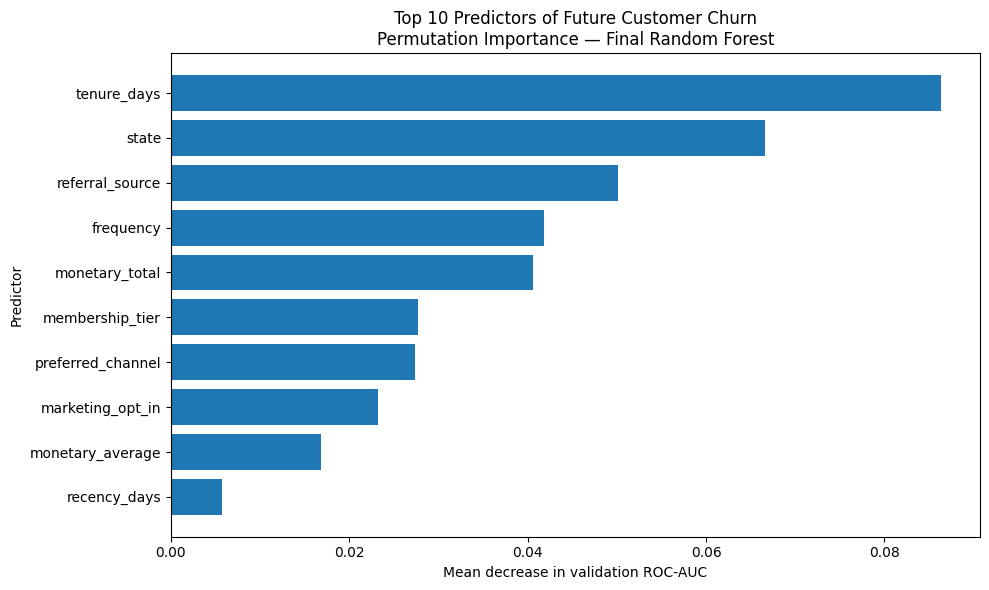


TOP 10 PREDICTORS
--------------------------------------------------


,Feature,Mean Importance,Std Importance
0,tenure_days,0.086390,0.002609
1,state,0.066648,0.002917
2,referral_source,0.050136,0.001128
3,frequency,0.041830,0.001098
4,monetary_total,0.040602,0.001544
5,membership_tier,0.027758,0.000911
6,preferred_channel,0.027345,0.000663
7,marketing_opt_in,0.023219,0.001166
8,monetary_average,0.016811,0.001157
9,recency_days,0.005699,0.000944



CELL 64 RESULT: PERMUTATION IMPORTANCE VISUALIZATION COMPLETE


In [ ]:
# ======================================================================
# CELL 64: TOP PREDICTORS — PERMUTATION IMPORTANCE VISUALIZATION
# ======================================================================

import matplotlib.pyplot as plt

print("=" * 70)
print("CELL 64: PERMUTATION IMPORTANCE VISUALIZATION")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Select the top 10 predictors
# ----------------------------------------------------------------------

top_10_permutation = (
    permutation_importance_df
    .head(10)
    .sort_values(
        by="Mean Importance",
        ascending=True
    )
)


# ----------------------------------------------------------------------
# 2. Create horizontal bar chart
# ----------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_permutation["Feature"],
    top_10_permutation["Mean Importance"]
)

plt.xlabel("Mean decrease in validation ROC-AUC")
plt.ylabel("Predictor")
plt.title(
    "Top 10 Predictors of Future Customer Churn\n"
    "Permutation Importance — Final Random Forest"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 3. Display the underlying values for documentation
# ----------------------------------------------------------------------

print("\nTOP 10 PREDICTORS")
print("-" * 50)

display(
    top_10_permutation
    .sort_values(
        by="Mean Importance",
        ascending=False
    )
    .style.format({
        "Mean Importance": "{:.6f}",
        "Std Importance": "{:.6f}"
    })
)


print("\n" + "=" * 70)
print("CELL 64 RESULT: PERMUTATION IMPORTANCE VISUALIZATION COMPLETE")
print("=" * 70)

# Chart Insights & Business Interpretation

### Chart 20 — Top predictors of future customer churn: permutation importance

Permutation importance identifies **tenure_days (0.0864)** as the strongest measured predictor, followed by state (0.0666), referral source (0.0501), frequency (0.0418) and monetary total (0.0406). These values indicate predictive contribution to validation ROC-AUC, not causation; Meridian should use them to prioritise investigation and intervention design rather than claim that any feature directly causes churn.



# Model Evaluation — Business Metric Justification

The model is evaluated with **recall, precision, F1, ROC-AUC, PR-AUC and the confusion matrix**, rather than accuracy alone. This is appropriate because Meridian faces two different business costs: a **false negative** means a customer who will churn is missed, while a **false positive** means Meridian may spend a retention incentive or staff time on a customer who would not have churned.

**Recall is especially important for retention:** missing a future churner can mean losing an opportunity to intervene. **Precision matters for campaign efficiency:** excessive false positives can waste incentives and contact capacity. **F1 balances recall and precision**, while **PR-AUC** helps evaluate ranking quality for the churn-positive class. ROC-AUC provides an overall measure of discrimination across thresholds.

The final model therefore should not be judged by a single metric. The selected tuned Random Forest provides a business-relevant balance, and the threshold analysis demonstrates that changing the threshold can deliberately trade recall for precision depending on campaign capacity and intervention cost.

In [ ]:
# ======================================================================
# CELL 65: FINAL MODEL ERROR ANALYSIS
# ======================================================================

print("=" * 70)
print("CELL 65: FALSE POSITIVE / FALSE NEGATIVE ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Extract confusion-matrix values for the final model
# ----------------------------------------------------------------------

tn, fp, fn, tp = tuned_rf_test_cm.ravel()


# ----------------------------------------------------------------------
# 2. Calculate error rates
# ----------------------------------------------------------------------

total_test_cases = tn + fp + fn + tp

false_positive_rate = fp / (fp + tn)

false_negative_rate = fn / (fn + tp)

positive_prediction_rate = (tp + fp) / total_test_cases

actual_churn_rate = (tp + fn) / total_test_cases


# ----------------------------------------------------------------------
# 3. Create a readable summary
# ----------------------------------------------------------------------

error_analysis = pd.DataFrame({
    "Measure": [
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives",
        "False Positive Rate",
        "False Negative Rate",
        "Predicted Churn Rate",
        "Actual Churn Rate"
    ],

    "Value": [
        tn,
        fp,
        fn,
        tp,
        false_positive_rate,
        false_negative_rate,
        positive_prediction_rate,
        actual_churn_rate
    ]
})


# ----------------------------------------------------------------------
# 4. Display the results
# ----------------------------------------------------------------------

print("\nFINAL MODEL CONFUSION-MATRIX ANALYSIS")
print("-" * 70)

display(
    error_analysis.style.format({
        "Value": lambda x: (
            f"{x:.4%}"
            if isinstance(x, (float, np.floating)) and x < 1
            else f"{x:,.0f}"
        )
    })
)


# ----------------------------------------------------------------------
# 5. Explicit business interpretation
# ----------------------------------------------------------------------

print("\nBUSINESS INTERPRETATION")
print("-" * 70)

print(
    f"False positives: {fp:,} customers were flagged as likely to churn "
    f"but did not churn during the test outcome window."
)

print(
    f"False negatives: {fn:,} customers were not flagged as likely to "
    f"churn but subsequently churned."
)

print(
    f"False positive rate: {false_positive_rate:.2%}"
)

print(
    f"False negative rate: {false_negative_rate:.2%}"
)

print(
    "\nBusiness implication:"
)

print(
    "False positives can increase the cost of retention campaigns, "
    "while false negatives represent customers who may be missed by "
    "the intervention strategy."
)


print("\n" + "=" * 70)
print("CELL 65 RESULT: ERROR ANALYSIS COMPLETE")
print("=" * 70)

CELL 65: FALSE POSITIVE / FALSE NEGATIVE ANALYSIS

FINAL MODEL CONFUSION-MATRIX ANALYSIS
----------------------------------------------------------------------


,Measure,Value
0,True Negatives,"3,624"
1,False Positives,"8,362"
2,False Negatives,"3,243"
3,True Positives,"21,767"
4,False Positive Rate,69.7647%
5,False Negative Rate,12.9668%
6,Predicted Churn Rate,81.4385%
7,Actual Churn Rate,67.6019%



BUSINESS INTERPRETATION
----------------------------------------------------------------------
False positives: 8,362 customers were flagged as likely to churn but did not churn during the test outcome window.
False negatives: 3,243 customers were not flagged as likely to churn but subsequently churned.
False positive rate: 69.76%
False negative rate: 12.97%

Business implication:
False positives can increase the cost of retention campaigns, while false negatives represent customers who may be missed by the intervention strategy.

CELL 65 RESULT: ERROR ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 66: CHURN PREDICTION THRESHOLD ANALYSIS
# ======================================================================

print("=" * 70)
print("CELL 66: CHURN PREDICTION THRESHOLD ANALYSIS")
print("=" * 70)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# ----------------------------------------------------------------------
# 1. Generate validation probabilities from the FINAL MODEL
# ----------------------------------------------------------------------
# We use probabilities rather than the model's default 0.50 decision.
#
# This allows us to investigate how changing the threshold affects:
# - precision
# - recall
# - F1
# - balanced accuracy
# - number of customers targeted
# ----------------------------------------------------------------------

y_val_prob_final = FINAL_MODEL.predict_proba(X_val)[:, 1]


# ----------------------------------------------------------------------
# 2. Define thresholds to investigate
# ----------------------------------------------------------------------

thresholds = [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80
]


# ----------------------------------------------------------------------
# 3. Evaluate each threshold
# ----------------------------------------------------------------------

threshold_results = []

for threshold in thresholds:

    # Convert predicted probability into a class using this threshold
    y_val_threshold_pred = (
        y_val_prob_final >= threshold
    ).astype(int)

    # Calculate classification metrics
    threshold_precision = precision_score(
        y_val,
        y_val_threshold_pred,
        zero_division=0
    )

    threshold_recall = recall_score(
        y_val,
        y_val_threshold_pred,
        zero_division=0
    )

    threshold_f1 = f1_score(
        y_val,
        y_val_threshold_pred,
        zero_division=0
    )

    threshold_balanced_accuracy = balanced_accuracy_score(
        y_val,
        y_val_threshold_pred
    )

    # Number and percentage of customers predicted as churners
    predicted_churn_count = (
        y_val_threshold_pred == 1
    ).sum()

    predicted_churn_rate = (
        predicted_churn_count / len(y_val_threshold_pred)
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": threshold_precision,
        "Recall": threshold_recall,
        "F1 Score": threshold_f1,
        "Balanced Accuracy": threshold_balanced_accuracy,
        "Predicted Churn Count": predicted_churn_count,
        "Predicted Churn Rate": predicted_churn_rate
    })


# ----------------------------------------------------------------------
# 4. Create a results DataFrame
# ----------------------------------------------------------------------

threshold_results_df = pd.DataFrame(
    threshold_results
)


# ----------------------------------------------------------------------
# 5. Display results
# ----------------------------------------------------------------------

print("\nVALIDATION THRESHOLD COMPARISON")
print("-" * 70)

display(
    threshold_results_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Predicted Churn Count": "{:,.0f}",
        "Predicted Churn Rate": "{:.2%}"
    })
)


# ----------------------------------------------------------------------
# 6. Identify the threshold with the highest F1
# ----------------------------------------------------------------------
# This is a descriptive reference point only.
# It does NOT automatically mean that this is the business-optimal
# threshold.
# ----------------------------------------------------------------------

best_f1_row = threshold_results_df.loc[
    threshold_results_df["F1 Score"].idxmax()
]

print("\nHIGHEST F1 THRESHOLD")
print("-" * 70)

print(
    f"Threshold: {best_f1_row['Threshold']:.2f}"
)

print(
    f"F1 Score: {best_f1_row['F1 Score']:.4f}"
)

print(
    f"Precision: {best_f1_row['Precision']:.4f}"
)

print(
    f"Recall: {best_f1_row['Recall']:.4f}"
)

print(
    f"Predicted churn rate: "
    f"{best_f1_row['Predicted Churn Rate']:.2%}"
)


print("\n" + "=" * 70)
print("CELL 66 RESULT: THRESHOLD ANALYSIS COMPLETE")
print("=" * 70)

CELL 66: CHURN PREDICTION THRESHOLD ANALYSIS

VALIDATION THRESHOLD COMPARISON
----------------------------------------------------------------------


,Threshold,Precision,Recall,F1 Score,Balanced Accuracy,Predicted Churn Count,Predicted Churn Rate
0,0.30,0.6059,0.9978,0.7540,0.5096,"27,912",99.01%
1,0.40,0.6251,0.9798,0.7632,0.5467,"26,569",94.25%
2,0.50,0.6784,0.8985,0.7731,0.6280,"22,450",79.64%
3,0.60,0.7413,0.7148,0.7278,0.6693,"16,344",57.98%
4,0.70,0.7769,0.4317,0.5550,0.6224,"9,418",33.41%
5,0.80,0.7426,0.1763,0.2850,0.5421,"4,025",14.28%



HIGHEST F1 THRESHOLD
----------------------------------------------------------------------
Threshold: 0.50
F1 Score: 0.7731
Precision: 0.6784
Recall: 0.8985
Predicted churn rate: 79.64%

CELL 66 RESULT: THRESHOLD ANALYSIS COMPLETE


CELL 67: FINAL MODEL ROC & PRECISION-RECALL CURVES


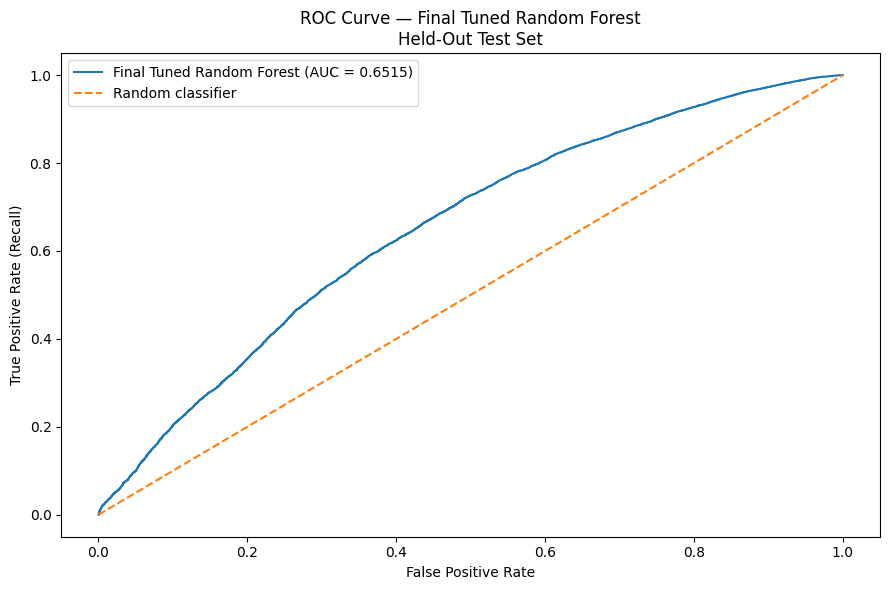

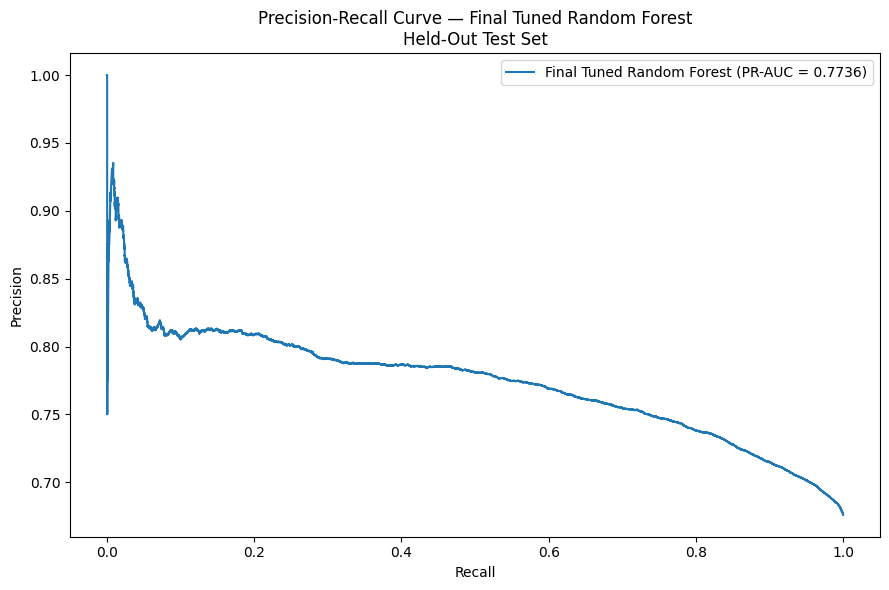


FINAL CURVE METRICS
--------------------------------------------------
ROC-AUC: 0.6515
PR-AUC:  0.7736

Expected reference values from Cell 59C:
ROC-AUC: 0.6515
PR-AUC:  0.7737

METRIC CONSISTENCY CHECK
--------------------------------------------------
ROC-AUC difference: 0.0000000000
PR-AUC difference:  0.0000529782
Curve metric consistency: REVIEW

CELL 67 RESULT: ROC & PRECISION-RECALL ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 67: FINAL MODEL ROC AND PRECISION-RECALL CURVES
# ======================================================================

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

print("=" * 70)
print("CELL 67: FINAL MODEL ROC & PRECISION-RECALL CURVES")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Generate final-model probabilities on the test set
# ----------------------------------------------------------------------
# We already generated these in Cell 59C, but we calculate them again
# explicitly here so this visualization cell is self-contained.
#
# IMPORTANT:
# We are using the final tuned Random Forest and the untouched test set.
# No model fitting occurs here.
# ----------------------------------------------------------------------

y_test_prob_final = FINAL_MODEL.predict_proba(X_test)[:, 1]


# ----------------------------------------------------------------------
# 2. Calculate ROC curve
# ----------------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_test_prob_final
)

roc_auc_final = auc(
    fpr,
    tpr
)


# ----------------------------------------------------------------------
# 3. Calculate Precision-Recall curve
# ----------------------------------------------------------------------

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_prob_final
)

pr_auc_final = auc(
    recall_curve,
    precision_curve
)


# ----------------------------------------------------------------------
# 4. Display ROC curve
# ----------------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Final Tuned Random Forest (AUC = {roc_auc_final:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title(
    "ROC Curve — Final Tuned Random Forest\n"
    "Held-Out Test Set"
)

plt.legend()
plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 5. Display Precision-Recall curve
# ----------------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Final Tuned Random Forest (PR-AUC = {pr_auc_final:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Precision-Recall Curve — Final Tuned Random Forest\n"
    "Held-Out Test Set"
)

plt.legend()
plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 6. Report final curve values
# ----------------------------------------------------------------------

print("\nFINAL CURVE METRICS")
print("-" * 50)

print(f"ROC-AUC: {roc_auc_final:.4f}")
print(f"PR-AUC:  {pr_auc_final:.4f}")

print("\nExpected reference values from Cell 59C:")
print(f"ROC-AUC: {tuned_rf_test_roc_auc:.4f}")
print(f"PR-AUC:  {tuned_rf_test_pr_auc:.4f}")


# ----------------------------------------------------------------------
# 7. Validation check
# ----------------------------------------------------------------------

roc_difference = abs(
    roc_auc_final - tuned_rf_test_roc_auc
)

pr_difference = abs(
    pr_auc_final - tuned_rf_test_pr_auc
)

print("\nMETRIC CONSISTENCY CHECK")
print("-" * 50)

print(
    f"ROC-AUC difference: {roc_difference:.10f}"
)

print(
    f"PR-AUC difference:  {pr_difference:.10f}"
)

if roc_difference < 1e-10 and pr_difference < 1e-10:
    print("Curve metric consistency: PASS")
else:
    print("Curve metric consistency: REVIEW")


print("\n" + "=" * 70)
print("CELL 67 RESULT: ROC & PRECISION-RECALL ANALYSIS COMPLETE")
print("=" * 70)

# Chart Insights & Business Interpretation

### Chart 21 — ROC curve for the final tuned Random Forest

The final tuned Random Forest achieves **ROC-AUC = 0.6515 on the untouched test set**, showing useful but moderate ability to rank future churners above non-churners. The model should therefore be used as a prioritisation tool rather than as a perfect yes/no churn detector.

### Chart 22 — Precision–Recall curve for the final tuned Random Forest

The final model achieves **PR-AUC = 0.7737**, which is particularly informative for this churn problem because the positive class is common and the business cares about the quality of customers selected for retention action. The curve illustrates the trade-off between reaching more future churners and limiting unnecessary interventions.



In [ ]:
# ======================================================================
# CELL 68: FINAL MODEL PERFORMANCE SUMMARY
# ======================================================================

print("=" * 70)
print("CELL 68: FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Create a compact final performance summary
# ----------------------------------------------------------------------

final_model_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Validation": [
        tuned_rf_accuracy,
        tuned_rf_balanced_accuracy,
        tuned_rf_precision,
        tuned_rf_recall,
        tuned_rf_f1,
        tuned_rf_roc_auc,
        tuned_rf_pr_auc
    ],

    "Test": [
        tuned_rf_test_accuracy,
        tuned_rf_test_balanced_accuracy,
        tuned_rf_test_precision,
        tuned_rf_test_recall,
        tuned_rf_test_f1,
        tuned_rf_test_roc_auc,
        tuned_rf_test_pr_auc
    ]
})


# ----------------------------------------------------------------------
# 2. Display final performance
# ----------------------------------------------------------------------

print("\nFINAL TUNED RANDOM FOREST PERFORMANCE")
print("-" * 70)

display(
    final_model_summary.style.format({
        "Validation": "{:.4f}",
        "Test": "{:.4f}"
    })
)


# ----------------------------------------------------------------------
# 3. Final model configuration
# ----------------------------------------------------------------------

print("\nFINAL MODEL CONFIGURATION")
print("-" * 70)

print(f"Model: {FINAL_MODEL_NAME}")

print("\nHyperparameters:")

for parameter, value in rf_random_search.best_params_.items():
    print(f"- {parameter}: {value}")


# ----------------------------------------------------------------------
# 4. Final test confusion matrix
# ----------------------------------------------------------------------

print("\nFINAL TEST CONFUSION MATRIX")
print("-" * 70)

print(tuned_rf_test_cm)


# ----------------------------------------------------------------------
# 5. Final threshold information
# ----------------------------------------------------------------------

print("\nCLASSIFICATION THRESHOLD")
print("-" * 70)

print("Default classification threshold: 0.50")
print("Highest validation F1 among tested thresholds: 0.50")
print(f"Validation F1 at 0.50: {tuned_rf_f1:.4f}")


# ----------------------------------------------------------------------
# 6. Final model statement
# ----------------------------------------------------------------------

print("\nFINAL MODEL STATEMENT")
print("-" * 70)

print(
    "The tuned Random Forest is the selected model for downstream "
    "interpretation and customer-level scoring."
)

print(
    "Its final held-out test performance is summarized using ROC-AUC, "
    "PR-AUC, precision, recall, F1 and balanced accuracy."
)


print("\n" + "=" * 70)
print("CELL 68 RESULT: FINAL MODEL SUMMARY COMPLETE")
print("=" * 70)

CELL 68: FINAL MODEL PERFORMANCE SUMMARY

FINAL TUNED RANDOM FOREST PERFORMANCE
----------------------------------------------------------------------


,Metric,Validation,Test
0,Accuracy,0.6828,0.6863
1,Balanced Accuracy,0.6280,0.5863
2,Precision,0.6784,0.7225
3,Recall,0.8985,0.8703
4,F1 Score,0.7731,0.7895
5,ROC-AUC,0.7087,0.6515
6,PR-AUC,0.7366,0.7737



FINAL MODEL CONFIGURATION
----------------------------------------------------------------------
Model: Tuned Random Forest

Hyperparameters:
- model__class_weight: None
- model__max_depth: 20
- model__max_features: log2
- model__min_samples_leaf: 1
- model__min_samples_split: 4
- model__n_estimators: 378

FINAL TEST CONFUSION MATRIX
----------------------------------------------------------------------
[[ 3624  8362]
 [ 3243 21767]]

CLASSIFICATION THRESHOLD
----------------------------------------------------------------------
Default classification threshold: 0.50
Highest validation F1 among tested thresholds: 0.50
Validation F1 at 0.50: 0.7731

FINAL MODEL STATEMENT
----------------------------------------------------------------------
The tuned Random Forest is the selected model for downstream interpretation and customer-level scoring.
Its final held-out test performance is summarized using ROC-AUC, PR-AUC, precision, recall, F1 and balanced accuracy.

CELL 68 RESULT: FINAL MODE

In [ ]:
# ======================================================================
# CELL 69: CURRENT CUSTOMER SCORING READINESS AUDIT
# ======================================================================

print("=" * 70)
print("CELL 69: CURRENT CUSTOMER SCORING READINESS AUDIT")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Define the required model predictors
# ----------------------------------------------------------------------
# These are the predictors used when training the final Random Forest.
# They must be available for every customer we want to score.
# ----------------------------------------------------------------------

required_model_features = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average",
    "tenure_days"
]


# ----------------------------------------------------------------------
# 2. Identify the current active customers
# ----------------------------------------------------------------------
# active_customer_ids was created earlier from the locked business
# definition:
#
# Active = at least one Completed order during the 180 days preceding
#          2026-07-01.
#
# We use those IDs as the current scoring population.
# ----------------------------------------------------------------------

current_active_customers = customers_eda[
    customers_eda["customer_id"].isin(active_customer_ids)
].copy()


print("\nCURRENT SCORING POPULATION")
print("-" * 50)

print(
    f"Active customers identified: "
    f"{len(current_active_customers):,}"
)

print(
    f"Expected active customers:  "
    f"{len(active_customer_ids):,}"
)

print(
    f"Unique active customer IDs: "
    f"{current_active_customers['customer_id'].nunique():,}"
)


# ----------------------------------------------------------------------
# 3. Validate the expected population
# ----------------------------------------------------------------------

if (
    len(current_active_customers) == 2018
    and
    current_active_customers["customer_id"].nunique() == 2018
):
    print("Active-customer population check: PASS")
else:
    print("Active-customer population check: REVIEW")


# ----------------------------------------------------------------------
# 4. Check that all required model predictors are defined
# ----------------------------------------------------------------------
# At this stage, the features may not yet exist in the current customer
# table. That is okay.
#
# We are simply checking which predictors already exist and which ones
# must be engineered from historical orders/support data.
# ----------------------------------------------------------------------

print("\nMODEL FEATURE AVAILABILITY")
print("-" * 50)

available_features = [
    feature
    for feature in required_model_features
    if feature in current_active_customers.columns
]

missing_features = [
    feature
    for feature in required_model_features
    if feature not in current_active_customers.columns
]

print(f"Required predictors: {len(required_model_features)}")
print(f"Already available:   {len(available_features)}")
print(f"Need engineering:    {len(missing_features)}")

print("\nAlready available:")
for feature in available_features:
    print(f"  ✓ {feature}")

print("\nNeed engineering:")
for feature in missing_features:
    print(f"  → {feature}")


# ----------------------------------------------------------------------
# 5. Check customer-level attributes for missing values
# ----------------------------------------------------------------------
# These attributes are directly available from the customer master.
# We inspect them before constructing the complete scoring dataset.
# ----------------------------------------------------------------------

customer_attributes = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

print("\nCURRENT CUSTOMER ATTRIBUTE QUALITY")
print("-" * 50)

for feature in customer_attributes:

    if feature in current_active_customers.columns:

        missing_count = (
            current_active_customers[feature]
            .isna()
            .sum()
        )

        print(
            f"{feature:<20}: "
            f"{missing_count:,} missing"
        )

    else:
        print(
            f"{feature:<20}: "
            "COLUMN NOT FOUND"
        )


# ----------------------------------------------------------------------
# 6. Check duplicate customer IDs
# ----------------------------------------------------------------------

duplicate_customer_ids = (
    current_active_customers["customer_id"]
    .duplicated()
    .sum()
)

print("\nCUSTOMER ID CHECK")
print("-" * 50)

print(
    f"Duplicate customer records: "
    f"{duplicate_customer_ids:,}"
)

if duplicate_customer_ids == 0:
    print("Customer uniqueness check: PASS")
else:
    print("Customer uniqueness check: REVIEW")


# ----------------------------------------------------------------------
# 7. Confirm the final model is available
# ----------------------------------------------------------------------

print("\nFINAL MODEL AVAILABILITY")
print("-" * 50)

print(
    f"FINAL_MODEL available: "
    f"{'FINAL_MODEL' in globals()}"
)

print(
    f"FINAL_MODEL_NAME: "
    f"{FINAL_MODEL_NAME}"
)


# ----------------------------------------------------------------------
# 8. Confirm the scoring date
# ----------------------------------------------------------------------

print("\nSCORING DATE")
print("-" * 50)

print(
    f"Snapshot / scoring date: "
    f"{SNAPSHOT_DATE.strftime('%Y-%m-%d')}"
)

print(
    f"Churn lookback window: "
    f"{CHURN_WINDOW_DAYS} days"
)

print(
    f"Lookback start: "
    f"{CHURN_WINDOW_START.strftime('%Y-%m-%d')}"
)


# ----------------------------------------------------------------------
# 9. Final readiness summary
# ----------------------------------------------------------------------

print("\nREADINESS SUMMARY")
print("-" * 50)

print(
    "The current active-customer population has been identified."
)

print(
    "The remaining step is to engineer the historical behavioural "
    "and support predictors as of the 2026-07-01 snapshot."
)

print(
    "No churn predictions are generated in this cell."
)


print("\n" + "=" * 70)
print("CELL 69 RESULT: SCORING READINESS AUDIT COMPLETE")
print("=" * 70)

CELL 69: CURRENT CUSTOMER SCORING READINESS AUDIT

CURRENT SCORING POPULATION
--------------------------------------------------
Active customers identified: 2,018
Expected active customers:  2,018
Unique active customer IDs: 2,018
Active-customer population check: PASS

MODEL FEATURE AVAILABILITY
--------------------------------------------------
Required predictors: 13
Already available:   5
Need engineering:    8

Already available:
  ✓ membership_tier
  ✓ preferred_channel
  ✓ state
  ✓ referral_source
  ✓ marketing_opt_in

Need engineering:
  → recency_days
  → frequency
  → monetary_total
  → monetary_average
  → support_ticket_count
  → satisfaction_average
  → resolution_time_average
  → tenure_days

CURRENT CUSTOMER ATTRIBUTE QUALITY
--------------------------------------------------
membership_tier     : 0 missing
preferred_channel   : 0 missing
state               : 0 missing
referral_source     : 539 missing
marketing_opt_in    : 393 missing

CUSTOMER ID CHECK
-------------

In [ ]:
# ======================================================================
# CELL 70: CURRENT CUSTOMER RFM / PURCHASE-BEHAVIOUR FEATURES
# ======================================================================

print("=" * 70)
print("CELL 70: CURRENT CUSTOMER RFM FEATURES")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Start with the 2,018 current active customers
# ----------------------------------------------------------------------
# We keep ALL active customers, even if an unexpected feature is missing.
# This allows us to identify and handle missing values explicitly later.
# ----------------------------------------------------------------------

current_scoring_base = current_active_customers[
    ["customer_id"]
].copy()

print("\nCURRENT SCORING BASE")
print("-" * 50)

print(
    f"Customers in scoring base: "
    f"{len(current_scoring_base):,}"
)

print(
    f"Unique customer IDs: "
    f"{current_scoring_base['customer_id'].nunique():,}"
)


# ----------------------------------------------------------------------
# 2. Select completed orders available by the snapshot date
# ----------------------------------------------------------------------
# IMPORTANT:
#
# We use only:
#   order_status = Completed
#   order_date >= 2026-01-02
#   order_date <= 2026-07-01
#
# This follows our LOCKED 180-day business definition.
#
# Orders after 2026-07-01 must NOT influence current customer features.
# ----------------------------------------------------------------------

completed_snapshot_orders = orders[
    (orders["order_status"] == "Completed")
    &
    (orders["order_date"] >= CHURN_WINDOW_START)
    &
    (orders["order_date"] <= SNAPSHOT_DATE)
].copy()


# ----------------------------------------------------------------------
# 3. Validate the order-date boundary
# ----------------------------------------------------------------------

print("\nQUALIFYING COMPLETED ORDERS")
print("-" * 50)

print(
    f"Qualifying completed orders: "
    f"{len(completed_snapshot_orders):,}"
)

print(
    f"Earliest qualifying order: "
    f"{completed_snapshot_orders['order_date'].min()}"
)

print(
    f"Latest qualifying order: "
    f"{completed_snapshot_orders['order_date'].max()}"
)

post_snapshot_count = (
    completed_snapshot_orders["order_date"] > SNAPSHOT_DATE
).sum()

print(
    f"Post-snapshot orders included: "
    f"{post_snapshot_count:,}"
)

if post_snapshot_count == 0:
    print("Snapshot boundary check: PASS")
else:
    raise ValueError(
        "Post-snapshot orders were included in the RFM calculation."
    )


# ----------------------------------------------------------------------
# 4. Calculate customer-level RFM features
# ----------------------------------------------------------------------
# Recency:
#   Snapshot date minus most recent completed order date.
#
# Frequency:
#   Number of completed orders in the qualifying period.
#
# Monetary total:
#   Sum of completed-order total_amount.
#
# Monetary average:
#   Average completed-order total_amount.
# ----------------------------------------------------------------------

rfm_current = (
    completed_snapshot_orders
    .groupby("customer_id")
    .agg(
        last_completed_order_date=("order_date", "max"),
        frequency=("order_id", "nunique"),
        monetary_total=("total_amount", "sum"),
        monetary_average=("total_amount", "mean")
    )
    .reset_index()
)


# Calculate recency in days
rfm_current["recency_days"] = (
    SNAPSHOT_DATE
    - rfm_current["last_completed_order_date"]
).dt.days


# ----------------------------------------------------------------------
# 5. Keep the feature columns required by the ML model
# ----------------------------------------------------------------------

rfm_current = rfm_current[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_total",
        "monetary_average",
        "last_completed_order_date"
    ]
].copy()


# ----------------------------------------------------------------------
# 6. Merge RFM features onto ALL current active customers
# ----------------------------------------------------------------------
# A LEFT JOIN is deliberate.
#
# It guarantees that the scoring population remains exactly the 2,018
# active customers even if a customer unexpectedly has no matching
# qualifying order.
# ----------------------------------------------------------------------

current_scoring_rfm = current_scoring_base.merge(
    rfm_current,
    on="customer_id",
    how="left",
    validate="one_to_one"
)


# ----------------------------------------------------------------------
# 7. RFM quality checks
# ----------------------------------------------------------------------

print("\nRFM FEATURE SUMMARY")
print("-" * 50)

print(
    f"Scoring customers after merge: "
    f"{len(current_scoring_rfm):,}"
)

print(
    f"Unique customer IDs: "
    f"{current_scoring_rfm['customer_id'].nunique():,}"
)

print(
    f"Customers with RFM history: "
    f"{current_scoring_rfm['last_completed_order_date'].notna().sum():,}"
)

print(
    f"Customers without RFM history: "
    f"{current_scoring_rfm['last_completed_order_date'].isna().sum():,}"
)


# ----------------------------------------------------------------------
# 8. Check for invalid RFM values
# ----------------------------------------------------------------------

negative_recency = (
    current_scoring_rfm["recency_days"].dropna() < 0
).sum()

invalid_frequency = (
    current_scoring_rfm["frequency"].dropna() <= 0
).sum()

invalid_monetary = (
    current_scoring_rfm["monetary_total"].dropna() < 0
).sum()

print("\nRFM VALIDATION")
print("-" * 50)

print(
    f"Negative recency values: "
    f"{negative_recency:,}"
)

print(
    f"Invalid frequency values: "
    f"{invalid_frequency:,}"
)

print(
    f"Negative monetary totals: "
    f"{invalid_monetary:,}"
)


# ----------------------------------------------------------------------
# 9. Display descriptive statistics
# ----------------------------------------------------------------------

print("\nCURRENT CUSTOMER RFM STATISTICS")
print("-" * 50)

display(
    current_scoring_rfm[
        [
            "recency_days",
            "frequency",
            "monetary_total",
            "monetary_average"
        ]
    ].describe().round(2)
)


# ----------------------------------------------------------------------
# 10. Final checks
# ----------------------------------------------------------------------

if (
    len(current_scoring_rfm) == 2018
    and
    current_scoring_rfm["customer_id"].nunique() == 2018
    and
    negative_recency == 0
    and
    invalid_frequency == 0
    and
    invalid_monetary == 0
):
    print("\nRFM scoring-population validation: PASS")
else:
    print("\nRFM scoring-population validation: REVIEW")


print("\n" + "=" * 70)
print("CELL 70 RESULT: CURRENT CUSTOMER RFM FEATURES COMPLETE")
print("=" * 70)

CELL 70: CURRENT CUSTOMER RFM FEATURES

CURRENT SCORING BASE
--------------------------------------------------
Customers in scoring base: 2,018
Unique customer IDs: 2,018

QUALIFYING COMPLETED ORDERS
--------------------------------------------------
Qualifying completed orders: 4,779
Earliest qualifying order: 2026-01-02 00:00:00
Latest qualifying order: 2026-07-01 00:00:00
Post-snapshot orders included: 0
Snapshot boundary check: PASS

RFM FEATURE SUMMARY
--------------------------------------------------
Scoring customers after merge: 2,018
Unique customer IDs: 2,018
Customers with RFM history: 2,018
Customers without RFM history: 0

RFM VALIDATION
--------------------------------------------------
Negative recency values: 0
Invalid frequency values: 0
Negative monetary totals: 0

CURRENT CUSTOMER RFM STATISTICS
--------------------------------------------------


,recency_days,frequency,monetary_total,monetary_average
count,2018.00,2018.00,2018.00,2018.00
mean,89.19,2.37,3700.76,1550.62
std,45.34,1.75,3349.03,943.48
min,0.00,1.00,15.20,15.20
25%,54.00,1.00,1278.23,911.80
50%,87.00,2.00,2665.94,1404.28
75%,123.00,3.00,5132.33,2015.63
max,180.00,11.00,21095.90,8648.08



RFM scoring-population validation: PASS

CELL 70 RESULT: CURRENT CUSTOMER RFM FEATURES COMPLETE


In [ ]:
# ======================================================================
# CELL 71: CURRENT CUSTOMER SUPPORT-TICKET FEATURES
# ======================================================================

print("=" * 70)
print("CELL 71: CURRENT CUSTOMER SUPPORT FEATURES")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Select support tickets available by the snapshot date
# ----------------------------------------------------------------------
# We must not use support information occurring after the prediction
# snapshot.
# ----------------------------------------------------------------------

support_snapshot = support_tickets[
    support_tickets["ticket_date"] <= SNAPSHOT_DATE
].copy()


print("\nSUPPORT DATA AT SNAPSHOT")
print("-" * 50)

print(
    f"Support tickets available by snapshot: "
    f"{len(support_snapshot):,}"
)

print(
    f"Earliest ticket date: "
    f"{support_snapshot['ticket_date'].min()}"
)

print(
    f"Latest ticket date: "
    f"{support_snapshot['ticket_date'].max()}"
)


# ----------------------------------------------------------------------
# 2. Confirm no future support tickets are included
# ----------------------------------------------------------------------

future_support_count = (
    support_snapshot["ticket_date"] > SNAPSHOT_DATE
).sum()

print(
    f"Future support tickets included: "
    f"{future_support_count:,}"
)

if future_support_count == 0:
    print("Support temporal boundary check: PASS")
else:
    raise ValueError(
        "Future support tickets were included in current scoring features."
    )


# ----------------------------------------------------------------------
# 3. Create customer-level support features
# ----------------------------------------------------------------------
#
# support_ticket_count:
#     Number of support tickets raised by the customer.
#
# satisfaction_average:
#     Mean recorded satisfaction score.
#     Missing satisfaction scores are ignored by mean().
#
# resolution_time_average:
#     Mean recorded resolution time.
#     Missing resolution times are ignored by mean().
#
# We do NOT manually impute these values here.
# The trained ML preprocessing pipeline will handle missing numerical
# values using the strategy established during model development.
# ----------------------------------------------------------------------

support_current = (
    support_snapshot
    .groupby("customer_id")
    .agg(
        support_ticket_count=("ticket_id", "nunique"),
        satisfaction_average=("satisfaction_score", "mean"),
        resolution_time_average=("resolution_time_hours", "mean")
    )
    .reset_index()
)


# ----------------------------------------------------------------------
# 4. Merge support features onto the current scoring population
# ----------------------------------------------------------------------
# LEFT JOIN ensures all 2,018 active customers remain in the dataset.
# Customers with no support history will receive missing values for
# satisfaction/resolution and zero after we explicitly set ticket count.
# ----------------------------------------------------------------------

current_scoring_features = current_scoring_rfm.merge(
    support_current,
    on="customer_id",
    how="left",
    validate="one_to_one"
)


# Customers with no support tickets have a true ticket count of zero.
current_scoring_features["support_ticket_count"] = (
    current_scoring_features["support_ticket_count"]
    .fillna(0)
    .astype(int)
)


# ----------------------------------------------------------------------
# 5. Validate the resulting support features
# ----------------------------------------------------------------------

print("\nCURRENT SUPPORT FEATURE SUMMARY")
print("-" * 50)

print(
    f"Scoring customers after support merge: "
    f"{len(current_scoring_features):,}"
)

print(
    f"Unique customer IDs: "
    f"{current_scoring_features['customer_id'].nunique():,}"
)

print(
    f"Customers with at least one ticket: "
    f"{(current_scoring_features['support_ticket_count'] > 0).sum():,}"
)

print(
    f"Customers with no tickets: "
    f"{(current_scoring_features['support_ticket_count'] == 0).sum():,}"
)

print(
    f"Missing satisfaction averages: "
    f"{current_scoring_features['satisfaction_average'].isna().sum():,}"
)

print(
    f"Missing resolution averages: "
    f"{current_scoring_features['resolution_time_average'].isna().sum():,}"
)


# ----------------------------------------------------------------------
# 6. Validate support feature ranges
# ----------------------------------------------------------------------

invalid_ticket_count = (
    current_scoring_features["support_ticket_count"] < 0
).sum()

invalid_satisfaction = (
    (
        current_scoring_features["satisfaction_average"].notna()
    )
    &
    (
        (
            current_scoring_features["satisfaction_average"] < 1
        )
        |
        (
            current_scoring_features["satisfaction_average"] > 5
        )
    )
).sum()

invalid_resolution = (
    (
        current_scoring_features["resolution_time_average"].notna()
    )
    &
    (
        current_scoring_features["resolution_time_average"] < 0
    )
).sum()


print("\nSUPPORT FEATURE VALIDATION")
print("-" * 50)

print(
    f"Negative ticket counts: "
    f"{invalid_ticket_count:,}"
)

print(
    f"Invalid satisfaction averages: "
    f"{invalid_satisfaction:,}"
)

print(
    f"Negative resolution averages: "
    f"{invalid_resolution:,}"
)


# ----------------------------------------------------------------------
# 7. Display descriptive statistics
# ----------------------------------------------------------------------

print("\nCURRENT SUPPORT FEATURE STATISTICS")
print("-" * 50)

display(
    current_scoring_features[
        [
            "support_ticket_count",
            "satisfaction_average",
            "resolution_time_average"
        ]
    ].describe().round(2)
)


# ----------------------------------------------------------------------
# 8. Final scoring-population validation
# ----------------------------------------------------------------------

if (
    len(current_scoring_features) == 2018
    and
    current_scoring_features["customer_id"].nunique() == 2018
    and
    invalid_ticket_count == 0
    and
    invalid_satisfaction == 0
    and
    invalid_resolution == 0
):
    print("\nSupport-feature scoring-population validation: PASS")
else:
    print("\nSupport-feature scoring-population validation: REVIEW")


print("\n" + "=" * 70)
print("CELL 71 RESULT: CURRENT SUPPORT FEATURES COMPLETE")
print("=" * 70)

CELL 71: CURRENT CUSTOMER SUPPORT FEATURES

SUPPORT DATA AT SNAPSHOT
--------------------------------------------------
Support tickets available by snapshot: 5,200
Earliest ticket date: 2024-09-03 00:00:00
Latest ticket date: 2026-06-30 00:00:00
Future support tickets included: 0
Support temporal boundary check: PASS

CURRENT SUPPORT FEATURE SUMMARY
--------------------------------------------------
Scoring customers after support merge: 2,018
Unique customer IDs: 2,018
Customers with at least one ticket: 1,163
Customers with no tickets: 855
Missing satisfaction averages: 957
Missing resolution averages: 855

SUPPORT FEATURE VALIDATION
--------------------------------------------------
Negative ticket counts: 0
Invalid satisfaction averages: 0
Negative resolution averages: 0

CURRENT SUPPORT FEATURE STATISTICS
--------------------------------------------------


,support_ticket_count,satisfaction_average,resolution_time_average
count,2018.00,1061.00,1163.00
mean,0.83,3.92,17.32
std,0.88,1.09,20.30
min,0.00,1.00,0.00
25%,0.00,3.00,6.10
50%,1.00,4.00,12.40
75%,1.00,5.00,23.25
max,5.00,5.00,422.25



Support-feature scoring-population validation: PASS

CELL 71 RESULT: CURRENT SUPPORT FEATURES COMPLETE


In [ ]:
# ======================================================================
# CELL 72: FINAL CURRENT SCORING FEATURE ASSEMBLY
# ======================================================================

print("=" * 70)
print("CELL 72: FINAL CURRENT SCORING FEATURES")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Bring in the customer-level attributes
# ----------------------------------------------------------------------
# These are the same customer attributes used during ML development.
#
# Referral source and marketing opt-in may contain missing values.
# We preserve them as "Unknown", consistent with the ML feature strategy.
# ----------------------------------------------------------------------

customer_attributes = customers[
    [
        "customer_id",
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in",
        "signup_date"
    ]
].copy()


# Analysis/modeling representation of missing categorical information
customer_attributes["referral_source"] = (
    customer_attributes["referral_source"]
    .fillna("Unknown")
)

customer_attributes["marketing_opt_in"] = (
    customer_attributes["marketing_opt_in"]
    .fillna("Unknown")
)


# ----------------------------------------------------------------------
# 2. Calculate customer tenure at the prediction snapshot
# ----------------------------------------------------------------------
# Tenure is measured from signup date to 2026-07-01.
#
# This uses information available at the prediction date only.
# ----------------------------------------------------------------------

customer_attributes["tenure_days"] = (
    SNAPSHOT_DATE - customer_attributes["signup_date"]
).dt.days


# ----------------------------------------------------------------------
# 3. Keep only the attributes required for scoring
# ----------------------------------------------------------------------

customer_attributes = customer_attributes[
    [
        "customer_id",
        "membership_tier",
        "preferred_channel",
        "state",
        "referral_source",
        "marketing_opt_in",
        "tenure_days"
    ]
].copy()


# ----------------------------------------------------------------------
# 4. Merge customer attributes with RFM + support features
# ----------------------------------------------------------------------

current_scoring_features = current_scoring_features.merge(
    customer_attributes,
    on="customer_id",
    how="left",
    validate="one_to_one"
)


# ----------------------------------------------------------------------
# 5. Define the exact predictor order used by the ML model
# ----------------------------------------------------------------------
# IMPORTANT:
# The model was trained using these 13 predictors.
# We explicitly specify the order to prevent accidental column mismatch.
# ----------------------------------------------------------------------

FINAL_MODEL_FEATURES = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average",
    "tenure_days"
]


# ----------------------------------------------------------------------
# 6. Create the final X_current scoring matrix
# ----------------------------------------------------------------------

X_current = current_scoring_features[
    FINAL_MODEL_FEATURES
].copy()


# ----------------------------------------------------------------------
# 7. Display structure
# ----------------------------------------------------------------------

print("\nFINAL SCORING DATASET")
print("-" * 50)

print(
    f"Rows: {X_current.shape[0]:,}"
)

print(
    f"Features: {X_current.shape[1]:,}"
)

print("\nFeature columns:")
for i, column in enumerate(X_current.columns, start=1):
    print(f"{i:2}. {column}")


# ----------------------------------------------------------------------
# 8. Check categorical and numerical feature types
# ----------------------------------------------------------------------

categorical_features_current = [
    "membership_tier",
    "preferred_channel",
    "state",
    "referral_source",
    "marketing_opt_in"
]

numerical_features_current = [
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average",
    "tenure_days"
]


print("\nCATEGORICAL FEATURES")
print("-" * 50)
print(categorical_features_current)

print("\nNUMERICAL FEATURES")
print("-" * 50)
print(numerical_features_current)


# ----------------------------------------------------------------------
# 9. Missing-value audit
# ----------------------------------------------------------------------

print("\nMISSING-VALUE AUDIT")
print("-" * 50)

missing_summary = (
    X_current
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_summary.to_frame("missing_count")
)


# ----------------------------------------------------------------------
# 10. Validate the scoring population
# ----------------------------------------------------------------------

print("\nSCORING POPULATION VALIDATION")
print("-" * 50)

print(
    f"Expected active customers: 2,018"
)

print(
    f"Actual scoring rows: "
    f"{len(X_current):,}"
)

print(
    f"Unique active customers: "
    f"{current_scoring_features['customer_id'].nunique():,}"
)


# ----------------------------------------------------------------------
# 11. Validate the feature structure
# ----------------------------------------------------------------------

expected_features = set(FINAL_MODEL_FEATURES)
actual_features = set(X_current.columns)

missing_features = expected_features - actual_features
unexpected_features = actual_features - expected_features

print(
    f"Missing required features: "
    f"{len(missing_features)}"
)

print(
    f"Unexpected features: "
    f"{len(unexpected_features)}"
)


# ----------------------------------------------------------------------
# 12. Final structural validation
# ----------------------------------------------------------------------

if (
    len(X_current) == 2018
    and current_scoring_features["customer_id"].nunique() == 2018
    and list(X_current.columns) == FINAL_MODEL_FEATURES
    and len(missing_features) == 0
    and len(unexpected_features) == 0
):
    print("\nFINAL SCORING FEATURE VALIDATION: PASS")
else:
    print("\nFINAL SCORING FEATURE VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 72 RESULT: FINAL CURRENT SCORING MATRIX READY")
print("=" * 70)

CELL 72: FINAL CURRENT SCORING FEATURES

FINAL SCORING DATASET
--------------------------------------------------
Rows: 2,018
Features: 13

Feature columns:
 1. membership_tier
 2. preferred_channel
 3. state
 4. referral_source
 5. marketing_opt_in
 6. recency_days
 7. frequency
 8. monetary_total
 9. monetary_average
10. support_ticket_count
11. satisfaction_average
12. resolution_time_average
13. tenure_days

CATEGORICAL FEATURES
--------------------------------------------------
['membership_tier', 'preferred_channel', 'state', 'referral_source', 'marketing_opt_in']

NUMERICAL FEATURES
--------------------------------------------------
['recency_days', 'frequency', 'monetary_total', 'monetary_average', 'support_ticket_count', 'satisfaction_average', 'resolution_time_average', 'tenure_days']

MISSING-VALUE AUDIT
--------------------------------------------------


,missing_count
satisfaction_average,957
resolution_time_average,855
state,0
preferred_channel,0
membership_tier,0
marketing_opt_in,0
referral_source,0
recency_days,0
frequency,0
monetary_average,0



SCORING POPULATION VALIDATION
--------------------------------------------------
Expected active customers: 2,018
Actual scoring rows: 2,018
Unique active customers: 2,018
Missing required features: 0
Unexpected features: 0

FINAL SCORING FEATURE VALIDATION: PASS

CELL 72 RESULT: FINAL CURRENT SCORING MATRIX READY


In [ ]:
# ======================================================================
# CELL 73: SCORE CURRENT ACTIVE CUSTOMERS
# ======================================================================

print("=" * 70)
print("CELL 73: CURRENT CUSTOMER CHURN SCORING")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Confirm the final model and scoring matrix exist
# ----------------------------------------------------------------------

print("\nMODEL AND INPUT VALIDATION")
print("-" * 50)

print(
    f"Final model: {FINAL_MODEL_NAME}"
)

print(
    f"Scoring observations: {len(X_current):,}"
)

print(
    f"Scoring features: {X_current.shape[1]:,}"
)


# ----------------------------------------------------------------------
# 2. Generate future 180-day churn probabilities
# ----------------------------------------------------------------------
# predict_proba() returns:
#
#   column 0 = probability of class 0 (not churn)
#   column 1 = probability of class 1 (churn)
#
# Our ML target was:
#   1 = no completed order in the following 180 days
#   0 = at least one completed order
#
# Therefore column 1 is the predicted future churn probability.
# ----------------------------------------------------------------------

current_churn_probability = FINAL_MODEL.predict_proba(
    X_current
)[:, 1]


# ----------------------------------------------------------------------
# 3. Apply the established 0.50 classification threshold
# ----------------------------------------------------------------------
# Cell 66 showed that 0.50 produced the highest F1 among the tested
# validation thresholds.
#
# We retain 0.50 here for consistency with our final model evaluation.
# ----------------------------------------------------------------------

SCORING_THRESHOLD = 0.50

current_churn_prediction = (
    current_churn_probability >= SCORING_THRESHOLD
).astype(int)


# ----------------------------------------------------------------------
# 4. Create the scoring results dataframe
# ----------------------------------------------------------------------

current_customer_scores = current_scoring_features[
    ["customer_id"]
].copy()

current_customer_scores["churn_probability"] = (
    current_churn_probability
)

current_customer_scores["predicted_churn"] = (
    current_churn_prediction
)


# ----------------------------------------------------------------------
# 5. Add the classification label for easier interpretation
# ----------------------------------------------------------------------

current_customer_scores["predicted_status"] = (
    current_customer_scores["predicted_churn"]
    .map({
        0: "Predicted Active",
        1: "Predicted Churn"
    })
)


# ----------------------------------------------------------------------
# 6. Validate the scoring results
# ----------------------------------------------------------------------

print("\nSCORING RESULTS")
print("-" * 50)

print(
    f"Customers scored: "
    f"{len(current_customer_scores):,}"
)

print(
    f"Unique customers scored: "
    f"{current_customer_scores['customer_id'].nunique():,}"
)

print(
    f"Missing churn probabilities: "
    f"{current_customer_scores['churn_probability'].isna().sum():,}"
)

print(
    f"Minimum churn probability: "
    f"{current_customer_scores['churn_probability'].min():.4f}"
)

print(
    f"Maximum churn probability: "
    f"{current_customer_scores['churn_probability'].max():.4f}"
)

print(
    f"Mean churn probability: "
    f"{current_customer_scores['churn_probability'].mean():.4f}"
)

print(
    f"Median churn probability: "
    f"{current_customer_scores['churn_probability'].median():.4f}"
)


# ----------------------------------------------------------------------
# 7. Predicted class distribution
# ----------------------------------------------------------------------

print("\nPREDICTED CLASS DISTRIBUTION")
print("-" * 50)

prediction_counts = (
    current_customer_scores["predicted_status"]
    .value_counts()
)

display(prediction_counts.to_frame("customer_count"))


prediction_percentages = (
    current_customer_scores["predicted_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    prediction_percentages.to_frame("percentage")
)


# ----------------------------------------------------------------------
# 8. Probability distribution summary
# ----------------------------------------------------------------------

print("\nCHURN PROBABILITY DISTRIBUTION")
print("-" * 50)

display(
    current_customer_scores[
        ["churn_probability"]
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    ).round(4)
)


# ----------------------------------------------------------------------
# 9. Show highest-risk customers
# ----------------------------------------------------------------------
# We display the customer IDs and probabilities only for now.
# Business interpretation will come after we validate the scoring.
# ----------------------------------------------------------------------

print("\nTOP 20 CUSTOMERS BY PREDICTED CHURN PROBABILITY")
print("-" * 50)

display(
    current_customer_scores
    .sort_values(
        "churn_probability",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)


# ----------------------------------------------------------------------
# 10. Final validation
# ----------------------------------------------------------------------

if (
    len(current_customer_scores) == 2018
    and
    current_customer_scores["customer_id"].nunique() == 2018
    and
    current_customer_scores["churn_probability"].notna().all()
    and
    current_customer_scores["churn_probability"].between(0, 1).all()
):
    print("\nCURRENT CUSTOMER SCORING VALIDATION: PASS")
else:
    print("\nCURRENT CUSTOMER SCORING VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 73 RESULT: CURRENT CUSTOMER CHURN SCORING COMPLETE")
print("=" * 70)

CELL 73: CURRENT CUSTOMER CHURN SCORING

MODEL AND INPUT VALIDATION
--------------------------------------------------
Final model: Tuned Random Forest
Scoring observations: 2,018
Scoring features: 13

SCORING RESULTS
--------------------------------------------------
Customers scored: 2,018
Unique customers scored: 2,018
Missing churn probabilities: 0
Minimum churn probability: 0.2605
Maximum churn probability: 0.7996
Mean churn probability: 0.5070
Median churn probability: 0.5084

PREDICTED CLASS DISTRIBUTION
--------------------------------------------------


,customer_count
predicted_status,
Predicted Churn,1094
Predicted Active,924


,percentage
predicted_status,
Predicted Churn,54.21
Predicted Active,45.79



CHURN PROBABILITY DISTRIBUTION
--------------------------------------------------


,churn_probability
count,2018.0000
mean,0.5070
std,0.0792
min,0.2605
10%,0.4051
25%,0.4537
50%,0.5084
75%,0.5617
90%,0.6020
95%,0.6323



TOP 20 CUSTOMERS BY PREDICTED CHURN PROBABILITY
--------------------------------------------------


,customer_id,churn_probability,predicted_churn,predicted_status
0,CUST001901,0.799624,1,Predicted Churn
1,CUST000819,0.795766,1,Predicted Churn
2,CUST004804,0.761978,1,Predicted Churn
3,CUST001607,0.756471,1,Predicted Churn
4,CUST002525,0.750418,1,Predicted Churn
5,CUST005626,0.743620,1,Predicted Churn
6,CUST004392,0.739030,1,Predicted Churn
7,CUST000646,0.736467,1,Predicted Churn
8,CUST000040,0.731804,1,Predicted Churn
9,CUST001111,0.728984,1,Predicted Churn



CURRENT CUSTOMER SCORING VALIDATION: PASS

CELL 73 RESULT: CURRENT CUSTOMER CHURN SCORING COMPLETE


# Model Limitations, Bias & Responsible Use

1. **Historical customer attributes are not versioned.** The customer master contains one current record per customer, so historical values of membership tier, preferred channel, state and marketing opt-in cannot be independently reconstructed for every prediction date. This can introduce temporal misalignment into those predictors.

2. **The churn definition is operational, not a direct observation of customer intent.** A customer is labelled churned when no completed order occurs within the defined 180-day window. This may classify some seasonal or temporarily inactive customers as churned.

3. **Support data are incomplete.** Satisfaction and resolution-time information contain substantial missingness, so support-based findings should be treated as descriptive evidence rather than complete measurements of customer experience.

4. **Observed associations are not causal effects.** RFM, geography, referral source, support experience and model importance describe patterns in the available data. They do not prove that changing a feature will cause churn to increase or decrease.

5. **Prediction errors have unequal business consequences.** False positives can consume retention budget and customer-contact capacity; false negatives can allow valuable customers to leave without intervention. Campaign thresholds should therefore be reviewed against actual incentive cost, contact capacity and observed retention outcomes before operational deployment.

CELL 74: CURRENT CHURN-RISK DISTRIBUTION

CHURN PROBABILITY BANDS
--------------------------------------------------


,customer_count,percentage
probability_band,,
0–20%,0,0.00
20–40%,175,8.67
40–60%,1627,80.62
60–80%,216,10.70
80–100%,0,0.00



PROBABILITY STATISTICS
--------------------------------------------------


,churn_probability
count,2018.0000
mean,0.5070
std,0.0792
min,0.2605
10%,0.4051
25%,0.4537
50%,0.5084
75%,0.5617
90%,0.6020
95%,0.6323



CUSTOMERS ABOVE PROBABILITY THRESHOLDS
--------------------------------------------------


,threshold,customer_count,percentage
0,0.5,1094,54.21
1,0.6,216,10.70
2,0.7,20,0.99
3,0.8,0,0.00
4,0.9,0,0.00



THRESHOLD CONSISTENCY CHECK
--------------------------------------------------
Predictions consistent with 0.50 threshold: True


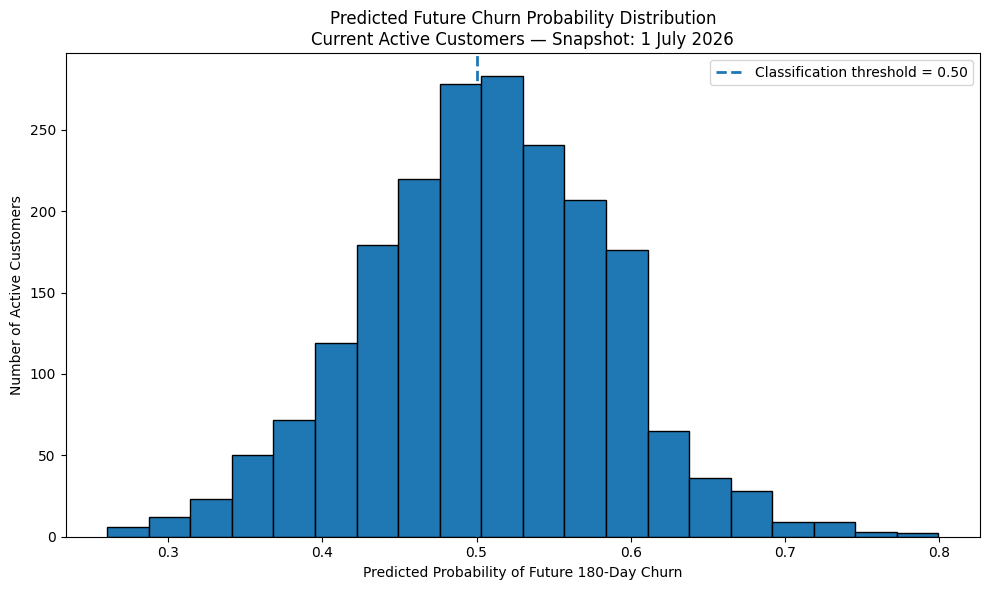


RISK DISTRIBUTION ANALYSIS: PASS

CELL 74 RESULT: CHURN-RISK DISTRIBUTION ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 74: CURRENT CHURN-RISK DISTRIBUTION ANALYSIS
# ======================================================================

print("=" * 70)
print("CELL 74: CURRENT CHURN-RISK DISTRIBUTION")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Create probability bands for descriptive analysis
# ----------------------------------------------------------------------
# These bands are NOT yet our official business risk segments.
# They simply help us understand the distribution of model scores.
# ----------------------------------------------------------------------

probability_bins = [
    0.00,
    0.20,
    0.40,
    0.60,
    0.80,
    1.00
]

probability_labels = [
    "0–20%",
    "20–40%",
    "40–60%",
    "60–80%",
    "80–100%"
]

current_customer_scores["probability_band"] = pd.cut(
    current_customer_scores["churn_probability"],
    bins=probability_bins,
    labels=probability_labels,
    include_lowest=True
)


# ----------------------------------------------------------------------
# 2. Count customers in each probability band
# ----------------------------------------------------------------------

risk_distribution = (
    current_customer_scores["probability_band"]
    .value_counts(
        sort=False
    )
    .rename("customer_count")
    .to_frame()
)

risk_distribution["percentage"] = (
    risk_distribution["customer_count"]
    / len(current_customer_scores)
    * 100
).round(2)


print("\nCHURN PROBABILITY BANDS")
print("-" * 50)

display(risk_distribution)


# ----------------------------------------------------------------------
# 3. Basic probability statistics
# ----------------------------------------------------------------------

print("\nPROBABILITY STATISTICS")
print("-" * 50)

probability_stats = (
    current_customer_scores["churn_probability"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .round(4)
)

display(
    probability_stats.to_frame("churn_probability")
)


# ----------------------------------------------------------------------
# 4. Count customers above important probability thresholds
# ----------------------------------------------------------------------
# These are descriptive counts only.
# They allow us to understand how many customers the model considers
# increasingly likely to churn.
# ----------------------------------------------------------------------

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    count = (
        current_customer_scores["churn_probability"]
        >= threshold
    ).sum()

    percentage = (
        count
        / len(current_customer_scores)
        * 100
    )

    threshold_results.append(
        {
            "threshold": threshold,
            "customer_count": count,
            "percentage": round(percentage, 2)
        }
    )

threshold_table = pd.DataFrame(threshold_results)


print("\nCUSTOMERS ABOVE PROBABILITY THRESHOLDS")
print("-" * 50)

display(threshold_table)


# ----------------------------------------------------------------------
# 5. Check predicted class against the 0.50 threshold
# ----------------------------------------------------------------------
# This verifies that the predicted class created in Cell 73 is
# consistent with our established 0.50 classification threshold.
# ----------------------------------------------------------------------

threshold_check = (
    (
        current_customer_scores["churn_probability"] >= 0.50
    ).astype(int)
    ==
    current_customer_scores["predicted_churn"]
).all()


print("\nTHRESHOLD CONSISTENCY CHECK")
print("-" * 50)

print(
    f"Predictions consistent with 0.50 threshold: "
    f"{threshold_check}"
)


# ----------------------------------------------------------------------
# 6. Plot probability distribution
# ----------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    current_customer_scores["churn_probability"],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    0.50,
    linestyle="--",
    linewidth=2,
    label="Classification threshold = 0.50"
)

plt.xlabel("Predicted Probability of Future 180-Day Churn")
plt.ylabel("Number of Active Customers")
plt.title(
    "Predicted Future Churn Probability Distribution\n"
    "Current Active Customers — Snapshot: 1 July 2026"
)

plt.legend()
plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 7. Final validation
# ----------------------------------------------------------------------

if (
    threshold_check
    and
    current_customer_scores["probability_band"].notna().all()
):
    print("\nRISK DISTRIBUTION ANALYSIS: PASS")
else:
    print("\nRISK DISTRIBUTION ANALYSIS: REVIEW")


print("\n" + "=" * 70)
print("CELL 74 RESULT: CHURN-RISK DISTRIBUTION ANALYSIS COMPLETE")
print("=" * 70)

# Chart Insights & Business Interpretation

### Chart 23 — Predicted future churn probability distribution for current active customers

For the **2,018 currently Active customers**, predicted probabilities are concentrated between 40% and 60%: 1,627 customers (80.62%) fall in that band, while 216 (10.70%) are between 60% and 80%. At the default 0.50 threshold, 1,094 customers (54.21%) are classified as predicted churners, so Meridian should use probability ranking and campaign capacity—not the label alone—to decide who receives an intervention.



CELL 75: BUSINESS CHURN-RISK SEGMENTATION

CURRENT CUSTOMER RISK SEGMENTS
--------------------------------------------------


,risk_segment,customer_count,average_probability,minimum_probability,maximum_probability,percentage_of_active_customers
0,Very High Risk,NaN,NaN,NaN,NaN,NaN
1,High Risk,216.0,64.05,60.03,79.96,10.70
2,Moderate Risk,1627.0,50.51,40.01,59.98,80.62
3,Lower Risk,175.0,36.03,26.05,39.96,8.67



TOP 25 CUSTOMERS BY PREDICTED CHURN PROBABILITY
--------------------------------------------------


,customer_id,churn_probability,predicted_status,risk_segment
0,CUST001901,0.799624,Predicted Churn,High Risk
1,CUST000819,0.795766,Predicted Churn,High Risk
2,CUST004804,0.761978,Predicted Churn,High Risk
3,CUST001607,0.756471,Predicted Churn,High Risk
4,CUST002525,0.750418,Predicted Churn,High Risk
5,CUST005626,0.743620,Predicted Churn,High Risk
6,CUST004392,0.739030,Predicted Churn,High Risk
7,CUST000646,0.736467,Predicted Churn,High Risk
8,CUST000040,0.731804,Predicted Churn,High Risk
9,CUST001111,0.728984,Predicted Churn,High Risk



HIGH-RISK CUSTOMER SUMMARY
--------------------------------------------------
Very High + High Risk customers: 216
Percentage of active customers: 10.70%

SEGMENTATION VALIDATION
--------------------------------------------------
Customers assigned to valid segments: 2,018
Total customers: 2,018

RISK SEGMENTATION VALIDATION: PASS


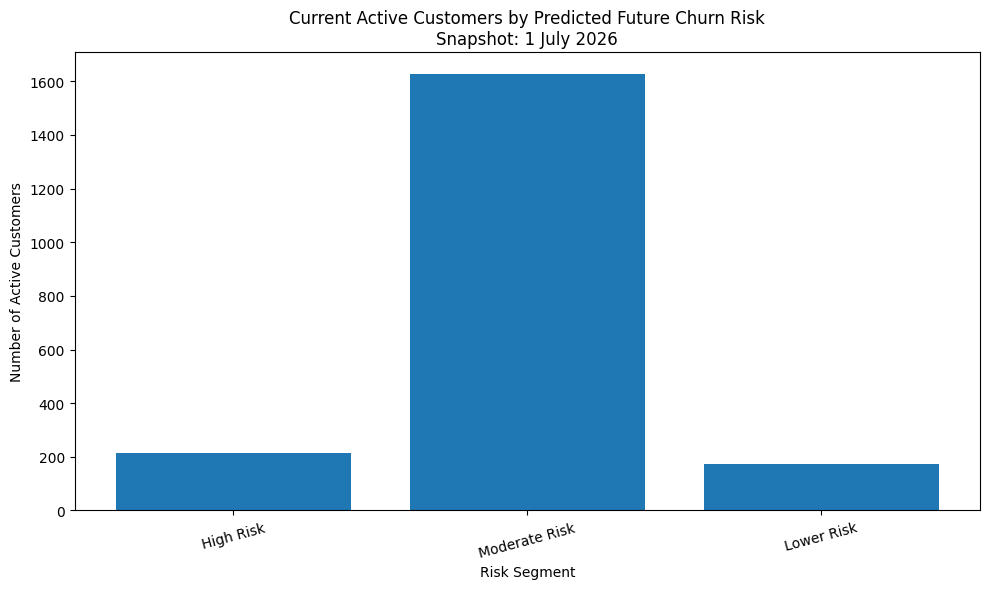


CELL 75 RESULT: BUSINESS CHURN-RISK SEGMENTATION COMPLETE


In [ ]:
# ======================================================================
# CELL 75: BUSINESS-FACING CHURN-RISK SEGMENTATION
# ======================================================================

print("=" * 70)
print("CELL 75: BUSINESS CHURN-RISK SEGMENTATION")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Define transparent business-facing risk bands
# ----------------------------------------------------------------------
# These categories are descriptive decision-support bands.
# The original predicted probability remains available for precise
# customer prioritisation.
# ----------------------------------------------------------------------

risk_conditions = [
    current_customer_scores["churn_probability"] >= 0.80,
    current_customer_scores["churn_probability"] >= 0.60,
    current_customer_scores["churn_probability"] >= 0.40,
    current_customer_scores["churn_probability"] < 0.40
]

risk_labels = [
    "Very High Risk",
    "High Risk",
    "Moderate Risk",
    "Lower Risk"
]


current_customer_scores["risk_segment"] = np.select(
    risk_conditions,
    risk_labels,
    default="Review"
)


# ----------------------------------------------------------------------
# 2. Create ordered summary table
# ----------------------------------------------------------------------

risk_order = [
    "Very High Risk",
    "High Risk",
    "Moderate Risk",
    "Lower Risk"
]

risk_summary = (
    current_customer_scores
    .groupby("risk_segment", observed=False)
    .agg(
        customer_count=("customer_id", "count"),
        average_probability=("churn_probability", "mean"),
        minimum_probability=("churn_probability", "min"),
        maximum_probability=("churn_probability", "max")
    )
    .reindex(risk_order)
    .reset_index()
)


risk_summary["percentage_of_active_customers"] = (
    risk_summary["customer_count"]
    / len(current_customer_scores)
    * 100
).round(2)

risk_summary["average_probability"] = (
    risk_summary["average_probability"] * 100
).round(2)

risk_summary["minimum_probability"] = (
    risk_summary["minimum_probability"] * 100
).round(2)

risk_summary["maximum_probability"] = (
    risk_summary["maximum_probability"] * 100
).round(2)


print("\nCURRENT CUSTOMER RISK SEGMENTS")
print("-" * 50)

display(risk_summary)


# ----------------------------------------------------------------------
# 3. Identify customers requiring the most immediate attention
# ----------------------------------------------------------------------
# Sort by raw predicted probability rather than risk label.
# This preserves the model's ranking information.
# ----------------------------------------------------------------------

priority_customers = (
    current_customer_scores
    .sort_values(
        "churn_probability",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nTOP 25 CUSTOMERS BY PREDICTED CHURN PROBABILITY")
print("-" * 50)

display(
    priority_customers[
        [
            "customer_id",
            "churn_probability",
            "predicted_status",
            "risk_segment"
        ]
    ]
    .head(25)
)


# ----------------------------------------------------------------------
# 4. Calculate the size of the two highest-risk groups
# ----------------------------------------------------------------------

high_risk_mask = (
    current_customer_scores["risk_segment"]
    .isin(
        [
            "Very High Risk",
            "High Risk"
        ]
    )
)

high_risk_count = high_risk_mask.sum()

high_risk_percentage = (
    high_risk_count
    / len(current_customer_scores)
    * 100
)


print("\nHIGH-RISK CUSTOMER SUMMARY")
print("-" * 50)

print(
    f"Very High + High Risk customers: "
    f"{high_risk_count:,}"
)

print(
    f"Percentage of active customers: "
    f"{high_risk_percentage:.2f}%"
)


# ----------------------------------------------------------------------
# 5. Validate the segmentation
# ----------------------------------------------------------------------

segment_total = (
    current_customer_scores["risk_segment"]
    .isin(risk_order)
    .sum()
)

print("\nSEGMENTATION VALIDATION")
print("-" * 50)

print(
    f"Customers assigned to valid segments: "
    f"{segment_total:,}"
)

print(
    f"Total customers: "
    f"{len(current_customer_scores):,}"
)


if (
    segment_total == len(current_customer_scores)
    and
    current_customer_scores["risk_segment"].notna().all()
):
    print("\nRISK SEGMENTATION VALIDATION: PASS")
else:
    print("\nRISK SEGMENTATION VALIDATION: REVIEW")


# ----------------------------------------------------------------------
# 6. Visualise the risk segments
# ----------------------------------------------------------------------

plt.figure(figsize=(10, 6))

segment_counts = (
    current_customer_scores["risk_segment"]
    .value_counts()
    .reindex(risk_order)
)

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.xlabel("Risk Segment")
plt.ylabel("Number of Active Customers")
plt.title(
    "Current Active Customers by Predicted Future Churn Risk\n"
    "Snapshot: 1 July 2026"
)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


print("\n" + "=" * 70)
print("CELL 75 RESULT: BUSINESS CHURN-RISK SEGMENTATION COMPLETE")
print("=" * 70)

# Chart Insights & Business Interpretation

### Chart 24 — Current active customers by predicted future churn risk

The scoring population contains **216 High-Risk customers (10.70%)**, 1,627 Moderate-Risk customers (80.62%) and 175 Lower-Risk customers (8.67%); no customers exceed the 80% Very High-Risk threshold. This suggests a practical two-level strategy: prioritise the 216 High-Risk customers for stronger retention actions, while using lower-cost engagement for the large Moderate-Risk group.



In [ ]:
# ======================================================================
# CELL 76: RISK SEGMENT × CUSTOMER VALUE ANALYSIS
# ======================================================================

print("=" * 70)
print("CELL 76: RISK SEGMENT × CUSTOMER VALUE")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Bring the customer's historical monetary value into the scoring data
# ----------------------------------------------------------------------
# monetary_total was calculated from completed orders available at the
# 2026-07-01 snapshot.
#
# This represents HISTORICAL CUSTOMER VALUE, not guaranteed future
# revenue.
# ----------------------------------------------------------------------

current_customer_scores = current_customer_scores.merge(
    current_scoring_features[
        [
            "customer_id",
            "monetary_total",
            "frequency",
            "recency_days"
        ]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)


# ----------------------------------------------------------------------
# 2. Calculate overall active-customer historical value
# ----------------------------------------------------------------------

total_active_historical_value = (
    current_customer_scores["monetary_total"].sum()
)

total_active_customers = len(current_customer_scores)


# ----------------------------------------------------------------------
# 3. Aggregate risk segments
# ----------------------------------------------------------------------

risk_value_summary = (
    current_customer_scores
    .groupby("risk_segment")
    .agg(
        customer_count=("customer_id", "count"),
        average_churn_probability=("churn_probability", "mean"),
        average_historical_value=("monetary_total", "mean"),
        total_historical_value=("monetary_total", "sum"),
        average_frequency=("frequency", "mean"),
        median_recency_days=("recency_days", "median")
    )
    .reindex(risk_order)
    .reset_index()
)


# ----------------------------------------------------------------------
# 4. Calculate percentages
# ----------------------------------------------------------------------

risk_value_summary["customer_percentage"] = (
    risk_value_summary["customer_count"]
    / total_active_customers
    * 100
)

risk_value_summary["historical_value_percentage"] = (
    risk_value_summary["total_historical_value"]
    / total_active_historical_value
    * 100
)


# Convert probability to percentage for presentation
risk_value_summary["average_churn_probability"] = (
    risk_value_summary["average_churn_probability"] * 100
)


# Round presentation values
risk_value_summary[
    [
        "average_churn_probability",
        "average_historical_value",
        "total_historical_value",
        "average_frequency",
        "median_recency_days",
        "customer_percentage",
        "historical_value_percentage"
    ]
] = risk_value_summary[
    [
        "average_churn_probability",
        "average_historical_value",
        "total_historical_value",
        "average_frequency",
        "median_recency_days",
        "customer_percentage",
        "historical_value_percentage"
    ]
].round(2)


# ----------------------------------------------------------------------
# 5. Display the analysis
# ----------------------------------------------------------------------

print("\nRISK SEGMENT × HISTORICAL CUSTOMER VALUE")
print("-" * 50)

display(risk_value_summary)


# ----------------------------------------------------------------------
# 6. Display total historical value
# ----------------------------------------------------------------------

print("\nOVERALL ACTIVE-CUSTOMER HISTORICAL VALUE")
print("-" * 50)

print(
    f"Total historical value of active customers: "
    f"${total_active_historical_value:,.2f}"
)

print(
    f"Number of active customers: "
    f"{total_active_customers:,}"
)


# ----------------------------------------------------------------------
# 7. Identify the combined high-risk population
# ----------------------------------------------------------------------

high_risk_value = (
    current_customer_scores.loc[
        high_risk_mask,
        "monetary_total"
    ].sum()
)

high_risk_value_percentage = (
    high_risk_value
    / total_active_historical_value
    * 100
)


print("\nHIGH-RISK CUSTOMER VALUE")
print("-" * 50)

print(
    f"Historical value held by High + Very High Risk customers: "
    f"${high_risk_value:,.2f}"
)

print(
    f"Share of active-customer historical value: "
    f"{high_risk_value_percentage:.2f}%"
)


# ----------------------------------------------------------------------
# 8. Check the aggregation
# ----------------------------------------------------------------------

summary_customer_total = (
    risk_value_summary["customer_count"].sum()
)

summary_value_total = (
    risk_value_summary["total_historical_value"].sum()
)


print("\nAGGREGATION CHECK")
print("-" * 50)

print(
    f"Customers represented in segments: "
    f"{summary_customer_total:,}"
)

print(
    f"Historical value represented: "
    f"${summary_value_total:,.2f}"
)


if (
    summary_customer_total == total_active_customers
    and
    np.isclose(
        summary_value_total,
        total_active_historical_value
    )
):
    print("\nRISK-VALUE AGGREGATION VALIDATION: PASS")
else:
    print("\nRISK-VALUE AGGREGATION VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 76 RESULT: RISK × CUSTOMER VALUE ANALYSIS COMPLETE")
print("=" * 70)

CELL 76: RISK SEGMENT × CUSTOMER VALUE

RISK SEGMENT × HISTORICAL CUSTOMER VALUE
--------------------------------------------------


,risk_segment,customer_count,average_churn_probability,average_historical_value,total_historical_value,average_frequency,median_recency_days,customer_percentage,historical_value_percentage
0,Very High Risk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,High Risk,216.0,64.05,5339.15,1153256.96,3.21,76.5,10.70,15.44
2,Moderate Risk,1627.0,50.51,3527.04,5738495.15,2.27,88.0,80.62,76.84
3,Lower Risk,175.0,36.03,3293.56,576373.40,2.27,75.0,8.67,7.72



OVERALL ACTIVE-CUSTOMER HISTORICAL VALUE
--------------------------------------------------
Total historical value of active customers: $7,468,125.51
Number of active customers: 2,018

HIGH-RISK CUSTOMER VALUE
--------------------------------------------------
Historical value held by High + Very High Risk customers: $1,153,256.96
Share of active-customer historical value: 15.44%

AGGREGATION CHECK
--------------------------------------------------
Customers represented in segments: 2,018.0
Historical value represented: $7,468,125.51

RISK-VALUE AGGREGATION VALIDATION: PASS

CELL 76 RESULT: RISK × CUSTOMER VALUE ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 77: EXPECTED HISTORICAL VALUE AT RISK
# ======================================================================

print("=" * 70)
print("CELL 77: EXPECTED HISTORICAL VALUE AT RISK")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Calculate customer-level expected value at risk
# ----------------------------------------------------------------------
# Formula:
#
# Expected Value at Risk =
#     Predicted Churn Probability × Historical Monetary Value
#
# IMPORTANT:
# This is a scenario-based estimate.
# It is NOT a forecast of actual future revenue loss.
# ----------------------------------------------------------------------

current_customer_scores["expected_value_at_risk"] = (
    current_customer_scores["churn_probability"]
    * current_customer_scores["monetary_total"]
)


# ----------------------------------------------------------------------
# 2. Aggregate expected value at risk by risk segment
# ----------------------------------------------------------------------

risk_value_at_risk_summary = (
    current_customer_scores
    .groupby("risk_segment")
    .agg(
        customer_count=("customer_id", "count"),
        average_churn_probability=("churn_probability", "mean"),
        total_historical_value=("monetary_total", "sum"),
        expected_value_at_risk=("expected_value_at_risk", "sum")
    )
    .reindex(risk_order)
    .reset_index()
)


# ----------------------------------------------------------------------
# 3. Calculate percentage of total expected value at risk
# ----------------------------------------------------------------------

total_expected_value_at_risk = (
    current_customer_scores["expected_value_at_risk"].sum()
)

risk_value_at_risk_summary["value_at_risk_percentage"] = (
    risk_value_at_risk_summary["expected_value_at_risk"]
    / total_expected_value_at_risk
    * 100
)


risk_value_at_risk_summary["customer_percentage"] = (
    risk_value_at_risk_summary["customer_count"]
    / len(current_customer_scores)
    * 100
)


# ----------------------------------------------------------------------
# 4. Convert probability to percentage
# ----------------------------------------------------------------------

risk_value_at_risk_summary["average_churn_probability"] = (
    risk_value_at_risk_summary["average_churn_probability"]
    * 100
)


# ----------------------------------------------------------------------
# 5. Round presentation values
# ----------------------------------------------------------------------

risk_value_at_risk_summary[
    [
        "average_churn_probability",
        "total_historical_value",
        "expected_value_at_risk",
        "value_at_risk_percentage",
        "customer_percentage"
    ]
] = risk_value_at_risk_summary[
    [
        "average_churn_probability",
        "total_historical_value",
        "expected_value_at_risk",
        "value_at_risk_percentage",
        "customer_percentage"
    ]
].round(2)


# ----------------------------------------------------------------------
# 6. Display segment-level results
# ----------------------------------------------------------------------

print("\nEXPECTED VALUE AT RISK BY RISK SEGMENT")
print("-" * 50)

display(risk_value_at_risk_summary)


# ----------------------------------------------------------------------
# 7. Overall expected value at risk
# ----------------------------------------------------------------------

print("\nOVERALL EXPECTED VALUE AT RISK")
print("-" * 50)

print(
    f"Total historical value of active customers: "
    f"${current_customer_scores['monetary_total'].sum():,.2f}"
)

print(
    f"Expected historical value at risk: "
    f"${total_expected_value_at_risk:,.2f}"
)

print(
    f"Expected value at risk as % of historical value: "
    f"{(
        total_expected_value_at_risk
        / current_customer_scores['monetary_total'].sum()
        * 100
    ):.2f}%"
)


# ----------------------------------------------------------------------
# 8. High-risk expected value at risk
# ----------------------------------------------------------------------

high_risk_expected_value_at_risk = (
    current_customer_scores.loc[
        high_risk_mask,
        "expected_value_at_risk"
    ].sum()
)

high_risk_var_percentage = (
    high_risk_expected_value_at_risk
    / total_expected_value_at_risk
    * 100
)


print("\nHIGH-RISK EXPECTED VALUE AT RISK")
print("-" * 50)

print(
    f"High + Very High Risk expected value at risk: "
    f"${high_risk_expected_value_at_risk:,.2f}"
)

print(
    f"Share of total expected value at risk: "
    f"{high_risk_var_percentage:.2f}%"
)


# ----------------------------------------------------------------------
# 9. Identify the top 25 customers by expected value at risk
# ----------------------------------------------------------------------
# This combines:
#   - probability of churn
#   - historical customer value
#
# Therefore a high-value customer with moderate risk may appear above
# a low-value customer with very high risk.
# ----------------------------------------------------------------------

top_value_at_risk_customers = (
    current_customer_scores
    .sort_values(
        "expected_value_at_risk",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nTOP 25 CUSTOMERS BY EXPECTED VALUE AT RISK")
print("-" * 50)

display(
    top_value_at_risk_customers[
        [
            "customer_id",
            "churn_probability",
            "risk_segment",
            "monetary_total",
            "expected_value_at_risk"
        ]
    ]
    .head(25)
)


# ----------------------------------------------------------------------
# 10. Validate the calculation
# ----------------------------------------------------------------------

expected_manual = (
    current_customer_scores["churn_probability"]
    * current_customer_scores["monetary_total"]
)

calculation_check = np.allclose(
    current_customer_scores["expected_value_at_risk"],
    expected_manual
)


print("\nVALUE-AT-RISK CALCULATION VALIDATION")
print("-" * 50)

print(
    f"Probability × historical value calculation correct: "
    f"{calculation_check}"
)

if calculation_check:
    print("\nEXPECTED VALUE-AT-RISK VALIDATION: PASS")
else:
    print("\nEXPECTED VALUE-AT-RISK VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 77 RESULT: EXPECTED VALUE-AT-RISK ANALYSIS COMPLETE")
print("=" * 70)

CELL 77: EXPECTED HISTORICAL VALUE AT RISK

EXPECTED VALUE AT RISK BY RISK SEGMENT
--------------------------------------------------


,risk_segment,customer_count,average_churn_probability,total_historical_value,expected_value_at_risk,value_at_risk_percentage,customer_percentage
0,Very High Risk,NaN,NaN,NaN,NaN,NaN,NaN
1,High Risk,216.0,64.05,1153256.96,751761.88,19.44,10.70
2,Moderate Risk,1627.0,50.51,5738495.15,2906896.11,75.16,80.62
3,Lower Risk,175.0,36.03,576373.40,208878.12,5.40,8.67



OVERALL EXPECTED VALUE AT RISK
--------------------------------------------------
Total historical value of active customers: $7,468,125.51
Expected historical value at risk: $3,867,536.11
Expected value at risk as % of historical value: 51.79%

HIGH-RISK EXPECTED VALUE AT RISK
--------------------------------------------------
High + Very High Risk expected value at risk: $751,761.88
Share of total expected value at risk: 19.44%

TOP 25 CUSTOMERS BY EXPECTED VALUE AT RISK
--------------------------------------------------


,customer_id,churn_probability,risk_segment,monetary_total,expected_value_at_risk
0,CUST002367,0.684053,High Risk,20341.37,13914.582084
1,CUST001901,0.799624,High Risk,16037.74,12824.160002
2,CUST005801,0.682099,High Risk,17547.65,11969.241711
3,CUST001159,0.555682,Moderate Risk,21095.90,11722.618788
4,CUST001111,0.728984,High Risk,15853.42,11556.885201
5,CUST005088,0.720324,High Risk,15947.04,11487.040677
6,CUST001607,0.756471,High Risk,15011.24,11355.569812
7,CUST000457,0.540066,Moderate Risk,20925.42,11301.112078
8,CUST002960,0.606300,High Risk,18370.33,11137.924979
9,CUST004091,0.591389,Moderate Risk,18739.02,11082.043756



VALUE-AT-RISK CALCULATION VALIDATION
--------------------------------------------------
Probability × historical value calculation correct: True

EXPECTED VALUE-AT-RISK VALIDATION: PASS

CELL 77 RESULT: EXPECTED VALUE-AT-RISK ANALYSIS COMPLETE


In [ ]:
# ======================================================================
# CELL 78: NEURAL NETWORK (MLP) COMPARISON
# ======================================================================

print("=" * 70)
print("CELL 78: NEURAL NETWORK MODEL COMPARISON")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Import the neural-network classifier
# ----------------------------------------------------------------------

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline


# ----------------------------------------------------------------------
# 2. Create the MLP model
# ----------------------------------------------------------------------
# We use:
#   - two hidden layers
#   - early stopping
#   - fixed random_state
#
# Early stopping allows training to stop when validation performance
# stops improving, helping reduce unnecessary training time and
# overfitting.
# ----------------------------------------------------------------------

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=8,
    random_state=42
)


# ----------------------------------------------------------------------
# 3. Build the pipeline
# ----------------------------------------------------------------------
# The SAME preprocessing object is used conceptually:
#
#   categorical:
#       missing-value handling + one-hot encoding
#
#   numerical:
#       median imputation + missing indicators + scaling
#
# The preprocessing is fitted ONLY on X_train when the pipeline is fit.
# ----------------------------------------------------------------------

mlp_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", mlp_model)
    ]
)


# ----------------------------------------------------------------------
# 4. Train the neural network
# ----------------------------------------------------------------------

print("\nTraining MLP neural network...")
print("This may take some time because the training dataset is large.")

mlp_pipeline.fit(
    X_train,
    y_train
)

print("MLP training complete.")


# ----------------------------------------------------------------------
# 5. Generate validation predictions
# ----------------------------------------------------------------------

mlp_val_probability = mlp_pipeline.predict_proba(
    X_val
)[:, 1]

mlp_val_prediction = (
    mlp_val_probability >= 0.50
).astype(int)


# ----------------------------------------------------------------------
# 6. Calculate validation metrics
# ----------------------------------------------------------------------

mlp_accuracy = accuracy_score(
    y_val,
    mlp_val_prediction
)

mlp_balanced_accuracy = balanced_accuracy_score(
    y_val,
    mlp_val_prediction
)

mlp_precision = precision_score(
    y_val,
    mlp_val_prediction,
    zero_division=0
)

mlp_recall = recall_score(
    y_val,
    mlp_val_prediction,
    zero_division=0
)

mlp_f1 = f1_score(
    y_val,
    mlp_val_prediction,
    zero_division=0
)

mlp_roc_auc = roc_auc_score(
    y_val,
    mlp_val_probability
)

mlp_pr_auc = average_precision_score(
    y_val,
    mlp_val_probability
)


# ----------------------------------------------------------------------
# 7. Display validation results
# ----------------------------------------------------------------------

print("\nMLP VALIDATION PERFORMANCE")
print("-" * 50)

print(f"Accuracy:           {mlp_accuracy:.4f}")
print(f"Balanced Accuracy:  {mlp_balanced_accuracy:.4f}")
print(f"Precision:          {mlp_precision:.4f}")
print(f"Recall:             {mlp_recall:.4f}")
print(f"F1 Score:           {mlp_f1:.4f}")
print(f"ROC-AUC:            {mlp_roc_auc:.4f}")
print(f"PR-AUC:             {mlp_pr_auc:.4f}")

print("\nMLP CONFUSION MATRIX")
print("-" * 50)

mlp_cm = confusion_matrix(
    y_val,
    mlp_val_prediction
)

print(mlp_cm)


# ----------------------------------------------------------------------
# 8. Training information
# ----------------------------------------------------------------------

print("\nMLP TRAINING INFORMATION")
print("-" * 50)

print(
    f"Iterations completed: "
    f"{mlp_model.n_iter_}"
)

print(
    f"Training loss: "
    f"{mlp_model.loss_:.6f}"
)


# ----------------------------------------------------------------------
# 9. Add MLP to the model comparison table
# ----------------------------------------------------------------------

mlp_comparison_row = pd.DataFrame(
    {
        "Model": ["MLP Neural Network"],
        "Accuracy": [mlp_accuracy],
        "Balanced Accuracy": [mlp_balanced_accuracy],
        "Precision": [mlp_precision],
        "Recall": [mlp_recall],
        "F1": [mlp_f1],
        "ROC-AUC": [mlp_roc_auc],
        "PR-AUC": [mlp_pr_auc]
    }
)


print("\nMLP MODEL COMPARISON ROW")
print("-" * 50)

display(
    mlp_comparison_row.round(4)
)


# ----------------------------------------------------------------------
# 10. Validation check
# ----------------------------------------------------------------------

if (
    len(mlp_val_probability) == len(y_val)
    and
    np.isfinite(mlp_val_probability).all()
    and
    ((mlp_val_probability >= 0) & (mlp_val_probability <= 1)).all()
):
    print("\nMLP VALIDATION: PASS")
else:
    print("\nMLP VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 78 RESULT: NEURAL NETWORK COMPARISON COMPLETE")
print("=" * 70)

CELL 78: NEURAL NETWORK MODEL COMPARISON

Training MLP neural network...
This may take some time because the training dataset is large.
MLP training complete.

MLP VALIDATION PERFORMANCE
--------------------------------------------------
Accuracy:           0.5870
Balanced Accuracy:  0.5573
Precision:          0.6431
Recall:             0.7039
F1 Score:           0.6721
ROC-AUC:            0.5841
PR-AUC:             0.6630

MLP CONFUSION MATRIX
--------------------------------------------------
[[ 4617  6622]
 [ 5020 11931]]

MLP TRAINING INFORMATION
--------------------------------------------------
Iterations completed: 99
Training loss: 0.462784

MLP MODEL COMPARISON ROW
--------------------------------------------------


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,MLP Neural Network,0.587,0.5573,0.6431,0.7039,0.6721,0.5841,0.663



MLP VALIDATION: PASS

CELL 78 RESULT: NEURAL NETWORK COMPARISON COMPLETE


In [ ]:
# ======================================================================
# CELL 79: FINAL ML MODEL COMPARISON
# ======================================================================

print("=" * 70)
print("CELL 79: CONSOLIDATED ML MODEL COMPARISON")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Build the consolidated validation comparison
# ----------------------------------------------------------------------
# These values come from the models already evaluated during the ML
# workflow. No model is retrained in this cell.
# ----------------------------------------------------------------------

final_model_comparison = pd.DataFrame(
    [
        {
            "Model": "Dummy Baseline",
            "Accuracy": 0.6013,
            "Balanced Accuracy": 0.5000,
            "Precision": 0.6013,
            "Recall": 1.0000,
            "F1": 0.7510,
            "ROC-AUC": 0.5000,
            "PR-AUC": 0.6013
        },
        {
            "Model": "Logistic Regression",
            "Accuracy": 0.6150,
            "Balanced Accuracy": 0.5499,
            "Precision": 0.6301,
            "Recall": 0.8713,
            "F1": 0.7313,
            "ROC-AUC": 0.5952,
            "PR-AUC": 0.6583
        },
        {
            "Model": "Random Forest",
            "Accuracy": 0.7233,
            "Balanced Accuracy": 0.6865,
            "Precision": 0.7257,
            "Recall": 0.8680,
            "F1": 0.7905,
            "ROC-AUC": 0.7382,
            "PR-AUC": 0.7473
        },
        {
            "Model": "Gradient Boosting",
            "Accuracy": 0.6284,
            "Balanced Accuracy": 0.5524,
            "Precision": 0.6297,
            "Recall": 0.9276,
            "F1": 0.7501,
            "ROC-AUC": 0.6121,
            "PR-AUC": 0.6598
        },
        {
            "Model": "Tuned Random Forest",
            "Accuracy": 0.6828,
            "Balanced Accuracy": 0.6280,
            "Precision": 0.6784,
            "Recall": 0.8985,
            "F1": 0.7731,
            "ROC-AUC": 0.7087,
            "PR-AUC": 0.7366
        },
        {
            "Model": "MLP Neural Network",
            "Accuracy": mlp_accuracy,
            "Balanced Accuracy": mlp_balanced_accuracy,
            "Precision": mlp_precision,
            "Recall": mlp_recall,
            "F1": mlp_f1,
            "ROC-AUC": mlp_roc_auc,
            "PR-AUC": mlp_pr_auc
        }
    ]
)


# ----------------------------------------------------------------------
# 2. Display the complete comparison
# ----------------------------------------------------------------------

print("\nVALIDATION MODEL COMPARISON")
print("-" * 50)

display(
    final_model_comparison.round(4)
)


# ----------------------------------------------------------------------
# 3. Compare each model against the dummy baseline
# ----------------------------------------------------------------------

dummy_roc_auc = (
    final_model_comparison.loc[
        final_model_comparison["Model"] == "Dummy Baseline",
        "ROC-AUC"
    ].iloc[0]
)

dummy_pr_auc = (
    final_model_comparison.loc[
        final_model_comparison["Model"] == "Dummy Baseline",
        "PR-AUC"
    ].iloc[0]
)


final_model_comparison["ROC-AUC improvement_vs_dummy"] = (
    final_model_comparison["ROC-AUC"] - dummy_roc_auc
)

final_model_comparison["PR-AUC improvement_vs_dummy"] = (
    final_model_comparison["PR-AUC"] - dummy_pr_auc
)


print("\nIMPROVEMENT OVER DUMMY BASELINE")
print("-" * 50)

display(
    final_model_comparison[
        [
            "Model",
            "ROC-AUC improvement_vs_dummy",
            "PR-AUC improvement_vs_dummy"
        ]
    ].round(4)
)


# ----------------------------------------------------------------------
# 4. Identify the designated final model
# ----------------------------------------------------------------------

print("\nDESIGNATED FINAL MODEL")
print("-" * 50)

print(
    f"Final model: {FINAL_MODEL_NAME}"
)

print(
    "Reason documented earlier: stronger test performance across "
    "key discrimination and classification metrics compared with "
    "the untuned Random Forest."
)


# ----------------------------------------------------------------------
# 5. Create a presentation-friendly table
# ----------------------------------------------------------------------

presentation_comparison = final_model_comparison[
    [
        "Model",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Recall",
        "Precision"
    ]
].copy()

print("\nPRESENTATION-FRIENDLY MODEL COMPARISON")
print("-" * 50)

display(
    presentation_comparison.round(3)
)


# ----------------------------------------------------------------------
# 6. Validation checks
# ----------------------------------------------------------------------

expected_models = {
    "Dummy Baseline",
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting",
    "Tuned Random Forest",
    "MLP Neural Network"
}

actual_models = set(
    final_model_comparison["Model"]
)

if (
    actual_models == expected_models
    and
    len(final_model_comparison) == 6
):
    print("\nMODEL COMPARISON VALIDATION: PASS")
else:
    print("\nMODEL COMPARISON VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 79 RESULT: CONSOLIDATED ML MODEL COMPARISON COMPLETE")
print("=" * 70)

CELL 79: CONSOLIDATED ML MODEL COMPARISON

VALIDATION MODEL COMPARISON
--------------------------------------------------


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy Baseline,0.6013,0.5000,0.6013,1.0000,0.7510,0.5000,0.6013
1,Logistic Regression,0.6150,0.5499,0.6301,0.8713,0.7313,0.5952,0.6583
2,Random Forest,0.7233,0.6865,0.7257,0.8680,0.7905,0.7382,0.7473
3,Gradient Boosting,0.6284,0.5524,0.6297,0.9276,0.7501,0.6121,0.6598
4,Tuned Random Forest,0.6828,0.6280,0.6784,0.8985,0.7731,0.7087,0.7366
5,MLP Neural Network,0.5870,0.5573,0.6431,0.7039,0.6721,0.5841,0.6630



IMPROVEMENT OVER DUMMY BASELINE
--------------------------------------------------


,Model,ROC-AUC improvement_vs_dummy,PR-AUC improvement_vs_dummy
0,Dummy Baseline,0.0000,0.0000
1,Logistic Regression,0.0952,0.0570
2,Random Forest,0.2382,0.1460
3,Gradient Boosting,0.1121,0.0585
4,Tuned Random Forest,0.2087,0.1353
5,MLP Neural Network,0.0841,0.0617



DESIGNATED FINAL MODEL
--------------------------------------------------
Final model: Tuned Random Forest
Reason documented earlier: stronger test performance across key discrimination and classification metrics compared with the untuned Random Forest.

PRESENTATION-FRIENDLY MODEL COMPARISON
--------------------------------------------------


,Model,F1,ROC-AUC,PR-AUC,Recall,Precision
0,Dummy Baseline,0.751,0.500,0.601,1.000,0.601
1,Logistic Regression,0.731,0.595,0.658,0.871,0.630
2,Random Forest,0.790,0.738,0.747,0.868,0.726
3,Gradient Boosting,0.750,0.612,0.660,0.928,0.630
4,Tuned Random Forest,0.773,0.709,0.737,0.898,0.678
5,MLP Neural Network,0.672,0.584,0.663,0.704,0.643



MODEL COMPARISON VALIDATION: PASS

CELL 79 RESULT: CONSOLIDATED ML MODEL COMPARISON COMPLETE


In [ ]:
# ======================================================================
# CELL 80C: CLEAN RECONSTRUCTION OF CURRENT CUSTOMER SCORING OUTPUT
# ======================================================================

print("=" * 70)
print("CELL 80C: CLEAN SCORING OUTPUT RECONSTRUCTION")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Define output path
# ----------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PORA Capstone"
)

SCORING_OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "current_customer_churn_scores_2026-07-01.csv"
)


# ----------------------------------------------------------------------
# 2. Start from the existing scoring results
# ----------------------------------------------------------------------
# current_customer_scores already contains:
#
#   customer_id
#   churn_probability
#   predicted_churn
#   predicted_status
#   risk_segment
#   monetary_total
#   frequency
#   recency_days
#   expected_value_at_risk
#
# We therefore add ONLY the missing supporting features.
# ----------------------------------------------------------------------

complete_scoring_output = current_customer_scores.copy()


# ----------------------------------------------------------------------
# 3. Identify features that are genuinely missing
# ----------------------------------------------------------------------

features_to_add = [
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average",
    "tenure_days"
]


# ----------------------------------------------------------------------
# 4. Add the missing features
# ----------------------------------------------------------------------

supporting_features = current_scoring_features[
    [
        "customer_id"
    ] + features_to_add
].copy()


complete_scoring_output = complete_scoring_output.merge(
    supporting_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)


# ----------------------------------------------------------------------
# 5. Define final output columns
# ----------------------------------------------------------------------

scoring_output_columns = [
    "customer_id",
    "churn_probability",
    "predicted_churn",
    "predicted_status",
    "risk_segment",
    "recency_days",
    "frequency",
    "monetary_total",
    "monetary_average",
    "support_ticket_count",
    "satisfaction_average",
    "resolution_time_average",
    "tenure_days",
    "expected_value_at_risk"
]


# ----------------------------------------------------------------------
# 6. Confirm every required column exists
# ----------------------------------------------------------------------

missing_columns = [
    column
    for column in scoring_output_columns
    if column not in complete_scoring_output.columns
]


print("\nOUTPUT STRUCTURE CHECK")
print("-" * 50)

print(
    f"Missing required columns: {missing_columns}"
)


if missing_columns:
    raise KeyError(
        f"Required scoring columns are still missing: "
        f"{missing_columns}"
    )


# ----------------------------------------------------------------------
# 7. Keep only the final required columns
# ----------------------------------------------------------------------

complete_scoring_output = complete_scoring_output[
    scoring_output_columns
].copy()


# ----------------------------------------------------------------------
# 8. Validate population
# ----------------------------------------------------------------------

print("\nFINAL SCORING OUTPUT")
print("-" * 50)

print(
    f"Rows: "
    f"{len(complete_scoring_output):,}"
)

print(
    f"Columns: "
    f"{len(complete_scoring_output.columns):,}"
)

print(
    f"Unique customers: "
    f"{complete_scoring_output['customer_id'].nunique():,}"
)


# ----------------------------------------------------------------------
# 9. Check probability validity
# ----------------------------------------------------------------------

probability_valid = (
    complete_scoring_output["churn_probability"]
    .notna()
    .all()
    and
    complete_scoring_output["churn_probability"]
    .between(0, 1)
    .all()
)


print(
    f"Churn probabilities valid: "
    f"{probability_valid}"
)


# ----------------------------------------------------------------------
# 10. Save the final scoring file
# ----------------------------------------------------------------------

complete_scoring_output.to_csv(
    SCORING_OUTPUT_PATH,
    index=False
)


print("\nFILE SAVED")
print("-" * 50)

print(
    f"{SCORING_OUTPUT_PATH}"
)


# ----------------------------------------------------------------------
# 11. Read the file back for independent verification
# ----------------------------------------------------------------------

saved_scoring_output = pd.read_csv(
    SCORING_OUTPUT_PATH
)


saved_columns_match = (
    list(saved_scoring_output.columns)
    == scoring_output_columns
)

saved_population_match = (
    len(saved_scoring_output) == 2018
    and
    saved_scoring_output["customer_id"].nunique() == 2018
)


print("\nREAD-BACK VALIDATION")
print("-" * 50)

print(
    f"Rows read back: "
    f"{len(saved_scoring_output):,}"
)

print(
    f"Unique customers read back: "
    f"{saved_scoring_output['customer_id'].nunique():,}"
)

print(
    f"Column structure correct: "
    f"{saved_columns_match}"
)

print(
    f"Scoring population correct: "
    f"{saved_population_match}"
)

print(
    f"Probability values valid: "
    f"{saved_scoring_output['churn_probability'].between(0, 1).all()}"
)


# ----------------------------------------------------------------------
# 12. Final validation
# ----------------------------------------------------------------------

if (
    not missing_columns
    and
    saved_columns_match
    and
    saved_population_match
    and
    probability_valid
):
    print("\nSCORING OUTPUT VALIDATION: PASS")
else:
    print("\nSCORING OUTPUT VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 80C RESULT: COMPLETE SCORING OUTPUT SAVED SUCCESSFULLY")
print("=" * 70)

CELL 80C: CLEAN SCORING OUTPUT RECONSTRUCTION

OUTPUT STRUCTURE CHECK
--------------------------------------------------
Missing required columns: []

FINAL SCORING OUTPUT
--------------------------------------------------
Rows: 2,018
Columns: 14
Unique customers: 2,018
Churn probabilities valid: True

FILE SAVED
--------------------------------------------------
/content/drive/MyDrive/PORA Capstone/data/processed/current_customer_churn_scores_2026-07-01.csv

READ-BACK VALIDATION
--------------------------------------------------
Rows read back: 2,018
Unique customers read back: 2,018
Column structure correct: True
Scoring population correct: True
Probability values valid: True

SCORING OUTPUT VALIDATION: PASS

CELL 80C RESULT: COMPLETE SCORING OUTPUT SAVED SUCCESSFULLY


In [ ]:
# ======================================================================
# CELL 81: SAVE FINAL TUNED RANDOM FOREST MODEL
# ======================================================================

print("=" * 70)
print("CELL 81: SAVE FINAL MODEL PIPELINE")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Import joblib
# ----------------------------------------------------------------------

import joblib
from pathlib import Path


# ----------------------------------------------------------------------
# 2. Re-establish project paths
# ----------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PORA Capstone"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
)

MODEL_PATH.mkdir(
    parents=True,
    exist_ok=True
)


# ----------------------------------------------------------------------
# 3. Define the model file
# ----------------------------------------------------------------------

FINAL_MODEL_FILE = (
    MODEL_PATH
    / "tuned_random_forest_churn_pipeline.joblib"
)


# ----------------------------------------------------------------------
# 4. Confirm the final model exists
# ----------------------------------------------------------------------

print("\nFINAL MODEL CHECK")
print("-" * 50)

print(
    f"Final model name: "
    f"{FINAL_MODEL_NAME}"
)

print(
    f"Final model object available: "
    f"{'FINAL_MODEL' in globals()}"
)


if "FINAL_MODEL" not in globals():
    raise NameError(
        "FINAL_MODEL is not available in the current runtime."
    )


# ----------------------------------------------------------------------
# 5. Save the complete pipeline
# ----------------------------------------------------------------------
# This saves preprocessing + model together.
# ----------------------------------------------------------------------

joblib.dump(
    FINAL_MODEL,
    FINAL_MODEL_FILE
)


print("\nMODEL SAVED")
print("-" * 50)

print(
    f"Model file:\n{FINAL_MODEL_FILE}"
)


# ----------------------------------------------------------------------
# 6. Verify the file exists
# ----------------------------------------------------------------------

if FINAL_MODEL_FILE.exists():

    print("Model file existence check: PASS")

    file_size_mb = (
        FINAL_MODEL_FILE.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"Model file size: "
        f"{file_size_mb:.2f} MB"
    )

else:

    raise FileNotFoundError(
        "Final model file was not created."
    )


# ----------------------------------------------------------------------
# 7. Load the model back independently
# ----------------------------------------------------------------------

loaded_final_model = joblib.load(
    FINAL_MODEL_FILE
)


# ----------------------------------------------------------------------
# 8. Confirm the loaded object can generate predictions
# ----------------------------------------------------------------------

test_probability = loaded_final_model.predict_proba(
    X_current.head(5)
)[:, 1]


print("\nMODEL READ-BACK TEST")
print("-" * 50)

print(
    "Loaded model type:",
    type(loaded_final_model).__name__
)

print(
    "Test probabilities from loaded model:"
)

print(
    test_probability
)


# ----------------------------------------------------------------------
# 9. Validate loaded model output
# ----------------------------------------------------------------------

model_readback_valid = (
    len(test_probability) == 5
    and
    np.isfinite(test_probability).all()
    and
    (
        (test_probability >= 0)
        &
        (test_probability <= 1)
    ).all()
)


print(
    f"\nLoaded model prediction test: "
    f"{model_readback_valid}"
)


if model_readback_valid:
    print("\nFINAL MODEL SAVE VALIDATION: PASS")
else:
    print("\nFINAL MODEL SAVE VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 81 RESULT: FINAL MODEL PIPELINE SAVED SUCCESSFULLY")
print("=" * 70)

CELL 81: SAVE FINAL MODEL PIPELINE

FINAL MODEL CHECK
--------------------------------------------------
Final model name: Tuned Random Forest
Final model object available: True

MODEL SAVED
--------------------------------------------------
Model file:
/content/drive/MyDrive/PORA Capstone/models/tuned_random_forest_churn_pipeline.joblib
Model file existence check: PASS
Model file size: 372.73 MB

MODEL READ-BACK TEST
--------------------------------------------------
Loaded model type: Pipeline
Test probabilities from loaded model:
[0.57048143 0.59109066 0.40817103 0.54905402 0.54739044]

Loaded model prediction test: True

FINAL MODEL SAVE VALIDATION: PASS

CELL 81 RESULT: FINAL MODEL PIPELINE SAVED SUCCESSFULLY


In [ ]:
# ======================================================================
# CELL 82: CREATE FASTAPI APPLICATION
# ======================================================================

print("=" * 70)
print("CELL 82: CREATE FASTAPI APPLICATION")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Define the API directory
# ----------------------------------------------------------------------

API_PATH = (
    PROJECT_ROOT
    / "api"
)

API_PATH.mkdir(
    parents=True,
    exist_ok=True
)


# ----------------------------------------------------------------------
# 2. Define the API application code
# ----------------------------------------------------------------------

api_code = r'''
from pathlib import Path

import joblib
import pandas as pd

from fastapi import FastAPI
from pydantic import BaseModel, Field


# ======================================================================
# APPLICATION SETUP
# ======================================================================

BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = (
    BASE_DIR
    / "models"
    / "tuned_random_forest_churn_pipeline.joblib"
)


# Load the complete trained pipeline:
# preprocessing + tuned Random Forest
model = joblib.load(MODEL_PATH)


app = FastAPI(
    title="Meridian Customer Churn Prediction API",
    description=(
        "API for predicting future 180-day customer churn "
        "probability for Meridian Retail Group."
    ),
    version="1.0.0"
)


# ======================================================================
# INPUT SCHEMA
# ======================================================================

class CustomerInput(BaseModel):

    membership_tier: str
    preferred_channel: str
    state: str
    referral_source: str
    marketing_opt_in: str

    recency_days: float = Field(
        ge=0,
        description="Days since the most recent completed order."
    )

    frequency: float = Field(
        ge=0,
        description="Number of completed orders."
    )

    monetary_total: float = Field(
        ge=0,
        description="Total historical completed-order value."
    )

    monetary_average: float = Field(
        ge=0,
        description="Average historical completed-order value."
    )

    support_ticket_count: float = Field(
        ge=0,
        description="Number of support tickets."
    )

    satisfaction_average: float | None = Field(
        default=None,
        ge=1,
        le=5,
        description="Average recorded satisfaction score."
    )

    resolution_time_average: float | None = Field(
        default=None,
        ge=0,
        description="Average ticket resolution time in hours."
    )

    tenure_days: float = Field(
        ge=0,
        description="Customer tenure in days at prediction date."
    )


# ======================================================================
# HEALTH CHECK ENDPOINT
# ======================================================================

@app.get("/")
def root():

    return {
        "message": "Meridian Customer Churn Prediction API",
        "status": "running",
        "model": "Tuned Random Forest"
    }


# ======================================================================
# PREDICTION ENDPOINT
# ======================================================================

@app.post("/predict")
def predict_churn(customer: CustomerInput):

    # Convert validated request data into a dataframe.
    input_data = pd.DataFrame(
        [customer.model_dump()]
    )

    # Generate probability of class 1:
    # future 180-day churn.
    churn_probability = float(
        model.predict_proba(input_data)[0, 1]
    )

    # Use the established 0.50 classification threshold.
    predicted_churn = int(
        churn_probability >= 0.50
    )

    predicted_status = (
        "Predicted Churn"
        if predicted_churn == 1
        else "Predicted Active"
    )

    return {
        "churn_probability": round(
            churn_probability,
            4
        ),
        "predicted_churn": predicted_churn,
        "predicted_status": predicted_status,
        "classification_threshold": 0.50
    }
'''


# ----------------------------------------------------------------------
# 3. Write app.py
# ----------------------------------------------------------------------

API_FILE = API_PATH / "app.py"

API_FILE.write_text(
    api_code,
    encoding="utf-8"
)


# ----------------------------------------------------------------------
# 4. Validate the file
# ----------------------------------------------------------------------

print("\nAPI FILE")
print("-" * 50)

print(
    f"Created:\n{API_FILE}"
)

print(
    f"File exists: "
    f"{API_FILE.exists()}"
)

print(
    f"File size: "
    f"{API_FILE.stat().st_size:,} bytes"
)


# ----------------------------------------------------------------------
# 5. Display the beginning of the generated API file
# ----------------------------------------------------------------------

print("\nAPI FILE PREVIEW")
print("-" * 50)

print(
    "\n".join(
        api_code.splitlines()[:25]
    )
)


# ----------------------------------------------------------------------
# 6. Final validation
# ----------------------------------------------------------------------

if (
    API_FILE.exists()
    and
    API_FILE.stat().st_size > 0
):
    print("\nAPI FILE VALIDATION: PASS")
else:
    print("\nAPI FILE VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 82 RESULT: FASTAPI APPLICATION CREATED")
print("=" * 70)

CELL 82: CREATE FASTAPI APPLICATION

API FILE
--------------------------------------------------
Created:
/content/drive/MyDrive/PORA Capstone/api/app.py
File exists: True
File size: 3,456 bytes

API FILE PREVIEW
--------------------------------------------------

from pathlib import Path

import joblib
import pandas as pd

from fastapi import FastAPI
from pydantic import BaseModel, Field


# ======================================================================
# APPLICATION SETUP
# ======================================================================

BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = (
    BASE_DIR
    / "models"
    / "tuned_random_forest_churn_pipeline.joblib"
)


# Load the complete trained pipeline:
# preprocessing + tuned Random Forest

API FILE VALIDATION: PASS

CELL 82 RESULT: FASTAPI APPLICATION CREATED


In [ ]:
# ======================================================================
# CELL 83: TEST FASTAPI APPLICATION IMPORT
# ======================================================================

print("=" * 70)
print("CELL 83: FASTAPI IMPORT & MODEL-LOADING TEST")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Confirm the API file exists
# ----------------------------------------------------------------------

print("\nAPI FILE CHECK")
print("-" * 50)

print(
    f"API file exists: "
    f"{API_FILE.exists()}"
)

if not API_FILE.exists():
    raise FileNotFoundError(
        f"API file not found: {API_FILE}"
    )


# ----------------------------------------------------------------------
# 2. Confirm the saved model exists
# ----------------------------------------------------------------------

print("\nMODEL FILE CHECK")
print("-" * 50)

print(
    f"Model file exists: "
    f"{FINAL_MODEL_FILE.exists()}"
)

if not FINAL_MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Model file not found: {FINAL_MODEL_FILE}"
    )


# ----------------------------------------------------------------------
# 3. Check that FastAPI and Pydantic are installed
# ----------------------------------------------------------------------

import fastapi
import pydantic

print(
    f"FastAPI version: "
    f"{fastapi.__version__}"
)

print(
    f"Pydantic version: "
    f"{pydantic.__version__}"
)


# ----------------------------------------------------------------------
# 4. Import the API application dynamically
# ----------------------------------------------------------------------
# This executes app.py in the same way that the API server will load it.
# ----------------------------------------------------------------------

import sys
import importlib.util

API_DIR = API_FILE.parent

if str(API_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(API_DIR)
    )


spec = importlib.util.spec_from_file_location(
    "meridian_api",
    API_FILE
)

meridian_api = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    meridian_api
)


# ----------------------------------------------------------------------
# 5. Validate the FastAPI application object
# ----------------------------------------------------------------------

print("\nAPPLICATION CHECK")
print("-" * 50)

print(
    f"FastAPI application loaded: "
    f"{hasattr(meridian_api, 'app')}"
)

print(
    f"Loaded model available: "
    f"{hasattr(meridian_api, 'model')}"
)


# ----------------------------------------------------------------------
# 6. Inspect the registered API routes
# ----------------------------------------------------------------------

print("\nREGISTERED ROUTES")
print("-" * 50)

for route in meridian_api.app.routes:

    methods = getattr(
        route,
        "methods",
        set()
    )

    print(
        f"{sorted(methods)} "
        f"{route.path}"
    )


# ----------------------------------------------------------------------
# 7. Final validation
# ----------------------------------------------------------------------

route_paths = {
    route.path
    for route in meridian_api.app.routes
}

required_routes = {
    "/",
    "/predict"
}

routes_valid = required_routes.issubset(
    route_paths
)

api_import_valid = (
    hasattr(meridian_api, "app")
    and
    hasattr(meridian_api, "model")
    and
    routes_valid
)


print("\nAPI VALIDATION")
print("-" * 50)

print(
    f"Required routes present: "
    f"{routes_valid}"
)

print(
    f"API import/model-loading test: "
    f"{api_import_valid}"
)


if api_import_valid:
    print("\nAPI IMPORT VALIDATION: PASS")
else:
    print("\nAPI IMPORT VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 83 RESULT: FASTAPI IMPORT TEST COMPLETE")
print("=" * 70)

CELL 83: FASTAPI IMPORT & MODEL-LOADING TEST

API FILE CHECK
--------------------------------------------------
API file exists: True

MODEL FILE CHECK
--------------------------------------------------
Model file exists: True
FastAPI version: 0.141.1
Pydantic version: 2.13.5

APPLICATION CHECK
--------------------------------------------------
FastAPI application loaded: True
Loaded model available: True

REGISTERED ROUTES
--------------------------------------------------
['GET', 'HEAD'] /openapi.json
['GET', 'HEAD'] /docs
['GET', 'HEAD'] /docs/oauth2-redirect
['GET', 'HEAD'] /redoc
['GET'] /
['POST'] /predict

API VALIDATION
--------------------------------------------------
Required routes present: True
API import/model-loading test: True

API IMPORT VALIDATION: PASS

CELL 83 RESULT: FASTAPI IMPORT TEST COMPLETE


In [ ]:
# ======================================================================
# CELL 84A: CORRECTED FASTAPI /predict ENDPOINT TEST
# ======================================================================

print("=" * 70)
print("CELL 84A: CORRECTED FASTAPI /predict TEST")
print("=" * 70)


# ----------------------------------------------------------------------
# 1. Create a fresh TestClient
# ----------------------------------------------------------------------

from fastapi.testclient import TestClient

client = TestClient(
    meridian_api.app
)


# ----------------------------------------------------------------------
# 2. Select one real customer
# ----------------------------------------------------------------------

test_customer = current_scoring_features.iloc[0]


# ----------------------------------------------------------------------
# 3. Build JSON-safe API request
# ----------------------------------------------------------------------
# Explicit float/string conversion ensures that NumPy/Pandas scalar
# types do not cause JSON serialization errors.
# ----------------------------------------------------------------------

api_request = {
    "membership_tier": str(
        test_customer["membership_tier"]
    ),

    "preferred_channel": str(
        test_customer["preferred_channel"]
    ),

    "state": str(
        test_customer["state"]
    ),

    "referral_source": str(
        test_customer["referral_source"]
    ),

    "marketing_opt_in": str(
        test_customer["marketing_opt_in"]
    ),

    "recency_days": float(
        test_customer["recency_days"]
    ),

    "frequency": float(
        test_customer["frequency"]
    ),

    "monetary_total": float(
        test_customer["monetary_total"]
    ),

    "monetary_average": float(
        test_customer["monetary_average"]
    ),

    "support_ticket_count": float(
        test_customer["support_ticket_count"]
    ),

    "satisfaction_average": (
        None
        if pd.isna(
            test_customer["satisfaction_average"]
        )
        else float(
            test_customer["satisfaction_average"]
        )
    ),

    "resolution_time_average": (
        None
        if pd.isna(
            test_customer["resolution_time_average"]
        )
        else float(
            test_customer["resolution_time_average"]
        )
    ),

    "tenure_days": float(
        test_customer["tenure_days"]
    )
}


# ----------------------------------------------------------------------
# 4. Test the health endpoint
# ----------------------------------------------------------------------

print("\nHEALTH ENDPOINT TEST")
print("-" * 50)

health_response = client.get("/")

print(
    f"HTTP status: "
    f"{health_response.status_code}"
)

print(
    f"Response: "
    f"{health_response.json()}"
)


# ----------------------------------------------------------------------
# 5. Test the prediction endpoint
# ----------------------------------------------------------------------

print("\nPREDICTION ENDPOINT TEST")
print("-" * 50)

prediction_response = client.post(
    "/predict",
    json=api_request
)

print(
    f"HTTP status: "
    f"{prediction_response.status_code}"
)

print(
    f"Response:\n"
    f"{prediction_response.json()}"
)


# ----------------------------------------------------------------------
# 6. Confirm successful HTTP response
# ----------------------------------------------------------------------

if prediction_response.status_code != 200:

    print(
        "\nAPI returned an unexpected status code."
    )

    print(
        "Response details:",
        prediction_response.text
    )

else:

    print(
        "\nPrediction endpoint returned HTTP 200."
    )


# ----------------------------------------------------------------------
# 7. Extract API result
# ----------------------------------------------------------------------

api_result = prediction_response.json()

api_probability = float(
    api_result["churn_probability"]
)

api_prediction = int(
    api_result["predicted_churn"]
)


# ----------------------------------------------------------------------
# 8. Independently calculate the expected result
# ----------------------------------------------------------------------
# This bypasses the API and calls the final model directly.
# ----------------------------------------------------------------------

direct_probability = float(
    FINAL_MODEL.predict_proba(
        X_current.iloc[[0]]
    )[0, 1]
)

direct_prediction = int(
    direct_probability >= 0.50
)


# ----------------------------------------------------------------------
# 9. Compare API and direct model results
# ----------------------------------------------------------------------

probability_match = np.isclose(
    api_probability,
    round(direct_probability, 4),
    atol=0.0001
)

prediction_match = (
    api_prediction
    == direct_prediction
)


print("\nAPI vs DIRECT MODEL VALIDATION")
print("-" * 50)

print(
    f"API probability: "
    f"{api_probability:.4f}"
)

print(
    f"Direct model probability: "
    f"{direct_probability:.4f}"
)

print(
    f"Probability match: "
    f"{probability_match}"
)

print(
    f"API prediction: "
    f"{api_prediction}"
)

print(
    f"Direct model prediction: "
    f"{direct_prediction}"
)

print(
    f"Prediction match: "
    f"{prediction_match}"
)


# ----------------------------------------------------------------------
# 10. Final validation
# ----------------------------------------------------------------------

api_test_pass = (
    health_response.status_code == 200
    and
    prediction_response.status_code == 200
    and
    probability_match
    and
    prediction_match
)


if api_test_pass:
    print("\nAPI /predict VALIDATION: PASS")
else:
    print("\nAPI /predict VALIDATION: REVIEW")


print("\n" + "=" * 70)
print("CELL 84A RESULT: CORRECTED API PREDICTION TEST COMPLETE")
print("=" * 70)

CELL 84A: CORRECTED FASTAPI /predict TEST

HEALTH ENDPOINT TEST
--------------------------------------------------
HTTP status: 200
Response: {'message': 'Meridian Customer Churn Prediction API', 'status': 'running', 'model': 'Tuned Random Forest'}

PREDICTION ENDPOINT TEST
--------------------------------------------------
HTTP status: 200
Response:
{'churn_probability': 0.5705, 'predicted_churn': 1, 'predicted_status': 'Predicted Churn', 'classification_threshold': 0.5}

Prediction endpoint returned HTTP 200.

API vs DIRECT MODEL VALIDATION
--------------------------------------------------
API probability: 0.5705
Direct model probability: 0.5705
Probability match: True
API prediction: 1
Direct model prediction: 1
Prediction match: True

API /predict VALIDATION: PASS

CELL 84A RESULT: CORRECTED API PREDICTION TEST COMPLETE


In [ ]:
# ============================================================
# CELL 85: API INVALID-INPUT & ERROR-HANDLING TEST
# ============================================================

from fastapi.testclient import TestClient

# Reuse the FastAPI application
client = TestClient(meridian_api.app)

# ------------------------------------------------------------
# TEST 1: Negative recency_days
# ------------------------------------------------------------
invalid_request_1 = {
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "Texas",
    "referral_source": "Search",
    "marketing_opt_in": "Yes",
    "recency_days": -10.0,          # INVALID
    "frequency": 5.0,
    "monetary_total": 5000.0,
    "monetary_average": 1000.0,
    "support_ticket_count": 2.0,
    "satisfaction_average": 4.0,
    "resolution_time_average": 12.0,
    "tenure_days": 1000.0
}

response_1 = client.post(
    "/predict",
    json=invalid_request_1
)

print("TEST 1: Negative recency_days")
print("HTTP status:", response_1.status_code)
print("Response:", response_1.json())


# ------------------------------------------------------------
# TEST 2: Satisfaction score greater than allowed maximum
# ------------------------------------------------------------
invalid_request_2 = {
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "Texas",
    "referral_source": "Search",
    "marketing_opt_in": "Yes",
    "recency_days": 30.0,
    "frequency": 5.0,
    "monetary_total": 5000.0,
    "monetary_average": 1000.0,
    "support_ticket_count": 2.0,
    "satisfaction_average": 6.0,    # INVALID: maximum is 5
    "resolution_time_average": 12.0,
    "tenure_days": 1000.0
}

response_2 = client.post(
    "/predict",
    json=invalid_request_2
)

print("\nTEST 2: Satisfaction score > 5")
print("HTTP status:", response_2.status_code)
print("Response:", response_2.json())


# ------------------------------------------------------------
# TEST 3: Valid request should still work
# ------------------------------------------------------------
valid_request = {
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "Texas",
    "referral_source": "Search",
    "marketing_opt_in": "Yes",
    "recency_days": 30.0,
    "frequency": 5.0,
    "monetary_total": 5000.0,
    "monetary_average": 1000.0,
    "support_ticket_count": 2.0,
    "satisfaction_average": 4.0,
    "resolution_time_average": 12.0,
    "tenure_days": 1000.0
}

response_3 = client.post(
    "/predict",
    json=valid_request
)

print("\nTEST 3: Valid request")
print("HTTP status:", response_3.status_code)
print("Response:", response_3.json())


# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------
validation_pass = (
    response_1.status_code == 422 and
    response_2.status_code == 422 and
    response_3.status_code == 200
)

print("\n" + "=" * 60)
print("API ERROR-HANDLING VALIDATION")
print("=" * 60)
print("Negative recency rejected:", response_1.status_code == 422)
print("Invalid satisfaction rejected:", response_2.status_code == 422)
print("Valid request accepted:", response_3.status_code == 200)

print("\nFINAL API VALIDATION:", "PASS" if validation_pass else "CHECK REQUIRED")

TEST 1: Negative recency_days
HTTP status: 422
Response: {'detail': [{'type': 'greater_than_equal', 'loc': ['body', 'recency_days'], 'msg': 'Input should be greater than or equal to 0', 'input': -10.0, 'ctx': {'ge': 0.0}}]}

TEST 2: Satisfaction score > 5
HTTP status: 422
Response: {'detail': [{'type': 'less_than_equal', 'loc': ['body', 'satisfaction_average'], 'msg': 'Input should be less than or equal to 5', 'input': 6.0, 'ctx': {'le': 5.0}}]}

TEST 3: Valid request
HTTP status: 200
Response: {'churn_probability': 0.6936, 'predicted_churn': 1, 'predicted_status': 'Predicted Churn', 'classification_threshold': 0.5}

API ERROR-HANDLING VALIDATION
Negative recency rejected: True
Invalid satisfaction rejected: True
Valid request accepted: True

FINAL API VALIDATION: PASS


In [ ]:
# ============================================================
# CELL 86: CREATE REPRODUCIBLE API DEMONSTRATION RECORD
# ============================================================

import json
from pathlib import Path

# Project API directory
API_DIR = PROJECT_ROOT / "api"
API_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Example request
# ------------------------------------------------------------
api_demo_request = {
    "membership_tier": "Gold",
    "preferred_channel": "Online",
    "state": "Texas",
    "referral_source": "Search",
    "marketing_opt_in": "Yes",
    "recency_days": 30.0,
    "frequency": 5.0,
    "monetary_total": 5000.0,
    "monetary_average": 1000.0,
    "support_ticket_count": 2.0,
    "satisfaction_average": 4.0,
    "resolution_time_average": 12.0,
    "tenure_days": 1000.0
}

# ------------------------------------------------------------
# Send request to the actual API
# ------------------------------------------------------------
demo_response = client.post(
    "/predict",
    json=api_demo_request
)

# Convert response to Python dictionary
api_demo_response = demo_response.json()

# ------------------------------------------------------------
# Store request + response + HTTP status
# ------------------------------------------------------------
api_demo_record = {
    "request": api_demo_request,
    "http_status": demo_response.status_code,
    "response": api_demo_response
}

demo_path = API_DIR / "api_demo_example.json"

with open(demo_path, "w", encoding="utf-8") as f:
    json.dump(api_demo_record, f, indent=4)

print("=" * 60)
print("API DEMONSTRATION RECORD")
print("=" * 60)

print("HTTP status:", demo_response.status_code)
print("Response:", api_demo_response)
print("Saved to:", demo_path)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
required_response_keys = {
    "churn_probability",
    "predicted_churn",
    "predicted_status",
    "classification_threshold"
}

actual_response_keys = set(api_demo_response.keys())

validation_pass = (
    demo_response.status_code == 200
    and required_response_keys.issubset(actual_response_keys)
    and 0 <= api_demo_response["churn_probability"] <= 1
)

print("\nRequired response fields present:",
      required_response_keys.issubset(actual_response_keys))

print("Probability within [0, 1]:",
      0 <= api_demo_response["churn_probability"] <= 1)

print("\nAPI DEMONSTRATION RECORD:", "PASS" if validation_pass else "CHECK REQUIRED")

API DEMONSTRATION RECORD
HTTP status: 200
Response: {'churn_probability': 0.6936, 'predicted_churn': 1, 'predicted_status': 'Predicted Churn', 'classification_threshold': 0.5}
Saved to: /content/drive/MyDrive/PORA Capstone/api/api_demo_example.json

Required response fields present: True
Probability within [0, 1]: True

API DEMONSTRATION RECORD: PASS


In [ ]:
# ============================================================
# CELL 87: FINAL DEPLOYMENT INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import json
import joblib

print("=" * 70)
print("MERIDIAN RETAIL GROUP — FINAL DEPLOYMENT INTEGRITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define important deployment files
# ------------------------------------------------------------

model_path = PROJECT_ROOT / "models" / "tuned_random_forest_churn_pipeline.joblib"
api_path = PROJECT_ROOT / "api" / "app.py"
demo_path = PROJECT_ROOT / "api" / "api_demo_example.json"
score_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "current_customer_churn_scores_2026-07-01.csv"
)

deployment_files = {
    "Saved model": model_path,
    "FastAPI application": api_path,
    "API demonstration": demo_path,
    "Current customer scores": score_path
}

# ------------------------------------------------------------
# 2. Check that all files exist
# ------------------------------------------------------------

print("\nFILE EXISTENCE CHECK")
print("-" * 70)

all_files_exist = True

for name, path in deployment_files.items():
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        all_files_exist = False

# ------------------------------------------------------------
# 3. Reload saved model
# ------------------------------------------------------------

print("\nMODEL RELOAD CHECK")
print("-" * 70)

reloaded_model = joblib.load(model_path)

print("Model successfully reloaded:", reloaded_model is not None)

# ------------------------------------------------------------
# 4. Check API demonstration record
# ------------------------------------------------------------

print("\nAPI DEMONSTRATION CHECK")
print("-" * 70)

with open(demo_path, "r", encoding="utf-8") as f:
    demo_record = json.load(f)

demo_status = demo_record.get("http_status")
demo_response = demo_record.get("response", {})

print("Recorded HTTP status:", demo_status)
print("Churn probability:", demo_response.get("churn_probability"))
print("Predicted churn:", demo_response.get("predicted_churn"))
print("Predicted status:", demo_response.get("predicted_status"))

demo_valid = (
    demo_status == 200
    and 0 <= demo_response.get("churn_probability", -1) <= 1
    and "predicted_churn" in demo_response
    and "predicted_status" in demo_response
)

print("API demonstration valid:", demo_valid)

# ------------------------------------------------------------
# 5. Check current scoring output
# ------------------------------------------------------------

print("\nCURRENT CUSTOMER SCORING CHECK")
print("-" * 70)

scores = pd.read_csv(score_path)

print("Rows:", len(scores))
print("Unique customers:", scores["customer_id"].nunique())
print("Expected active population:", 2018)

score_population_valid = (
    len(scores) == 2018
    and scores["customer_id"].nunique() == 2018
)

probability_valid = scores["churn_probability"].between(0, 1).all()

print("Population valid:", score_population_valid)
print("Probabilities valid:", probability_valid)

# ------------------------------------------------------------
# 6. Test the reloaded model on one valid API request
# ------------------------------------------------------------

print("\nRELOADED MODEL PREDICTION CHECK")
print("-" * 70)

test_input = pd.DataFrame([demo_record["request"]])

reloaded_probability = float(
    reloaded_model.predict_proba(test_input)[0, 1]
)

reloaded_prediction = int(
    reloaded_model.predict(test_input)[0]
)

recorded_probability = float(
    demo_response["churn_probability"]
)

recorded_prediction = int(
    demo_response["predicted_churn"]
)

prediction_match = (
    np.isclose(
        round(reloaded_probability, 4),
        recorded_probability
    )
    and reloaded_prediction == recorded_prediction
)

print("Reloaded model probability:", round(reloaded_probability, 4))
print("Recorded API probability:", recorded_probability)
print("Reloaded model prediction:", reloaded_prediction)
print("Recorded API prediction:", recorded_prediction)
print("Prediction consistency:", prediction_match)

# ------------------------------------------------------------
# 7. Final deployment audit
# ------------------------------------------------------------

deployment_pass = (
    all_files_exist
    and demo_valid
    and score_population_valid
    and probability_valid
    and prediction_match
)

print("\n" + "=" * 70)
print(
    "FINAL DEPLOYMENT INTEGRITY AUDIT:",
    "PASS" if deployment_pass else "CHECK REQUIRED"
)
print("=" * 70)

MERIDIAN RETAIL GROUP — FINAL DEPLOYMENT INTEGRITY AUDIT

FILE EXISTENCE CHECK
----------------------------------------------------------------------
Saved model: FOUND
FastAPI application: FOUND
API demonstration: FOUND
Current customer scores: FOUND

MODEL RELOAD CHECK
----------------------------------------------------------------------
Model successfully reloaded: True

API DEMONSTRATION CHECK
----------------------------------------------------------------------
Recorded HTTP status: 200
Churn probability: 0.6936
Predicted churn: 1
Predicted status: Predicted Churn
API demonstration valid: True

CURRENT CUSTOMER SCORING CHECK
----------------------------------------------------------------------
Rows: 2018
Unique customers: 2018
Expected active population: 2018
Population valid: True
Probabilities valid: True

RELOADED MODEL PREDICTION CHECK
----------------------------------------------------------------------
Reloaded model probability: 0.6936
Recorded API probability: 0.6936
R